In [1]:
# ==========================================
# TIGER GENERATIVE RETRIEVAL SYSTEM
# Step 1: Project Configuration
# ==========================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Get the project root directory
PROJECT_ROOT = Path.cwd().parent

# Define project directories
DATA_DIR = PROJECT_ROOT / "data"
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
REPORTS_DIR = PROJECT_ROOT / "reports"

# Create directories if they don't exist
DATA_DIR.mkdir(exist_ok=True)
ARTIFACTS_DIR.mkdir(exist_ok=True)
REPORTS_DIR.mkdir(exist_ok=True)

print("Project initialized successfully!")

print("\nProject Root:", PROJECT_ROOT)
print("Data Directory:", DATA_DIR)
print("Artifacts Directory:", ARTIFACTS_DIR)
print("Reports Directory:", REPORTS_DIR)

Project initialized successfully!

Project Root: C:\Users\HP\Documents\26 TIGER_Generative_Retrieval
Data Directory: C:\Users\HP\Documents\26 TIGER_Generative_Retrieval\data
Artifacts Directory: C:\Users\HP\Documents\26 TIGER_Generative_Retrieval\artifacts
Reports Directory: C:\Users\HP\Documents\26 TIGER_Generative_Retrieval\reports


In [2]:
from pathlib import Path
import urllib.request

# Create a folder for original datasets
RAW_DATA_DIR = DATA_DIR / "raw"
RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)

# Official Amazon Reviews 2023 dataset URL
dataset_url = (
    "https://mcauleylab.ucsd.edu/public_datasets/"
    "data/amazon_2023/benchmark/5core/"
    "rating_only/All_Beauty.csv.gz"
)

# Destination file
dataset_path = RAW_DATA_DIR / "All_Beauty.csv.gz"

# Download only if the file does not already exist
if not dataset_path.exists():
    print("Downloading All_Beauty dataset...")

    urllib.request.urlretrieve(
        dataset_url,
        dataset_path
    )

    print("Download completed!")
else:
    print("Dataset already exists.")

print("Saved at:", dataset_path)
print("File size:", round(dataset_path.stat().st_size / 1024, 2), "KB")

Download completed!
Saved at: C:\Users\HP\Documents\26 TIGER_Generative_Retrieval\data\raw\All_Beauty.csv.gz
File size: 36.75 KB


In [3]:
# Load Amazon All_Beauty dataset

import pandas as pd

dataset_path = RAW_DATA_DIR / "All_Beauty.csv.gz"

df = pd.read_csv(
    dataset_path,
    compression="gzip"
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (2535, 4)


,user_id,parent_asin,rating,timestamp
0,AFSKPY37N3C43SOI5IEXEK5JSIYA,B07J3GH1W1,5.0,1547589356557
1,AFSKPY37N3C43SOI5IEXEK5JSIYA,B07W397QG4,5.0,1593352422858
2,AFSKPY37N3C43SOI5IEXEK5JSIYA,B07KG1TWP5,5.0,1596473351088
3,AFSKPY37N3C43SOI5IEXEK5JSIYA,B08JTNQFZY,5.0,1617904219785
4,AFSKPY37N3C43SOI5IEXEK5JSIYA,B07SLFWZKN,3.0,1619737501209


In [4]:
# Inspect dataset structure

print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Column Names:
['user_id', 'parent_asin', 'rating', 'timestamp']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2535 entries, 0 to 2534
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   user_id      2535 non-null   object 
 1   parent_asin  2535 non-null   object 
 2   rating       2535 non-null   float64
 3   timestamp    2535 non-null   int64  
dtypes: float64(1), int64(1), object(2)
memory usage: 79.3+ KB

Missing Values:
user_id        0
parent_asin    0
rating         0
timestamp      0
dtype: int64


In [5]:
# ==========================================
# STEP 4: BASIC DATASET ANALYSIS
# ==========================================

total_interactions = len(df)

unique_users = df["user_id"].nunique()

unique_products = df["parent_asin"].nunique()

duplicate_rows = df.duplicated().sum()

print("Total Interactions:", total_interactions)
print("Unique Users:", unique_users)
print("Unique Products:", unique_products)
print("Duplicate Rows:", duplicate_rows)

print("\nRating Distribution:")
print(df["rating"].value_counts().sort_index())

print("\nAverage Rating:", round(df["rating"].mean(), 2))

Total Interactions: 2535
Unique Users: 253
Unique Products: 356
Duplicate Rows: 0

Rating Distribution:
rating
1.0      48
2.0     106
3.0     259
4.0     709
5.0    1413
Name: count, dtype: int64

Average Rating: 4.31


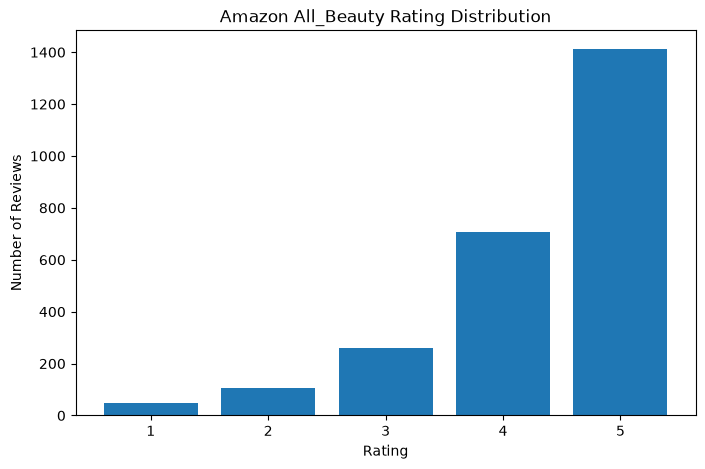

In [6]:
# ==========================================
# STEP 4.2: RATING DISTRIBUTION
# ==========================================

rating_counts = df["rating"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

plt.bar(
    rating_counts.index,
    rating_counts.values
)

plt.title("Amazon All_Beauty Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.xticks([1, 2, 3, 4, 5])

plt.show()

In [7]:
# ==========================================
# STEP 4.3: TIMESTAMP ANALYSIS
# ==========================================

df["event_time"] = pd.to_datetime(
    df["timestamp"],
    unit="ms",
    utc=True
)

print("Earliest Interaction:")
print(df["event_time"].min())

print("\nLatest Interaction:")
print(df["event_time"].max())

print("\nFirst Five Interactions:")
display(
    df[["user_id", "parent_asin", "rating", "event_time"]].head()
)

Earliest Interaction:
2018-12-13 03:17:11.249000+00:00

Latest Interaction:
2023-03-07 06:48:24.867000+00:00

First Five Interactions:


,user_id,parent_asin,rating,event_time
0,AFSKPY37N3C43SOI5IEXEK5JSIYA,B07J3GH1W1,5.0,2019-01-15 21:55:56.557000+00:00
1,AFSKPY37N3C43SOI5IEXEK5JSIYA,B07W397QG4,5.0,2020-06-28 13:53:42.858000+00:00
2,AFSKPY37N3C43SOI5IEXEK5JSIYA,B07KG1TWP5,5.0,2020-08-03 16:49:11.088000+00:00
3,AFSKPY37N3C43SOI5IEXEK5JSIYA,B08JTNQFZY,5.0,2021-04-08 17:50:19.785000+00:00
4,AFSKPY37N3C43SOI5IEXEK5JSIYA,B07SLFWZKN,3.0,2021-04-29 23:05:01.209000+00:00


In [8]:
# ==========================================
# STEP 5: BUILD USER INTERACTION SEQUENCES
# ==========================================

# Sort interactions chronologically
df = df.sort_values(
    ["user_id", "timestamp"]
).reset_index(drop=True)

# Group products by user
user_sequences = (
    df.groupby("user_id")["parent_asin"]
    .apply(list)
)

# Display sample sequences
print("Total Users:", len(user_sequences))

print("\nFirst 5 User Sequences:")

for user_id, products in user_sequences.head(5).items():
    print("\nUser:", user_id)
    print("Products:", products)
    print("Sequence Length:", len(products))

Total Users: 253

First 5 User Sequences:

User: AE23ZBUF2YVBQPH2NN6F5XSA3QYQ
Products: ['B089R7S73D', 'B081D2R47W', 'B087ZQK2G8', 'B08BF4BKKM', 'B0841WQNNZ', 'B08G5YVHQP', 'B08NTD1NM1', 'B08CVTNQP1', 'B08S3B8Y5G', 'B0998BD871']
Sequence Length: 10

User: AE3335XF4PMHSXKTW5B7N7EALG3Q
Products: ['B086ST4W1C', 'B08YJV9YL2', 'B08DXCVRNY', 'B07NPCT6L5', 'B07PCGSFGQ']
Sequence Length: 5

User: AE3KLVXGZPANXE5XLXYKHTVAZ3FQ
Products: ['B01N7A5AGF', 'B08QHP717Z', 'B08SQ31H8P', 'B0895XPZNT', 'B0863FZFPV', 'B086VRRD99', 'B0919R1CYT']
Sequence Length: 7

User: AE3LUVAAITFJIUTWBMRPHDQOCOFQ
Products: ['B085RQKWNF', 'B08FBHNBP1', 'B08C72C56Z', 'B08BB3P4VQ', 'B08C37KWRR', 'B08HCMNLKD', 'B0994HWXVV', 'B09SH1FD9S']
Sequence Length: 8

User: AE3PLZHW6NXWBMZ76TDVFQG2MJFA
Products: ['B07Z4CVTRP', 'B08BB3P4VQ', 'B08DXZ5VXB', 'B086N136NH', 'B07YNDWRCB', 'B08KWN77LW', 'B08SQZ1B3W', 'B01MSF13T1', 'B08S1LWF9V', 'B08RRSPNWV', 'B01M24DUXH', 'B08QVJ4NVD', 'B08P2DZB4X', 'B0BVQQ58G8', 'B0B4MR9BXN']
Sequence Length:

Minimum Sequence Length: 5
Maximum Sequence Length: 63
Average Sequence Length: 10.02
Median Sequence Length: 7.0


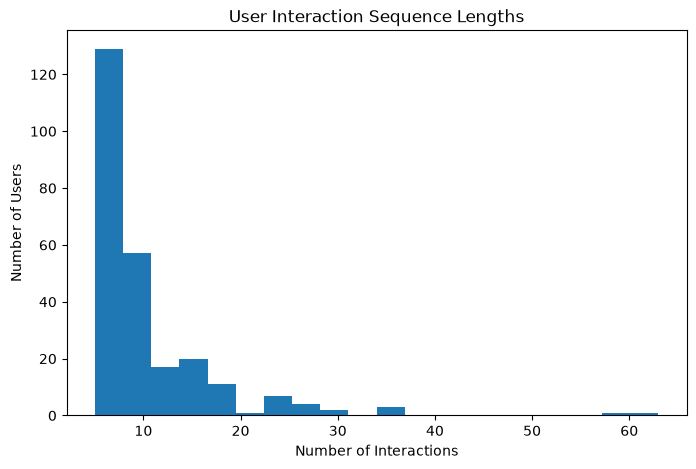

In [9]:
# ==========================================
# STEP 5.2: SEQUENCE LENGTH ANALYSIS
# ==========================================

sequence_lengths = user_sequences.apply(len)

print("Minimum Sequence Length:", sequence_lengths.min())
print("Maximum Sequence Length:", sequence_lengths.max())
print("Average Sequence Length:", round(sequence_lengths.mean(), 2))
print("Median Sequence Length:", sequence_lengths.median())

plt.figure(figsize=(8, 5))

plt.hist(sequence_lengths, bins=20)

plt.title("User Interaction Sequence Lengths")
plt.xlabel("Number of Interactions")
plt.ylabel("Number of Users")

plt.show()

In [10]:
# ==========================================
# STEP 6: CREATE NEXT-ITEM TRAINING DATA
# ==========================================

train_examples = []
validation_examples = []
test_examples = []

for user_id, products in user_sequences.items():

    # Need at least 3 interactions
    if len(products) < 3:
        continue

    # Training examples: earlier interactions
    for i in range(1, len(products) - 2):

        history = products[:i]
        target = products[i]

        train_examples.append({
            "user_id": user_id,
            "history": history,
            "target": target
        })

    # Validation: predict second-last product
    validation_examples.append({
        "user_id": user_id,
        "history": products[:-2],
        "target": products[-2]
    })

    # Testing: predict last product
    test_examples.append({
        "user_id": user_id,
        "history": products[:-1],
        "target": products[-1]
    })


# Convert examples into DataFrames
train_df = pd.DataFrame(train_examples)
validation_df = pd.DataFrame(validation_examples)
test_df = pd.DataFrame(test_examples)


print("Training Examples:", len(train_df))
print("Validation Examples:", len(validation_df))
print("Testing Examples:", len(test_df))

Training Examples: 1776
Validation Examples: 253
Testing Examples: 253


In [11]:
# ==========================================
# STEP 6.2: INSPECT TRAINING EXAMPLES
# ==========================================

print("TRAINING DATA")
display(train_df.head())

print("\nVALIDATION DATA")
display(validation_df.head())

print("\nTEST DATA")
display(test_df.head())

TRAINING DATA


,user_id,history,target
0,AE23ZBUF2YVBQPH2NN6F5XSA3QYQ,[B089R7S73D],B081D2R47W
1,AE23ZBUF2YVBQPH2NN6F5XSA3QYQ,"[B089R7S73D, B081D2R47W]",B087ZQK2G8
2,AE23ZBUF2YVBQPH2NN6F5XSA3QYQ,"[B089R7S73D, B081D2R47W, B087ZQK2G8]",B08BF4BKKM
3,AE23ZBUF2YVBQPH2NN6F5XSA3QYQ,"[B089R7S73D, B081D2R47W, B087ZQK2G8, B08BF4BKKM]",B0841WQNNZ
4,AE23ZBUF2YVBQPH2NN6F5XSA3QYQ,"[B089R7S73D, B081D2R47W, B087ZQK2G8, B08BF4BKK...",B08G5YVHQP



VALIDATION DATA


,user_id,history,target
0,AE23ZBUF2YVBQPH2NN6F5XSA3QYQ,"[B089R7S73D, B081D2R47W, B087ZQK2G8, B08BF4BKK...",B08S3B8Y5G
1,AE3335XF4PMHSXKTW5B7N7EALG3Q,"[B086ST4W1C, B08YJV9YL2, B08DXCVRNY]",B07NPCT6L5
2,AE3KLVXGZPANXE5XLXYKHTVAZ3FQ,"[B01N7A5AGF, B08QHP717Z, B08SQ31H8P, B0895XPZN...",B086VRRD99
3,AE3LUVAAITFJIUTWBMRPHDQOCOFQ,"[B085RQKWNF, B08FBHNBP1, B08C72C56Z, B08BB3P4V...",B0994HWXVV
4,AE3PLZHW6NXWBMZ76TDVFQG2MJFA,"[B07Z4CVTRP, B08BB3P4VQ, B08DXZ5VXB, B086N136N...",B0BVQQ58G8



TEST DATA


,user_id,history,target
0,AE23ZBUF2YVBQPH2NN6F5XSA3QYQ,"[B089R7S73D, B081D2R47W, B087ZQK2G8, B08BF4BKK...",B0998BD871
1,AE3335XF4PMHSXKTW5B7N7EALG3Q,"[B086ST4W1C, B08YJV9YL2, B08DXCVRNY, B07NPCT6L5]",B07PCGSFGQ
2,AE3KLVXGZPANXE5XLXYKHTVAZ3FQ,"[B01N7A5AGF, B08QHP717Z, B08SQ31H8P, B0895XPZN...",B0919R1CYT
3,AE3LUVAAITFJIUTWBMRPHDQOCOFQ,"[B085RQKWNF, B08FBHNBP1, B08C72C56Z, B08BB3P4V...",B09SH1FD9S
4,AE3PLZHW6NXWBMZ76TDVFQG2MJFA,"[B07Z4CVTRP, B08BB3P4VQ, B08DXZ5VXB, B086N136N...",B0B4MR9BXN


In [12]:
# ==========================================
# STEP 6.3: SAVE PROCESSED DATA
# ==========================================

PROCESSED_DATA_DIR = DATA_DIR / "processed"
PROCESSED_DATA_DIR.mkdir(exist_ok=True)

train_df.to_pickle(
    PROCESSED_DATA_DIR / "train.pkl"
)

validation_df.to_pickle(
    PROCESSED_DATA_DIR / "validation.pkl"
)

test_df.to_pickle(
    PROCESSED_DATA_DIR / "test.pkl"
)

print("All datasets saved successfully!")

print("Saved location:", PROCESSED_DATA_DIR)

All datasets saved successfully!
Saved location: C:\Users\HP\Documents\26 TIGER_Generative_Retrieval\data\processed


In [13]:
# ==========================================
# STEP 7: VERIFY PREPARED DATASETS
# ==========================================

from pathlib import Path
import pandas as pd

PROCESSED_DATA_DIR = DATA_DIR / "processed"

train_df = pd.read_pickle(
    PROCESSED_DATA_DIR / "train.pkl"
)

validation_df = pd.read_pickle(
    PROCESSED_DATA_DIR / "validation.pkl"
)

test_df = pd.read_pickle(
    PROCESSED_DATA_DIR / "test.pkl"
)

print("Training examples:", len(train_df))
print("Validation examples:", len(validation_df))
print("Testing examples:", len(test_df))

print("\nTraining data sample:")
display(train_df.head())

print("\nValidation data sample:")
display(validation_df.head())

print("\nTesting data sample:")
display(test_df.head())

Training examples: 1776
Validation examples: 253
Testing examples: 253

Training data sample:


,user_id,history,target
0,AE23ZBUF2YVBQPH2NN6F5XSA3QYQ,[B089R7S73D],B081D2R47W
1,AE23ZBUF2YVBQPH2NN6F5XSA3QYQ,"[B089R7S73D, B081D2R47W]",B087ZQK2G8
2,AE23ZBUF2YVBQPH2NN6F5XSA3QYQ,"[B089R7S73D, B081D2R47W, B087ZQK2G8]",B08BF4BKKM
3,AE23ZBUF2YVBQPH2NN6F5XSA3QYQ,"[B089R7S73D, B081D2R47W, B087ZQK2G8, B08BF4BKKM]",B0841WQNNZ
4,AE23ZBUF2YVBQPH2NN6F5XSA3QYQ,"[B089R7S73D, B081D2R47W, B087ZQK2G8, B08BF4BKK...",B08G5YVHQP



Validation data sample:


,user_id,history,target
0,AE23ZBUF2YVBQPH2NN6F5XSA3QYQ,"[B089R7S73D, B081D2R47W, B087ZQK2G8, B08BF4BKK...",B08S3B8Y5G
1,AE3335XF4PMHSXKTW5B7N7EALG3Q,"[B086ST4W1C, B08YJV9YL2, B08DXCVRNY]",B07NPCT6L5
2,AE3KLVXGZPANXE5XLXYKHTVAZ3FQ,"[B01N7A5AGF, B08QHP717Z, B08SQ31H8P, B0895XPZN...",B086VRRD99
3,AE3LUVAAITFJIUTWBMRPHDQOCOFQ,"[B085RQKWNF, B08FBHNBP1, B08C72C56Z, B08BB3P4V...",B0994HWXVV
4,AE3PLZHW6NXWBMZ76TDVFQG2MJFA,"[B07Z4CVTRP, B08BB3P4VQ, B08DXZ5VXB, B086N136N...",B0BVQQ58G8



Testing data sample:


,user_id,history,target
0,AE23ZBUF2YVBQPH2NN6F5XSA3QYQ,"[B089R7S73D, B081D2R47W, B087ZQK2G8, B08BF4BKK...",B0998BD871
1,AE3335XF4PMHSXKTW5B7N7EALG3Q,"[B086ST4W1C, B08YJV9YL2, B08DXCVRNY, B07NPCT6L5]",B07PCGSFGQ
2,AE3KLVXGZPANXE5XLXYKHTVAZ3FQ,"[B01N7A5AGF, B08QHP717Z, B08SQ31H8P, B0895XPZN...",B0919R1CYT
3,AE3LUVAAITFJIUTWBMRPHDQOCOFQ,"[B085RQKWNF, B08FBHNBP1, B08C72C56Z, B08BB3P4V...",B09SH1FD9S
4,AE3PLZHW6NXWBMZ76TDVFQG2MJFA,"[B07Z4CVTRP, B08BB3P4VQ, B08DXZ5VXB, B086N136N...",B0B4MR9BXN


In [14]:
# Check for empty histories and missing targets

for name, dataset in [
    ("Training", train_df),
    ("Validation", validation_df),
    ("Testing", test_df)
]:
    print(f"\n{name} checks")
    print("Missing values:", dataset.isnull().sum().sum())
    print(
        "Empty histories:",
        dataset["history"].apply(len).eq(0).sum()
    )
    print(
        "Missing targets:",
        dataset["target"].isnull().sum()
    )


Training checks
Missing values: 0
Empty histories: 0
Missing targets: 0

Validation checks
Missing values: 0
Empty histories: 0
Missing targets: 0

Testing checks
Missing values: 0
Empty histories: 0
Missing targets: 0


In [15]:
# ==========================================
# STEP 8: PRODUCT EMBEDDING PREPARATION
# ==========================================

# Get unique products from the dataset
products_df = (
    df[["parent_asin"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

print("Unique products:", len(products_df))

display(products_df.head(10))

Unique products: 356


,parent_asin
0,B089R7S73D
1,B081D2R47W
2,B087ZQK2G8
3,B08BF4BKKM
4,B0841WQNNZ
5,B08G5YVHQP
6,B08NTD1NM1
7,B08CVTNQP1
8,B08S3B8Y5G
9,B0998BD871


In [9]:
metadata_url = (
    "https://datarepo.eng.ucsd.edu/"
    "mcauley_group/data/amazon_2023/"
    "raw/meta_categories/meta_All_Beauty.jsonl.gz"
)

print("Corrected metadata URL:", metadata_url)

Corrected metadata URL: https://datarepo.eng.ucsd.edu/mcauley_group/data/amazon_2023/raw/meta_categories/meta_All_Beauty.jsonl.gz


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data"
RAW_DATA_DIR = DATA_DIR / "raw"
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
REPORTS_DIR = PROJECT_ROOT / "reports"

PROCESSED_DATA_DIR = DATA_DIR / "processed"

print("TIGER environment initialized!")

TIGER environment initialized!


In [3]:
df = pd.read_csv(
    RAW_DATA_DIR / "All_Beauty.csv.gz",
    compression="gzip"
)

products_df = (
    df[["parent_asin"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

target_product_ids = set(products_df["parent_asin"])

print("Total interactions:", len(df))
print("Unique products:", len(target_product_ids))

Total interactions: 2535
Unique products: 356


In [4]:
import sys
print(sys.executable)

C:\Users\HP\Documents\26 TIGER_Generative_Retrieval\.venv\Scripts\python.exe


In [5]:
import ssl
import urllib.request

print("OpenSSL:", ssl.OPENSSL_VERSION)
print("Default certificate paths:", ssl.get_default_verify_paths())

try:
    with urllib.request.urlopen(
        "https://www.google.com",
        timeout=15
    ) as response:
        print("HTTPS status:", response.status)
        print("SSL connection successful!")
except Exception as error:
    print("SSL connection failed:", repr(error))

OpenSSL: OpenSSL 3.0.13 30 Jan 2024
Default certificate paths: DefaultVerifyPaths(cafile=None, capath=None, openssl_cafile_env='SSL_CERT_FILE', openssl_cafile='C:\\Program Files\\Common Files\\SSL/cert.pem', openssl_capath_env='SSL_CERT_DIR', openssl_capath='C:\\Program Files\\Common Files\\SSL/certs')
HTTPS status: 200
SSL connection successful!


In [8]:
import ssl
import certifi
import urllib.request

print("Certificate bundle:", certifi.where())

secure_context = ssl.create_default_context(
    cafile=certifi.where()
)

try:
    with urllib.request.urlopen(
        metadata_url,
        context=secure_context,
        timeout=30
    ) as response:
        print("Connection successful!")
        print("HTTP status:", response.status)

except Exception as error:
    print("Connection failed:", repr(error))

Certificate bundle: C:\Users\HP\Documents\26 TIGER_Generative_Retrieval\.venv\Lib\site-packages\certifi\cacert.pem
Connection failed: <HTTPError 404: 'Not Found'>


In [11]:
import urllib.request

metadata_url = (
    "https://huggingface.co/datasets/"
    "McAuley-Lab/Amazon-Reviews-2023/"
    "resolve/main/raw/meta_categories/"
    "meta_All_Beauty.jsonl"
)

request = urllib.request.Request(
    metadata_url,
    method="HEAD"
)

try:
    with urllib.request.urlopen(
        request,
        context=secure_context,
        timeout=30
    ) as response:
        print("HTTP Status:", response.status)
        print("Content Length:", response.headers.get("Content-Length"))
        print("Hugging Face connection successful!")

except Exception as error:
    print("Connection failed:", repr(error))

HTTP Status: 200
Content Length: 212990142
Hugging Face connection successful!


In [12]:
# ==========================================
# STEP 8.8: STREAM PRODUCT METADATA
# ==========================================

import gzip
import json
import ssl
import certifi
import urllib.request

metadata_url = (
    "https://huggingface.co/datasets/"
    "McAuley-Lab/Amazon-Reviews-2023/"
    "resolve/main/raw/meta_categories/"
    "meta_All_Beauty.jsonl"
)

secure_context = ssl.create_default_context(
    cafile=certifi.where()
)

metadata_records = []

print("Starting metadata streaming...")

request = urllib.request.Request(
    metadata_url,
    headers={"Accept-Encoding": "identity"}
)

with urllib.request.urlopen(
    request,
    context=secure_context,
    timeout=60
) as response:

    for line_number, line in enumerate(response, start=1):

        if not line.strip():
            continue

        record = json.loads(line)

        product_id = record.get("parent_asin")

        if product_id in target_product_ids:
            metadata_records.append(record)

        if line_number % 100000 == 0:
            print(
                f"Processed {line_number:,} records | "
                f"Matched: {len(metadata_records)}"
            )

print("\nMetadata processing completed!")
print("Matched products:", len(metadata_records))
print("Expected products:", len(target_product_ids))

Starting metadata streaming...
Processed 100,000 records | Matched: 349

Metadata processing completed!
Matched products: 356
Expected products: 356


In [13]:
metadata_path = RAW_DATA_DIR / "product_metadata_subset.jsonl"

with open(metadata_path, "w", encoding="utf-8") as file:
    for record in metadata_records:
        file.write(
            json.dumps(record, ensure_ascii=False) + "\n"
        )

print("Matching metadata saved!")
print("File:", metadata_path)

Matching metadata saved!
File: C:\Users\HP\Documents\26 TIGER_Generative_Retrieval\data\raw\product_metadata_subset.jsonl


In [14]:
import json

metadata_path = RAW_DATA_DIR / "product_metadata_subset.jsonl"

with open(metadata_path, "r", encoding="utf-8") as file:
    metadata_records = [json.loads(line) for line in file if line.strip()]

metadata_df = pd.DataFrame(metadata_records)

print("Matched metadata records:", len(metadata_df))
print("\nAvailable columns:")
print(metadata_df.columns.tolist())

print("\nSample product metadata:")
display(metadata_df.head(3))

Matched metadata records: 356

Available columns:
['main_category', 'title', 'average_rating', 'rating_number', 'features', 'description', 'price', 'images', 'videos', 'store', 'categories', 'details', 'parent_asin', 'bought_together']

Sample product metadata:


,main_category,title,average_rating,rating_number,features,description,price,images,videos,store,categories,details,parent_asin,bought_together
0,All Beauty,Organic Sweet Almond Oil and Fractionated Coco...,4.5,167,[],[],NaN,[{'thumb': 'https://m.media-amazon.com/images/...,[{'title': 'Organic Sweet Almond Oil and Cocon...,Shiny Leaf,[],"{'Brand': 'Shiny Leaf', 'Scent': 'Almond Oil a...",B08LYT4Q2X,None
1,All Beauty,"Empty Brown Glass Spray Bottles2-Pack, Refilla...",3.7,53,[],[],NaN,[{'thumb': 'https://m.media-amazon.com/images/...,"[{'title': 'Good Quality for the Price', 'url'...",Cherry,[],"{'Brand': 'Cherry', 'Material': 'Glass', 'Capa...",B089CSF11Y,None
2,All Beauty,JPNK 4PCS Anti-Static Detangling Fine & Wide T...,4.1,58,[],[],NaN,[{'thumb': 'https://m.media-amazon.com/images/...,[],JPNK,[],"{'Material': 'Plastic', 'Brand': 'JPNK', 'Hair...",B081ZN3TD5,None


In [15]:
print("Interaction products:", df["parent_asin"].nunique())
print("Metadata products:", metadata_df["parent_asin"].nunique())

print("\nMissing values in metadata:")
print(metadata_df.isnull().sum())

print("\nProduct title examples:")
display(metadata_df[["parent_asin", "title"]].head(5))

Interaction products: 356
Metadata products: 356

Missing values in metadata:
main_category        0
title                0
average_rating       0
rating_number        0
features             0
description          0
price              299
images               0
videos               0
store               13
categories           0
details              0
parent_asin          0
bought_together    356
dtype: int64

Product title examples:


,parent_asin,title
0,B08LYT4Q2X,Organic Sweet Almond Oil and Fractionated Coco...
1,B089CSF11Y,"Empty Brown Glass Spray Bottles2-Pack, Refilla..."
2,B081ZN3TD5,JPNK 4PCS Anti-Static Detangling Fine & Wide T...
3,B08WF29DM9,TULA Probiotic Skin Care Supersize 24-7 Moistu...
4,B08HMLXW65,"Claw Hair Clips, IKOCO 6 Pack Jaw Clips Stylis..."


In [16]:
def clean_text(value):
    """Convert metadata values into readable text."""
    if value is None:
        return ""

    if isinstance(value, list):
        return " ".join(clean_text(item) for item in value)

    if isinstance(value, dict):
        return " ".join(
            f"{key}: {clean_text(item)}"
            for key, item in value.items()
        )

    return str(value).strip()


# Create one text representation for each product
metadata_df["product_text"] = metadata_df.apply(
    lambda row: " ".join(
        part for part in [
            clean_text(row["title"]),
            clean_text(row["description"]),
            clean_text(row["features"]),
            clean_text(row["categories"]),
        ]
        if part
    ),
    axis=1
)

# Check the result
print("Total products:", len(metadata_df))
print("Empty product texts:", (metadata_df["product_text"].str.strip() == "").sum())

print("\nExample product text:")
print(metadata_df.loc[0, "product_text"][:1000])

Total products: 356
Empty product texts: 0

Example product text:
Organic Sweet Almond Oil and Fractionated Coconut Oil Bundle for Hair and Skin, 100% Pure and Natural, Hexane-Free, Moisturizing, For Healthy Skin, Silky Hair, Multiuse Body Oil, 16 fl. Oz X 2


In [17]:
product_text_path = PROCESSED_DATA_DIR / "product_text.csv"

metadata_df[
    ["parent_asin", "title", "product_text"]
].to_csv(product_text_path, index=False)

print("Product text saved successfully!")
print("File:", product_text_path)
print("Total products:", len(metadata_df))

Product text saved successfully!
File: C:\Users\HP\Documents\26 TIGER_Generative_Retrieval\data\processed\product_text.csv
Total products: 356


In [18]:
from sentence_transformers import SentenceTransformer

MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"

print("Loading embedding model...")

embedding_model = SentenceTransformer(
    MODEL_NAME,
    device="cpu"
)

print("Model loaded successfully!")

C:\Users\HP\Documents\26 TIGER_Generative_Retrieval\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading embedding model...


C:\Users\HP\Documents\26 TIGER_Generative_Retrieval\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\HP\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
C:\Users\HP\Documents\26 TIGER_Generative_Retrieval\.venv\Lib\site-packages

Model loaded successfully!


In [19]:
# Prepare product texts
product_texts = metadata_df["product_text"].tolist()

# Generate embeddings in small batches
print("Generating product embeddings...")

product_embeddings = embedding_model.encode(
    product_texts,
    batch_size=16,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

print("\nEmbedding generation completed!")
print("Embedding shape:", product_embeddings.shape)
print("Data type:", product_embeddings.dtype)

Generating product embeddings...


Batches: 100%|██████████| 23/23 [00:05<00:00,  3.87it/s]


Embedding generation completed!
Embedding shape: (356, 384)
Data type: float32


In [20]:
product_texts = metadata_df["product_text"].tolist()

print("Generating embeddings...")

product_embeddings = embedding_model.encode(
    product_texts,
    batch_size=16,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

print("\nEmbedding generation completed!")
print("Embedding shape:", product_embeddings.shape)
print("Data type:", product_embeddings.dtype)

Generating embeddings...


Batches: 100%|██████████| 23/23 [00:06<00:00,  3.79it/s]


Embedding generation completed!
Embedding shape: (356, 384)
Data type: float32


In [22]:
# Save product IDs as Unicode strings
product_ids = metadata_df["parent_asin"].astype(str).to_numpy(dtype=str)

np.save(product_ids_path, product_ids)

# Load and verify both files
loaded_embeddings = np.load(embedding_path)
loaded_product_ids = np.load(product_ids_path)

print("Embeddings saved:", loaded_embeddings.shape)
print("Product IDs saved:", len(loaded_product_ids))
print("First product ID:", loaded_product_ids[0])
print("All embedding values finite:", np.isfinite(loaded_embeddings).all())
print("Both files verified successfully!")

Embeddings saved: (356, 384)
Product IDs saved: 356
First product ID: B08LYT4Q2X
All embedding values finite: True
Both files verified successfully!


In [23]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

# Calculate similarity between all products
similarity_matrix = cosine_similarity(product_embeddings)

print("Similarity matrix shape:", similarity_matrix.shape)
print("Minimum similarity:", similarity_matrix.min())
print("Maximum similarity:", similarity_matrix.max())

# Select one product
product_index = 0

# Find the 5 most similar products
similarity_scores = similarity_matrix[product_index].copy()

# Exclude the selected product itself
similarity_scores[product_index] = -1

top_indices = np.argsort(similarity_scores)[-5:][::-1]

print("\nSelected product:")
print(metadata_df.iloc[product_index]["title"])

print("\nTop 5 similar products:")

for index in top_indices:
    print(
        f"\nSimilarity: {similarity_scores[index]:.4f}"
        f"\nProduct: {metadata_df.iloc[index]['title']}"
    )

Similarity matrix shape: (356, 356)
Minimum similarity: -0.18879716
Maximum similarity: 1.0000006

Selected product:
Organic Sweet Almond Oil and Fractionated Coconut Oil Bundle for Hair and Skin, 100% Pure and Natural, Hexane-Free, Moisturizing, For Healthy Skin, Silky Hair, Multiuse Body Oil, 16 fl. Oz X 2

Top 5 similar products:

Similarity: 0.7852
Product: Claireceuticals Sweet Almond Oil for Hair, Face & Skin - Organic Almond Oil for Skin - Pure Almond Oil Moisturizer for Dry Skin - Facial Moisturizer for Women - Ideal Dandruff Remover - 1.69 Fl Oz

Similarity: 0.6717
Product: BeautyStat Cosmetics Universal Moisture Essence, 100% Pure Squalane, Face Oil, Moisturizer, 30ml, 1oz

Similarity: 0.6396
Product: Aloe Vera Gel 100% Natural Moisturisers - Pure Organic Fresh Soothing Aloe-Vera Moisturizing Gel Skin Hair, Aloe Leaf Wash-free Clean After Sun Face Body (8.8 oz)

Similarity: 0.6380
Product: Laloirelle Luminous Face Oil - Organic Pomegranate Oil, Cacao Oil Infused W/Brightening

In [24]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# Reproducibility
torch.manual_seed(42)

# Model configuration
INPUT_DIM = 384
HIDDEN_DIM = 256
LATENT_DIM = 64
NUM_QUANTIZERS = 3
CODEBOOK_SIZE = 16
COMMITMENT_BETA = 0.25


class ResidualVectorQuantizer(nn.Module):

    def __init__(self, num_quantizers, codebook_size, embedding_dim):
        super().__init__()

        self.num_quantizers = num_quantizers
        self.codebook_size = codebook_size

        self.codebooks = nn.ModuleList([
            nn.Embedding(codebook_size, embedding_dim)
            for _ in range(num_quantizers)
        ])

        for codebook in self.codebooks:
            nn.init.uniform_(codebook.weight, -1 / codebook_size,
                             1 / codebook_size)

    def forward(self, z):

        residual = z
        quantized_sum = torch.zeros_like(z)

        all_indices = []
        total_codebook_loss = 0.0
        total_commitment_loss = 0.0

        for codebook in self.codebooks:

            distances = (
                residual.pow(2).sum(dim=1, keepdim=True)
                - 2 * residual @ codebook.weight.T
                + codebook.weight.pow(2).sum(dim=1)
            )

            indices = torch.argmin(distances, dim=1)

            quantized = codebook(indices)

            codebook_loss = F.mse_loss(
                quantized, residual.detach()
            )

            commitment_loss = F.mse_loss(
                residual, quantized.detach()
            )

            quantized_st = residual + (
                quantized - residual
            ).detach()

            quantized_sum = quantized_sum + quantized_st

            total_codebook_loss += codebook_loss
            total_commitment_loss += commitment_loss

            all_indices.append(indices)

            residual = residual - quantized.detach()

        quantization_loss = (
            total_codebook_loss
            + COMMITMENT_BETA * total_commitment_loss
        )

        semantic_ids = torch.stack(all_indices, dim=1)

        return quantized_sum, semantic_ids, quantization_loss


class RQVAE(nn.Module):

    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(INPUT_DIM, HIDDEN_DIM),
            nn.ReLU(),
            nn.Linear(HIDDEN_DIM, LATENT_DIM)
        )

        self.quantizer = ResidualVectorQuantizer(
            NUM_QUANTIZERS,
            CODEBOOK_SIZE,
            LATENT_DIM
        )

        self.decoder = nn.Sequential(
            nn.Linear(LATENT_DIM, HIDDEN_DIM),
            nn.ReLU(),
            nn.Linear(HIDDEN_DIM, INPUT_DIM)
        )

    def forward(self, x):

        z = self.encoder(x)

        quantized, semantic_ids, quantization_loss = (
            self.quantizer(z)
        )

        reconstruction = self.decoder(quantized)

        reconstruction_loss = F.mse_loss(
            reconstruction, x
        )

        total_loss = reconstruction_loss + quantization_loss

        return {
            "reconstruction": reconstruction,
            "semantic_ids": semantic_ids,
            "reconstruction_loss": reconstruction_loss,
            "quantization_loss": quantization_loss,
            "total_loss": total_loss
        }


# Initialize model
rqvae_model = RQVAE()

print("RQ-VAE architecture initialized!")
print("Total parameters:", sum(
    p.numel() for p in rqvae_model.parameters()
))

RQ-VAE architecture initialized!
Total parameters: 233408


In [25]:
# Convert product embeddings into a PyTorch tensor
embedding_tensor = torch.tensor(
    product_embeddings,
    dtype=torch.float32
)

# Set model to evaluation mode
rqvae_model.eval()

# Run a forward pass without calculating gradients
with torch.no_grad():
    output = rqvae_model(embedding_tensor)

print("Input shape:", embedding_tensor.shape)

print(
    "Reconstructed shape:",
    output["reconstruction"].shape
)

print(
    "Semantic ID shape:",
    output["semantic_ids"].shape
)

print(
    "Reconstruction loss:",
    output["reconstruction_loss"].item()
)

print(
    "Quantization loss:",
    output["quantization_loss"].item()
)

print(
    "Total loss:",
    output["total_loss"].item()
)

print("\nFirst 5 Semantic IDs:")
print(output["semantic_ids"][:5])

Input shape: torch.Size([356, 384])
Reconstructed shape: torch.Size([356, 384])
Semantic ID shape: torch.Size([356, 3])
Reconstruction loss: 0.004861116409301758
Quantization loss: 0.010825788602232933
Total loss: 0.01568690501153469

First 5 Semantic IDs:
tensor([[ 7,  4, 14],
        [ 7,  4,  0],
        [ 7,  4, 14],
        [ 7,  4,  0],
        [ 7,  4,  0]])


In [26]:
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)

train_loader = DataLoader(
    TensorDataset(embedding_tensor),
    batch_size=32,
    shuffle=True
)

optimizer = torch.optim.Adam(
    rqvae_model.parameters(),
    lr=0.001
)

EPOCHS = 50
training_losses = []

rqvae_model.train()

for epoch in range(EPOCHS):
    epoch_loss = 0.0

    for (batch,) in train_loader:
        optimizer.zero_grad()

        output = rqvae_model(batch)
        loss = output["total_loss"]

        loss.backward()
        optimizer.step()

        epoch_loss += loss.item() * batch.size(0)

    average_loss = epoch_loss / len(embedding_tensor)
    training_losses.append(average_loss)

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(
            f"Epoch {epoch + 1:02d}/{EPOCHS} "
            f"| Loss: {average_loss:.6f}"
        )

print("\nRQ-VAE training completed!")

Epoch 01/50 | Loss: 0.007814
Epoch 05/50 | Loss: 0.002741
Epoch 10/50 | Loss: 0.003521
Epoch 15/50 | Loss: 0.003378
Epoch 20/50 | Loss: 0.003355
Epoch 25/50 | Loss: 0.002771
Epoch 30/50 | Loss: 0.002630
Epoch 35/50 | Loss: 0.002915
Epoch 40/50 | Loss: 0.002725
Epoch 45/50 | Loss: 0.002739
Epoch 50/50 | Loss: 0.002885

RQ-VAE training completed!


In [27]:
# Generate Semantic IDs after training
rqvae_model.eval()

with torch.no_grad():
    final_output = rqvae_model(embedding_tensor)

semantic_ids = final_output["semantic_ids"].cpu().numpy()

print("Semantic ID shape:", semantic_ids.shape)

# Analyze each codebook
for i in range(NUM_QUANTIZERS):

    used_codes, counts = np.unique(
        semantic_ids[:, i],
        return_counts=True
    )

    print(f"\nCodebook {i + 1}")
    print("Total available codes:", CODEBOOK_SIZE)
    print("Used codes:", len(used_codes))
    print("Unused codes:", CODEBOOK_SIZE - len(used_codes))
    print("Code distribution:")

    for code, count in zip(used_codes, counts):
        print(f"  Code {code:02d}: {count} products")

Semantic ID shape: (356, 3)

Codebook 1
Total available codes: 16
Used codes: 1
Unused codes: 15
Code distribution:
  Code 07: 356 products

Codebook 2
Total available codes: 16
Used codes: 2
Unused codes: 14
Code distribution:
  Code 04: 188 products
  Code 09: 168 products

Codebook 3
Total available codes: 16
Used codes: 2
Unused codes: 14
Code distribution:
  Code 09: 150 products
  Code 14: 206 products


In [28]:
from sklearn.cluster import KMeans

# Create a fresh RQ-VAE model
rqvae_kmeans = RQVAE()

# Generate initial latent vectors
rqvae_kmeans.eval()

with torch.no_grad():
    initial_latents = rqvae_kmeans.encoder(embedding_tensor)

# Initialize codebooks using sequential residual K-Means
residuals = initial_latents.clone()

for i, codebook in enumerate(rqvae_kmeans.quantizer.codebooks):

    kmeans = KMeans(
        n_clusters=CODEBOOK_SIZE,
        random_state=42,
        n_init=10
    )

    kmeans.fit(residuals.cpu().numpy())

    centers = torch.tensor(
        kmeans.cluster_centers_,
        dtype=torch.float32
    )

    with torch.no_grad():
        codebook.weight.copy_(centers)

    # Calculate residual for the next codebook
    labels = kmeans.labels_

    residuals = residuals - centers[labels]

    print(
        f"Codebook {i + 1} initialized "
        f"| Clusters: {len(set(labels))}"
    )

print("\nK-Means initialization completed!")

Codebook 1 initialized | Clusters: 16
Codebook 2 initialized | Clusters: 16
Codebook 3 initialized | Clusters: 16

K-Means initialization completed!


In [29]:
# Fresh optimizer for the K-Means initialized model
optimizer_kmeans = torch.optim.Adam(
    rqvae_kmeans.parameters(),
    lr=0.001
)

training_losses_kmeans = []

rqvae_kmeans.train()

for epoch in range(50):
    epoch_loss = 0.0

    for (batch,) in train_loader:
        optimizer_kmeans.zero_grad()

        output = rqvae_kmeans(batch)
        loss = output["total_loss"]

        loss.backward()
        optimizer_kmeans.step()

        epoch_loss += loss.item() * batch.size(0)

    average_loss = epoch_loss / len(embedding_tensor)
    training_losses_kmeans.append(average_loss)

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(
            f"Epoch {epoch + 1:02d}/50 "
            f"| Loss: {average_loss:.6f}"
        )

print("\nK-Means initialized RQ-VAE training completed!")

Epoch 01/50 | Loss: 0.003688
Epoch 05/50 | Loss: 0.002338
Epoch 10/50 | Loss: 0.002511
Epoch 15/50 | Loss: 0.002666
Epoch 20/50 | Loss: 0.002856
Epoch 25/50 | Loss: 0.002954
Epoch 30/50 | Loss: 0.003055
Epoch 35/50 | Loss: 0.003186
Epoch 40/50 | Loss: 0.003339
Epoch 45/50 | Loss: 0.003337
Epoch 50/50 | Loss: 0.003471

K-Means initialized RQ-VAE training completed!


In [30]:
# Generate Semantic IDs after K-Means training
rqvae_kmeans.eval()

with torch.no_grad():
    kmeans_output = rqvae_kmeans(embedding_tensor)

semantic_ids_kmeans = (
    kmeans_output["semantic_ids"].cpu().numpy()
)

print("Semantic ID shape:", semantic_ids_kmeans.shape)

for i in range(NUM_QUANTIZERS):

    used_codes, counts = np.unique(
        semantic_ids_kmeans[:, i],
        return_counts=True
    )

    print(f"\nCodebook {i + 1}")
    print("Available codes:", CODEBOOK_SIZE)
    print("Used codes:", len(used_codes))
    print("Unused codes:", CODEBOOK_SIZE - len(used_codes))
    print("Utilization:", f"{len(used_codes)/CODEBOOK_SIZE*100:.2f}%")

    for code, count in zip(used_codes, counts):
        print(f"  Code {code:02d}: {count} products")

Semantic ID shape: (356, 3)

Codebook 1
Available codes: 16
Used codes: 15
Unused codes: 1
Utilization: 93.75%
  Code 00: 17 products
  Code 01: 21 products
  Code 02: 17 products
  Code 03: 36 products
  Code 04: 46 products
  Code 05: 22 products
  Code 06: 16 products
  Code 07: 17 products
  Code 08: 11 products
  Code 09: 7 products
  Code 11: 45 products
  Code 12: 23 products
  Code 13: 14 products
  Code 14: 39 products
  Code 15: 25 products

Codebook 2
Available codes: 16
Used codes: 16
Unused codes: 0
Utilization: 100.00%
  Code 00: 22 products
  Code 01: 24 products
  Code 02: 8 products
  Code 03: 37 products
  Code 04: 25 products
  Code 05: 16 products
  Code 06: 26 products
  Code 07: 26 products
  Code 08: 26 products
  Code 09: 27 products
  Code 10: 10 products
  Code 11: 30 products
  Code 12: 20 products
  Code 13: 25 products
  Code 14: 18 products
  Code 15: 16 products

Codebook 3
Available codes: 16
Used codes: 16
Unused codes: 0
Utilization: 100.00%
  Code 00:

In [31]:
# Count unique Semantic ID combinations
unique_ids, counts = np.unique(
    semantic_ids_kmeans,
    axis=0,
    return_counts=True
)

print("Total products:", len(semantic_ids_kmeans))
print("Unique Semantic IDs:", len(unique_ids))
print("Duplicate ID assignments:", len(semantic_ids_kmeans) - len(unique_ids))
print("Unique ID percentage:", f"{len(unique_ids) / len(semantic_ids_kmeans) * 100:.2f}%")

# Find products sharing the same Semantic ID
semantic_df = metadata_df[
    ["parent_asin", "title"]
].copy()

semantic_df["semantic_id"] = [
    tuple(row) for row in semantic_ids_kmeans
]

duplicate_groups = (
    semantic_df.groupby("semantic_id")
    .filter(lambda group: len(group) > 1)
    .sort_values("semantic_id")
)

print("\nProducts sharing Semantic IDs:")
display(duplicate_groups.head(20))

Total products: 356
Unique Semantic IDs: 300
Duplicate ID assignments: 56
Unique ID percentage: 84.27%

Products sharing Semantic IDs:


,parent_asin,title,semantic_id
159,B086YBQ8M7,BJÖRN HALL Nurse Headband with Buttons for Fac...,"(1, 0, 15)"
133,B088FBNQXW,MainBasics Headband with Buttons for Face Mask...,"(1, 0, 15)"
19,B08BS3WDPJ,"Karuna Oh, Glow On Face Mask Sheet, Skincare a...","(1, 3, 2)"
262,B08GYJY8F2,Karuna 7 Days of Glow - Face & Eye Mask Variet...,"(1, 3, 2)"
134,B08XZDXTG2,WIS Hyaluronic Acid Facial Masks for Women Ant...,"(1, 8, 8)"
166,B08PVH18Z6,WIS Hyaluronic Acid Moisturizing Facial Mask f...,"(1, 8, 8)"
4,B08HMLXW65,"Claw Hair Clips, IKOCO 6 Pack Jaw Clips Stylis...","(2, 1, 15)"
85,B07XVNJFNF,"100pcs Premium Quality Hair Clips, 20 Glossy C...","(2, 1, 15)"
161,B09G22586Y,"Automatic Curling Iron, Rechargeable Cordless ...","(2, 4, 15)"
110,B08NPBQR9L,"3 Barrel Curling Iron, Milantia 3/4 Inch Mini ...","(2, 4, 15)"


In [32]:
# Analyze Semantic ID collision distribution

collision_counts = (
    semantic_df.groupby("semantic_id")
    .size()
    .sort_values(ascending=False)
)

print("Total Semantic ID combinations:", len(collision_counts))
print("IDs used by multiple products:", (collision_counts > 1).sum())
print("Maximum products sharing one ID:", collision_counts.max())

print("\nMost frequently shared Semantic IDs:")
display(collision_counts[collision_counts > 1].head(15))

Total Semantic ID combinations: 300
IDs used by multiple products: 46
Maximum products sharing one ID: 6

Most frequently shared Semantic IDs:


semantic_id
(3, 5, 11)     6
(4, 7, 7)      3
(11, 3, 13)    3
(11, 4, 14)    3
(12, 9, 6)     3
(13, 6, 11)    3
(14, 6, 2)     3
(4, 11, 11)    2
(4, 14, 15)    2
(6, 4, 8)      2
(3, 0, 11)     2
(3, 13, 5)     2
(6, 15, 13)    2
(3, 13, 11)    2
(2, 1, 15)     2
dtype: int64

In [33]:
import torch.nn.functional as F

rqvae_kmeans.eval()

with torch.no_grad():
    evaluation_output = rqvae_kmeans(embedding_tensor)

    reconstructed = evaluation_output["reconstruction"]

    mse = F.mse_loss(
        reconstructed,
        embedding_tensor
    ).item()

    cosine_scores = F.cosine_similarity(
        embedding_tensor,
        reconstructed,
        dim=1
    )

    mean_cosine = cosine_scores.mean().item()
    min_cosine = cosine_scores.min().item()
    max_cosine = cosine_scores.max().item()

print("RQ-VAE Reconstruction Evaluation")
print("--------------------------------")
print(f"Reconstruction MSE: {mse:.6f}")
print(f"Mean Cosine Similarity: {mean_cosine:.6f}")
print(f"Minimum Cosine Similarity: {min_cosine:.6f}")
print(f"Maximum Cosine Similarity: {max_cosine:.6f}")

RQ-VAE Reconstruction Evaluation
--------------------------------
Reconstruction MSE: 0.001151
Mean Cosine Similarity: 0.743856
Minimum Cosine Similarity: 0.385399
Maximum Cosine Similarity: 0.934267


In [34]:
# Save trained K-Means RQ-VAE
model_path = ARTIFACTS_DIR / "rqvae_kmeans_v1.pth"

torch.save(
    {
        "model_state_dict": rqvae_kmeans.state_dict(),
        "config": {
            "input_dim": INPUT_DIM,
            "hidden_dim": HIDDEN_DIM,
            "latent_dim": LATENT_DIM,
            "num_quantizers": NUM_QUANTIZERS,
            "codebook_size": CODEBOOK_SIZE,
            "commitment_beta": COMMITMENT_BETA
        },
        "training_losses": training_losses_kmeans,
        "semantic_ids": semantic_ids_kmeans,
        "reconstruction_mse": mse,
        "mean_cosine_similarity": mean_cosine
    },
    model_path
)

# Save Semantic IDs separately
semantic_ids_path = ARTIFACTS_DIR / "semantic_ids_kmeans_v1.npy"

np.save(semantic_ids_path, semantic_ids_kmeans)

print("Experiment 2 saved successfully!")
print("Model:", model_path)
print("Semantic IDs:", semantic_ids_path)

Experiment 2 saved successfully!
Model: C:\Users\HP\Documents\26 TIGER_Generative_Retrieval\artifacts\rqvae_kmeans_v1.pth
Semantic IDs: C:\Users\HP\Documents\26 TIGER_Generative_Retrieval\artifacts\semantic_ids_kmeans_v1.npy


In [35]:
# Experiment 3 configuration

CODEBOOK_SIZE_EXP3 = 32

print("Experiment 3 Configuration")
print("---------------------------")
print("Input dimension:", INPUT_DIM)
print("Latent dimension:", LATENT_DIM)
print("Number of quantizers:", NUM_QUANTIZERS)
print("Codebook size:", CODEBOOK_SIZE_EXP3)
print(
    "Possible Semantic ID combinations:",
    CODEBOOK_SIZE_EXP3 ** NUM_QUANTIZERS
)

Experiment 3 Configuration
---------------------------
Input dimension: 384
Latent dimension: 64
Number of quantizers: 3
Codebook size: 32
Possible Semantic ID combinations: 32768


In [36]:
class RQVAE_Exp3(nn.Module):

    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(INPUT_DIM, HIDDEN_DIM),
            nn.ReLU(),
            nn.Linear(HIDDEN_DIM, LATENT_DIM)
        )

        self.quantizer = ResidualVectorQuantizer(
            NUM_QUANTIZERS,
            CODEBOOK_SIZE_EXP3,
            LATENT_DIM
        )

        self.decoder = nn.Sequential(
            nn.Linear(LATENT_DIM, HIDDEN_DIM),
            nn.ReLU(),
            nn.Linear(HIDDEN_DIM, INPUT_DIM)
        )

    def forward(self, x):

        z = self.encoder(x)

        quantized, semantic_ids, quantization_loss = (
            self.quantizer(z)
        )

        reconstruction = self.decoder(quantized)

        reconstruction_loss = F.mse_loss(
            reconstruction, x
        )

        total_loss = reconstruction_loss + quantization_loss

        return {
            "reconstruction": reconstruction,
            "semantic_ids": semantic_ids,
            "reconstruction_loss": reconstruction_loss,
            "quantization_loss": quantization_loss,
            "total_loss": total_loss
        }


torch.manual_seed(42)

rqvae_exp3 = RQVAE_Exp3()

print("Experiment 3 model initialized!")
print(
    "Codebook sizes:",
    [codebook.num_embeddings
     for codebook in rqvae_exp3.quantizer.codebooks]
)

print(
    "Total parameters:",
    sum(p.numel() for p in rqvae_exp3.parameters())
)

Experiment 3 model initialized!
Codebook sizes: [32, 32, 32]
Total parameters: 236480


In [37]:
from sklearn.cluster import KMeans

# Get initial latent vectors
rqvae_exp3.eval()

with torch.no_grad():
    latents_exp3 = rqvae_exp3.encoder(embedding_tensor)

# Sequential residual K-Means initialization
residuals_exp3 = latents_exp3.clone()

for i, codebook in enumerate(rqvae_exp3.quantizer.codebooks):

    kmeans = KMeans(
        n_clusters=CODEBOOK_SIZE_EXP3,
        random_state=42,
        n_init=10
    )

    kmeans.fit(residuals_exp3.cpu().numpy())

    centers = torch.tensor(
        kmeans.cluster_centers_,
        dtype=torch.float32
    )

    with torch.no_grad():
        codebook.weight.copy_(centers)

    labels = kmeans.labels_
    residuals_exp3 = residuals_exp3 - centers[labels]

    print(
        f"Codebook {i + 1} initialized "
        f"| Clusters: {len(set(labels))}"
    )

print("\nExperiment 3 K-Means initialization completed!")

Codebook 1 initialized | Clusters: 32
Codebook 2 initialized | Clusters: 32
Codebook 3 initialized | Clusters: 32

Experiment 3 K-Means initialization completed!


In [38]:
from sklearn.cluster import KMeans

rqvae_exp3.eval()

with torch.no_grad():
    latents_exp3 = rqvae_exp3.encoder(embedding_tensor)

residuals_exp3 = latents_exp3.clone()

for i, codebook in enumerate(rqvae_exp3.quantizer.codebooks):

    kmeans = KMeans(
        n_clusters=CODEBOOK_SIZE_EXP3,
        random_state=42,
        n_init=10
    )

    kmeans.fit(residuals_exp3.cpu().numpy())

    centers = torch.tensor(
        kmeans.cluster_centers_,
        dtype=torch.float32
    )

    with torch.no_grad():
        codebook.weight.copy_(centers)

    labels = kmeans.labels_
    residuals_exp3 = residuals_exp3 - centers[labels]

    print(
        f"Codebook {i + 1} initialized "
        f"| Clusters: {len(set(labels))}"
    )

print("\nExperiment 3 K-Means initialization completed!")

Codebook 1 initialized | Clusters: 32
Codebook 2 initialized | Clusters: 32
Codebook 3 initialized | Clusters: 32

Experiment 3 K-Means initialization completed!


In [40]:
optimizer_exp3 = torch.optim.Adam(
    rqvae_exp3.parameters(),
    lr=0.001
)

training_losses_exp3 = []

rqvae_exp3.train()

for epoch in range(50):

    epoch_loss = 0.0

    for (batch,) in train_loader:

        optimizer_exp3.zero_grad()

        output = rqvae_exp3(batch)
        loss = output["total_loss"]

        loss.backward()
        optimizer_exp3.step()

        epoch_loss += loss.item() * batch.size(0)

    average_loss = epoch_loss / len(embedding_tensor)
    training_losses_exp3.append(average_loss)

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(
            f"Epoch {epoch + 1:02d}/50 "
            f"| Loss: {average_loss:.6f}"
        )

print("\nExperiment 3 training completed!")

Epoch 01/50 | Loss: 0.003815
Epoch 05/50 | Loss: 0.002243
Epoch 10/50 | Loss: 0.002467
Epoch 15/50 | Loss: 0.002628
Epoch 20/50 | Loss: 0.002791
Epoch 25/50 | Loss: 0.002797
Epoch 30/50 | Loss: 0.003077
Epoch 35/50 | Loss: 0.003234
Epoch 40/50 | Loss: 0.003393
Epoch 45/50 | Loss: 0.003473
Epoch 50/50 | Loss: 0.003585

Experiment 3 training completed!


In [41]:
# Generate Semantic IDs after training

rqvae_exp3.eval()

with torch.no_grad():
    output_exp3 = rqvae_exp3(embedding_tensor)

semantic_ids_exp3 = (
    output_exp3["semantic_ids"].cpu().numpy()
)

print("Semantic ID shape:", semantic_ids_exp3.shape)

for i in range(NUM_QUANTIZERS):

    used_codes, counts = np.unique(
        semantic_ids_exp3[:, i],
        return_counts=True
    )

    print(f"\nCodebook {i + 1}")
    print("Available codes:", CODEBOOK_SIZE_EXP3)
    print("Used codes:", len(used_codes))
    print("Unused codes:", CODEBOOK_SIZE_EXP3 - len(used_codes))
    print(
        "Utilization:",
        f"{len(used_codes) / CODEBOOK_SIZE_EXP3 * 100:.2f}%"
    )

    for code, count in zip(used_codes, counts):
        print(f"  Code {code:02d}: {count} products")

Semantic ID shape: (356, 3)

Codebook 1
Available codes: 32
Used codes: 23
Unused codes: 9
Utilization: 71.88%
  Code 02: 14 products
  Code 04: 12 products
  Code 05: 16 products
  Code 06: 6 products
  Code 07: 11 products
  Code 08: 41 products
  Code 09: 34 products
  Code 10: 30 products
  Code 11: 4 products
  Code 12: 44 products
  Code 14: 16 products
  Code 17: 1 products
  Code 18: 11 products
  Code 19: 9 products
  Code 20: 1 products
  Code 22: 3 products
  Code 24: 17 products
  Code 25: 13 products
  Code 26: 13 products
  Code 27: 20 products
  Code 29: 14 products
  Code 30: 12 products
  Code 31: 14 products

Codebook 2
Available codes: 32
Used codes: 32
Unused codes: 0
Utilization: 100.00%
  Code 00: 8 products
  Code 01: 10 products
  Code 02: 9 products
  Code 03: 3 products
  Code 04: 15 products
  Code 05: 16 products
  Code 06: 8 products
  Code 07: 12 products
  Code 08: 14 products
  Code 09: 12 products
  Code 10: 13 products
  Code 11: 11 products
  Code 12:

In [42]:
# Analyze Experiment 3 Semantic ID uniqueness

unique_ids_exp3, counts_exp3 = np.unique(
    semantic_ids_exp3,
    axis=0,
    return_counts=True
)

print("Total products:", len(semantic_ids_exp3))
print("Unique Semantic IDs:", len(unique_ids_exp3))

print(
    "Duplicate ID assignments:",
    len(semantic_ids_exp3) - len(unique_ids_exp3)
)

print(
    "Unique ID percentage:",
    f"{len(unique_ids_exp3) / len(semantic_ids_exp3) * 100:.2f}%"
)

print(
    "IDs shared by multiple products:",
    np.sum(counts_exp3 > 1)
)

print(
    "Maximum products sharing one ID:",
    counts_exp3.max()
)

Total products: 356
Unique Semantic IDs: 329
Duplicate ID assignments: 27
Unique ID percentage: 92.42%
IDs shared by multiple products: 25
Maximum products sharing one ID: 3


In [43]:
# Evaluate Experiment 3 reconstruction

rqvae_exp3.eval()

with torch.no_grad():
    evaluation_exp3 = rqvae_exp3(embedding_tensor)

    reconstructed_exp3 = evaluation_exp3["reconstruction"]

    mse_exp3 = F.mse_loss(
        reconstructed_exp3,
        embedding_tensor
    ).item()

    cosine_exp3 = F.cosine_similarity(
        embedding_tensor,
        reconstructed_exp3,
        dim=1
    )

    mean_cosine_exp3 = cosine_exp3.mean().item()
    min_cosine_exp3 = cosine_exp3.min().item()
    max_cosine_exp3 = cosine_exp3.max().item()

print("Experiment 3 Reconstruction Evaluation")
print("---------------------------------------")
print(f"Reconstruction MSE: {mse_exp3:.6f}")
print(f"Mean Cosine Similarity: {mean_cosine_exp3:.6f}")
print(f"Minimum Cosine Similarity: {min_cosine_exp3:.6f}")
print(f"Maximum Cosine Similarity: {max_cosine_exp3:.6f}")

Experiment 3 Reconstruction Evaluation
---------------------------------------
Reconstruction MSE: 0.001021
Mean Cosine Similarity: 0.778249
Minimum Cosine Similarity: 0.549565
Maximum Cosine Similarity: 0.941938


In [44]:
# Save Experiment 3 model checkpoint

model_path_exp3 = ARTIFACTS_DIR / "rqvae_kmeans_v2_codebook32.pth"

torch.save(
    {
        "model_state_dict": rqvae_exp3.state_dict(),
        "config": {
            "input_dim": INPUT_DIM,
            "hidden_dim": HIDDEN_DIM,
            "latent_dim": LATENT_DIM,
            "num_quantizers": NUM_QUANTIZERS,
            "codebook_size": CODEBOOK_SIZE_EXP3,
            "commitment_beta": COMMITMENT_BETA
        },
        "training_losses": training_losses_exp3,
        "semantic_ids": semantic_ids_exp3,
        "reconstruction_mse": mse_exp3,
        "mean_cosine_similarity": mean_cosine_exp3
    },
    model_path_exp3
)

# Save Semantic IDs separately
semantic_ids_path_exp3 = (
    ARTIFACTS_DIR / "semantic_ids_kmeans_v2_codebook32.npy"
)

np.save(semantic_ids_path_exp3, semantic_ids_exp3)

print("Experiment 3 saved successfully!")
print("Model:", model_path_exp3)
print("Semantic IDs:", semantic_ids_path_exp3)

Experiment 3 saved successfully!
Model: C:\Users\HP\Documents\26 TIGER_Generative_Retrieval\artifacts\rqvae_kmeans_v2_codebook32.pth
Semantic IDs: C:\Users\HP\Documents\26 TIGER_Generative_Retrieval\artifacts\semantic_ids_kmeans_v2_codebook32.npy


In [45]:
from pathlib import Path

model_path = ARTIFACTS_DIR / "rqvae_kmeans_v2_codebook32.pth"
ids_path = ARTIFACTS_DIR / "semantic_ids_kmeans_v2_codebook32.npy"

print("Model exists:", model_path.exists())
print("Semantic IDs exist:", ids_path.exists())
print("Model size (MB):", round(model_path.stat().st_size / (1024 * 1024), 2))
print("Semantic IDs size (KB):", round(ids_path.stat().st_size / 1024, 2))

Model exists: True
Semantic IDs exist: True
Model size (MB): 0.92
Semantic IDs size (KB): 8.47


In [46]:
# Experiment 4 configuration

CODEBOOK_SIZE_EXP4 = 64
EPOCHS_EXP4 = 50
BATCH_SIZE_EXP4 = 32
LEARNING_RATE_EXP4 = 0.001

print("Experiment 4 Configuration")
print("Codebook Size:", CODEBOOK_SIZE_EXP4)
print("Number of Quantizers:", NUM_QUANTIZERS)
print("Latent Dimension:", LATENT_DIM)
print("Epochs:", EPOCHS_EXP4)
print("Batch Size:", BATCH_SIZE_EXP4)
print("Learning Rate:", LEARNING_RATE_EXP4)

Experiment 4 Configuration
Codebook Size: 64
Number of Quantizers: 3
Latent Dimension: 64
Epochs: 50
Batch Size: 32
Learning Rate: 0.001


In [48]:
import inspect

print(inspect.signature(ResidualVectorQuantizer.__init__))
print("\nExisting RQ-VAE constructor:")
print(inspect.getsource(RQVAE.__init__))

(self, num_quantizers, codebook_size, embedding_dim)

Existing RQ-VAE constructor:
    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(INPUT_DIM, HIDDEN_DIM),
            nn.ReLU(),
            nn.Linear(HIDDEN_DIM, LATENT_DIM)
        )

        self.quantizer = ResidualVectorQuantizer(
            NUM_QUANTIZERS,
            CODEBOOK_SIZE,
            LATENT_DIM
        )

        self.decoder = nn.Sequential(
            nn.Linear(LATENT_DIM, HIDDEN_DIM),
            nn.ReLU(),
            nn.Linear(HIDDEN_DIM, INPUT_DIM)
        )



In [49]:
class RQVAE_Exp4(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(INPUT_DIM, HIDDEN_DIM),
            nn.ReLU(),
            nn.Linear(HIDDEN_DIM, LATENT_DIM)
        )

        self.quantizer = ResidualVectorQuantizer(
            NUM_QUANTIZERS,
            CODEBOOK_SIZE_EXP4,
            LATENT_DIM
        )

        self.decoder = nn.Sequential(
            nn.Linear(LATENT_DIM, HIDDEN_DIM),
            nn.ReLU(),
            nn.Linear(HIDDEN_DIM, INPUT_DIM)
        )

    def forward(self, x):
        z = self.encoder(x)
        quantized, quantization_loss, semantic_ids = self.quantizer(z)
        reconstruction = self.decoder(quantized)

        reconstruction_loss = nn.functional.mse_loss(
            reconstruction, x
        )

        total_loss = reconstruction_loss + quantization_loss

        return (
            reconstruction,
            total_loss,
            semantic_ids
        )


rqvae_exp4 = RQVAE_Exp4()

total_params_exp4 = sum(
    p.numel() for p in rqvae_exp4.parameters()
)

print("Experiment 4 model created successfully!")
print("Codebook size:", CODEBOOK_SIZE_EXP4)
print("Number of quantizers:", NUM_QUANTIZERS)
print("Total parameters:", total_params_exp4)

Experiment 4 model created successfully!
Codebook size: 64
Number of quantizers: 3
Total parameters: 242624


In [50]:
from sklearn.cluster import KMeans
import torch

# Encode all product embeddings
rqvae_exp4.eval()

with torch.no_grad():
    embeddings_tensor = torch.tensor(
        product_embeddings,
        dtype=torch.float32
    )

    latent_vectors = rqvae_exp4.encoder(embeddings_tensor)

# Initialize residual vectors
residuals = latent_vectors.clone()

# Initialize each codebook sequentially
for q in range(NUM_QUANTIZERS):

    kmeans = KMeans(
        n_clusters=CODEBOOK_SIZE_EXP4,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(
        residuals.detach().cpu().numpy()
    )

    centers = torch.tensor(
        kmeans.cluster_centers_,
        dtype=torch.float32
    )

    rqvae_exp4.quantizer.codebooks[q].weight.data.copy_(centers)

    residuals -= centers[labels]

    print(
        f"Quantizer {q + 1}: "
        f"{len(set(labels))}/{CODEBOOK_SIZE_EXP4} clusters initialized"
    )

print("\nExperiment 4 K-Means initialization completed!")

Quantizer 1: 64/64 clusters initialized
Quantizer 2: 64/64 clusters initialized
Quantizer 3: 64/64 clusters initialized

Experiment 4 K-Means initialization completed!


In [52]:
rqvae_exp4.train()

sample_batch = torch.tensor(
    product_embeddings[:4],
    dtype=torch.float32
)

reconstruction, loss, semantic_ids = rqvae_exp4(sample_batch)

print("Reconstruction shape:", reconstruction.shape)
print("Loss shape:", loss.shape)
print("Loss value:", loss)
print("Semantic IDs shape:", semantic_ids.shape)

Reconstruction shape: torch.Size([4, 384])
Loss shape: torch.Size([4, 3])
Loss value: tensor([[1.1005e+01, 5.7005e+01, 4.6343e-03],
        [1.4005e+01, 4.6343e-03, 2.6005e+01],
        [6.2005e+01, 6.3005e+01, 4.6343e-03],
        [4.8005e+01, 6.3005e+01, 4.6343e-03]], grad_fn=<AddBackward0>)
Semantic IDs shape: torch.Size([])


In [54]:
print("Quantizer type:", type(rqvae_exp4.quantizer))

print("\nQuantizer attributes:")
print(rqvae_exp4.quantizer.__dict__.keys())

print("\nQuantizer submodules:")
for name, module in rqvae_exp4.quantizer.named_children():
    print(name, type(module))

print("\nQuantizer parameters:")
for name, parameter in rqvae_exp4.quantizer.named_parameters():
    print(name, parameter.shape)

Quantizer type: <class '__main__.ResidualVectorQuantizer'>

Quantizer attributes:
dict_keys(['training', '_parameters', '_buffers', '_non_persistent_buffers_set', '_backward_pre_hooks', '_backward_hooks', '_is_full_backward_hook', '_forward_hooks', '_forward_hooks_with_kwargs', '_forward_hooks_always_called', '_forward_pre_hooks', '_forward_pre_hooks_with_kwargs', '_state_dict_hooks', '_state_dict_pre_hooks', '_load_state_dict_pre_hooks', '_load_state_dict_post_hooks', '_modules', 'num_quantizers', 'codebook_size'])

Quantizer submodules:
codebooks <class 'torch.nn.modules.container.ModuleList'>

Quantizer parameters:
codebooks.0.weight torch.Size([64, 64])
codebooks.1.weight torch.Size([64, 64])
codebooks.2.weight torch.Size([64, 64])


In [55]:
print("Forward method:", rqvae_exp4.quantizer.forward)

print("\nForward method code:")
print(rqvae_exp4.quantizer.forward.__code__.co_varnames)

print("\nNumber of local variables:")
print(rqvae_exp4.quantizer.forward.__code__.co_nlocals)

print("\nConstants:")
print(rqvae_exp4.quantizer.forward.__code__.co_consts)

Forward method: <bound method ResidualVectorQuantizer.forward of ResidualVectorQuantizer(
  (codebooks): ModuleList(
    (0-2): 3 x Embedding(64, 64)
  )
)>

Forward method code:
('self', 'z', 'residual', 'quantized_sum', 'all_indices', 'total_codebook_loss', 'total_commitment_loss', 'codebook', 'distances', 'indices', 'quantized', 'codebook_loss', 'commitment_loss', 'quantized_st', 'quantization_loss', 'semantic_ids')

Number of local variables:
16

Constants:
(None, 0.0, 2, 1, True, ('dim', 'keepdim'), ('dim',))


In [56]:
import dis

dis.dis(ResidualVectorQuantizer.forward)

 34           0 RESUME                   0

 36           2 LOAD_FAST                1 (z)
              4 STORE_FAST               2 (residual)

 37           6 LOAD_GLOBAL              0 (torch)
             18 LOAD_METHOD              1 (zeros_like)
             40 LOAD_FAST                1 (z)
             42 PRECALL                  1
             46 CALL                     1
             56 STORE_FAST               3 (quantized_sum)

 39          58 BUILD_LIST               0
             60 STORE_FAST               4 (all_indices)

 40          62 LOAD_CONST               1 (0.0)
             64 STORE_FAST               5 (total_codebook_loss)

 41          66 LOAD_CONST               1 (0.0)
             68 STORE_FAST               6 (total_commitment_loss)

 43          70 LOAD_FAST                0 (self)
             72 LOAD_ATTR                2 (codebooks)
             82 GET_ITER
        >>   84 EXTENDED_ARG             1
             86 FOR_ITER               325 (to 7

In [61]:
class RQVAE_Exp4(nn.Module):

    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(INPUT_DIM, HIDDEN_DIM),
            nn.ReLU(),
            nn.Linear(HIDDEN_DIM, LATENT_DIM)
        )

        self.quantizer = ResidualVectorQuantizer(
            NUM_QUANTIZERS,
            CODEBOOK_SIZE_EXP4,
            LATENT_DIM
        )

        self.decoder = nn.Sequential(
            nn.Linear(LATENT_DIM, HIDDEN_DIM),
            nn.ReLU(),
            nn.Linear(HIDDEN_DIM, INPUT_DIM)
        )

    def forward(self, x):

        z = self.encoder(x)

        quantized, semantic_ids, quantization_loss = self.quantizer(z)

        reconstruction = self.decoder(quantized)

        reconstruction_loss = nn.functional.mse_loss(
            reconstruction, x
        )

        total_loss = reconstruction_loss + quantization_loss

        return reconstruction, total_loss, semantic_ids


# Recreate Experiment 4 model
rqvae_exp4 = RQVAE_Exp4()

print("Experiment 4 model corrected successfully!")

Experiment 4 model corrected successfully!


In [62]:
rqvae_exp4.eval()

with torch.no_grad():
    reconstruction, loss, semantic_ids = rqvae_exp4(sample_batch)

print("Reconstruction:", reconstruction.shape)
print("Loss:", loss.shape)
print("Semantic IDs:", semantic_ids.shape)
print("Loss value:", loss.item())

Reconstruction: torch.Size([4, 384])
Loss: torch.Size([])
Semantic IDs: torch.Size([4, 3])
Loss value: 0.010606331750750542


In [63]:
from sklearn.cluster import KMeans

rqvae_exp4.eval()

with torch.no_grad():
    latent_vectors = rqvae_exp4.encoder(embeddings_tensor)

residuals = latent_vectors.clone()

for q in range(NUM_QUANTIZERS):

    kmeans = KMeans(
        n_clusters=CODEBOOK_SIZE_EXP4,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(
        residuals.cpu().numpy()
    )

    centers = torch.tensor(
        kmeans.cluster_centers_,
        dtype=torch.float32
    )

    rqvae_exp4.quantizer.codebooks[q].weight.data.copy_(centers)

    residuals -= centers[labels]

    print(f"Quantizer {q + 1}: {len(set(labels))}/64 initialized")

print("K-Means initialization completed!")

Quantizer 1: 64/64 initialized
Quantizer 2: 64/64 initialized
Quantizer 3: 64/64 initialized
K-Means initialization completed!


In [64]:
dataset_exp4 = TensorDataset(
    torch.tensor(product_embeddings, dtype=torch.float32)
)

loader_exp4 = DataLoader(
    dataset_exp4,
    batch_size=BATCH_SIZE_EXP4,
    shuffle=True
)

optimizer_exp4 = torch.optim.Adam(
    rqvae_exp4.parameters(),
    lr=LEARNING_RATE_EXP4
)

training_losses_exp4 = []

rqvae_exp4.train()

for epoch in range(EPOCHS_EXP4):

    epoch_loss = 0.0

    for (batch,) in loader_exp4:

        optimizer_exp4.zero_grad()

        _, loss, _ = rqvae_exp4(batch)

        loss.backward()
        optimizer_exp4.step()

        epoch_loss += loss.item() * batch.size(0)

    avg_loss = epoch_loss / len(dataset_exp4)
    training_losses_exp4.append(avg_loss)

    if (epoch + 1) % 5 == 0 or epoch == 0:
        print(
            f"Epoch [{epoch + 1}/{EPOCHS_EXP4}], "
            f"Loss: {avg_loss:.6f}"
        )

print("\nExperiment 4 training completed!")

Epoch [1/50], Loss: 0.003713
Epoch [5/50], Loss: 0.002196
Epoch [10/50], Loss: 0.002402
Epoch [15/50], Loss: 0.002629
Epoch [20/50], Loss: 0.002750
Epoch [25/50], Loss: 0.002837
Epoch [30/50], Loss: 0.003013
Epoch [35/50], Loss: 0.003221
Epoch [40/50], Loss: 0.003262
Epoch [45/50], Loss: 0.003401
Epoch [50/50], Loss: 0.003463

Experiment 4 training completed!


In [65]:
from collections import Counter

rqvae_exp4.eval()

with torch.no_grad():
    embeddings_tensor = torch.tensor(
        product_embeddings,
        dtype=torch.float32
    )

    _, _, semantic_ids_exp4 = rqvae_exp4(embeddings_tensor)

print("Semantic IDs shape:", semantic_ids_exp4.shape)

total_used = 0

for q in range(NUM_QUANTIZERS):

    codes = semantic_ids_exp4[:, q].cpu().numpy()
    counts = Counter(codes)

    used_codes = len(counts)
    utilization = used_codes / CODEBOOK_SIZE_EXP4 * 100

    total_used += used_codes

    print(f"\nCodebook {q + 1}")
    print(f"Used codes: {used_codes}/64")
    print(f"Utilization: {utilization:.2f}%")
    print(f"Unused codes: {64 - used_codes}")

average_utilization = (
    total_used / (NUM_QUANTIZERS * CODEBOOK_SIZE_EXP4)
) * 100

print("\nAverage codebook utilization:", round(average_utilization, 2), "%")

Semantic IDs shape: torch.Size([356, 3])

Codebook 1
Used codes: 24/64
Utilization: 37.50%
Unused codes: 40

Codebook 2
Used codes: 64/64
Utilization: 100.00%
Unused codes: 0

Codebook 3
Used codes: 63/64
Utilization: 98.44%
Unused codes: 1

Average codebook utilization: 78.65 %


In [66]:
import numpy as np
from collections import Counter

semantic_ids_array_exp4 = semantic_ids_exp4.cpu().numpy()

unique_ids_exp4, counts_exp4 = np.unique(
    semantic_ids_array_exp4,
    axis=0,
    return_counts=True
)

total_products = len(semantic_ids_array_exp4)
unique_count = len(unique_ids_exp4)

duplicate_count = total_products - unique_count
unique_percentage = unique_count / total_products * 100

shared_groups = sum(count > 1 for count in counts_exp4)
max_group_size = counts_exp4.max()

print("Experiment 4 Semantic ID Analysis")
print("---------------------------------")
print("Total products:", total_products)
print("Unique semantic IDs:", unique_count)
print("Duplicate assignments:", duplicate_count)
print("Unique ID percentage:", round(unique_percentage, 2), "%")
print("IDs shared by multiple products:", shared_groups)
print("Maximum products sharing one ID:", max_group_size)

Experiment 4 Semantic ID Analysis
---------------------------------
Total products: 356
Unique semantic IDs: 341
Duplicate assignments: 15
Unique ID percentage: 95.79 %
IDs shared by multiple products: 13
Maximum products sharing one ID: 3


In [67]:
rqvae_exp4.eval()

with torch.no_grad():
    embeddings_tensor = torch.tensor(
        product_embeddings,
        dtype=torch.float32
    )

    reconstruction, _, semantic_ids_exp4 = rqvae_exp4(
        embeddings_tensor
    )

mse_exp4 = nn.functional.mse_loss(
    reconstruction,
    embeddings_tensor
).item()

cosine_exp4 = nn.functional.cosine_similarity(
    reconstruction,
    embeddings_tensor,
    dim=1
)

mean_cosine_exp4 = cosine_exp4.mean().item()
min_cosine_exp4 = cosine_exp4.min().item()
max_cosine_exp4 = cosine_exp4.max().item()

print("Experiment 4 Reconstruction Results")
print("-----------------------------------")
print("Reconstruction MSE:", round(mse_exp4, 6))
print("Mean cosine similarity:", round(mean_cosine_exp4, 6))
print("Minimum cosine similarity:", round(min_cosine_exp4, 6))
print("Maximum cosine similarity:", round(max_cosine_exp4, 6))

Experiment 4 Reconstruction Results
-----------------------------------
Reconstruction MSE: 0.00092
Mean cosine similarity: 0.803201
Minimum cosine similarity: 0.510932
Maximum cosine similarity: 0.93633


In [68]:
model_path_exp4 = ARTIFACTS_DIR / "rqvae_kmeans_v3_codebook64.pth"

torch.save(
    {
        "model_state_dict": rqvae_exp4.state_dict(),
        "config": {
            "input_dim": INPUT_DIM,
            "hidden_dim": HIDDEN_DIM,
            "latent_dim": LATENT_DIM,
            "num_quantizers": NUM_QUANTIZERS,
            "codebook_size": CODEBOOK_SIZE_EXP4,
            "commitment_beta": COMMITMENT_BETA
        },
        "training_losses": training_losses_exp4,
        "semantic_ids": semantic_ids_exp4.cpu().numpy(),
        "reconstruction_mse": mse_exp4,
        "mean_cosine_similarity": mean_cosine_exp4
    },
    model_path_exp4
)

semantic_ids_path_exp4 = (
    ARTIFACTS_DIR / "semantic_ids_kmeans_v3_codebook64.npy"
)

np.save(semantic_ids_path_exp4, semantic_ids_exp4.cpu().numpy())

print("Experiment 4 saved successfully!")
print("Model:", model_path_exp4)
print("Semantic IDs:", semantic_ids_path_exp4)

Experiment 4 saved successfully!
Model: C:\Users\HP\Documents\26 TIGER_Generative_Retrieval\artifacts\rqvae_kmeans_v3_codebook64.pth
Semantic IDs: C:\Users\HP\Documents\26 TIGER_Generative_Retrieval\artifacts\semantic_ids_kmeans_v3_codebook64.npy


In [69]:
print("Model exists:", model_path_exp4.exists())
print("Semantic IDs exist:", semantic_ids_path_exp4.exists())

Model exists: True
Semantic IDs exist: True


In [71]:
import pickle

split_files = {
    "Train": DATA_DIR / "processed" / "train.pkl",
    "Validation": DATA_DIR / "processed" / "validation.pkl",
    "Test": DATA_DIR / "processed" / "test.pkl"
}

for name, path in split_files.items():

    with open(path, "rb") as file:
        data = pickle.load(file)

    print(f"\n{'=' * 40}")
    print(f"{name} Dataset")
    print("=" * 40)

    print("Data type:", type(data))
    print("Number of records:", len(data))
    print("Columns:", data.columns.tolist())

    display(data.head(3))


Train Dataset
Data type: <class 'pandas.DataFrame'>
Number of records: 1776
Columns: ['user_id', 'history', 'target']


,user_id,history,target
0,AE23ZBUF2YVBQPH2NN6F5XSA3QYQ,[B089R7S73D],B081D2R47W
1,AE23ZBUF2YVBQPH2NN6F5XSA3QYQ,"[B089R7S73D, B081D2R47W]",B087ZQK2G8
2,AE23ZBUF2YVBQPH2NN6F5XSA3QYQ,"[B089R7S73D, B081D2R47W, B087ZQK2G8]",B08BF4BKKM



Validation Dataset
Data type: <class 'pandas.DataFrame'>
Number of records: 253
Columns: ['user_id', 'history', 'target']


,user_id,history,target
0,AE23ZBUF2YVBQPH2NN6F5XSA3QYQ,"[B089R7S73D, B081D2R47W, B087ZQK2G8, B08BF4BKK...",B08S3B8Y5G
1,AE3335XF4PMHSXKTW5B7N7EALG3Q,"[B086ST4W1C, B08YJV9YL2, B08DXCVRNY]",B07NPCT6L5
2,AE3KLVXGZPANXE5XLXYKHTVAZ3FQ,"[B01N7A5AGF, B08QHP717Z, B08SQ31H8P, B0895XPZN...",B086VRRD99



Test Dataset
Data type: <class 'pandas.DataFrame'>
Number of records: 253
Columns: ['user_id', 'history', 'target']


,user_id,history,target
0,AE23ZBUF2YVBQPH2NN6F5XSA3QYQ,"[B089R7S73D, B081D2R47W, B087ZQK2G8, B08BF4BKK...",B0998BD871
1,AE3335XF4PMHSXKTW5B7N7EALG3Q,"[B086ST4W1C, B08YJV9YL2, B08DXCVRNY, B07NPCT6L5]",B07PCGSFGQ
2,AE3KLVXGZPANXE5XLXYKHTVAZ3FQ,"[B01N7A5AGF, B08QHP717Z, B08SQ31H8P, B0895XPZN...",B0919R1CYT


In [72]:
import pickle

with open(DATA_DIR / "processed" / "train.pkl", "rb") as f:
    train_df = pickle.load(f)

with open(DATA_DIR / "processed" / "validation.pkl", "rb") as f:
    val_df = pickle.load(f)

with open(DATA_DIR / "processed" / "test.pkl", "rb") as f:
    test_df = pickle.load(f)

# User overlap
train_users = set(train_df["user_id"])
val_users = set(val_df["user_id"])
test_users = set(test_df["user_id"])

print("USER OVERLAP AUDIT")
print("------------------")
print("Train users:", len(train_users))
print("Validation users:", len(val_users))
print("Test users:", len(test_users))

print("Train ∩ Validation:", len(train_users & val_users))
print("Train ∩ Test:", len(train_users & test_users))
print("Validation ∩ Test:", len(val_users & test_users))

# History and target checks
for name, df_split in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    empty_history = df_split["history"].apply(
        lambda x: not isinstance(x, list) or len(x) == 0
    ).sum()

    target_in_history = df_split.apply(
        lambda row: row["target"] in row["history"]
        if isinstance(row["history"], list)
        else False,
        axis=1
    ).sum()

    print(f"\n{name}")
    print("Empty histories:", empty_history)
    print("Target already in history:", target_in_history)

USER OVERLAP AUDIT
------------------
Train users: 253
Validation users: 253
Test users: 253
Train ∩ Validation: 253
Train ∩ Test: 253
Validation ∩ Test: 253

Train
Empty histories: 0
Target already in history: 0

Validation
Empty histories: 0
Target already in history: 0

Test
Empty histories: 0
Target already in history: 0


In [74]:
# Create a separate datetime column
df["event_time"] = pd.to_datetime(
    df["timestamp"],
    unit="ms",
    utc=True
)

print("Columns:", df.columns.tolist())

print("\nFirst 10 interactions:")
display(
    df[["user_id", "parent_asin", "timestamp", "event_time"]]
    .head(10)
)

print("\nDate range:")
print("Earliest:", df["event_time"].min())
print("Latest:", df["event_time"].max())

Columns: ['user_id', 'parent_asin', 'rating', 'timestamp', 'event_time']

First 10 interactions:


,user_id,parent_asin,timestamp,event_time
0,AFSKPY37N3C43SOI5IEXEK5JSIYA,B07J3GH1W1,1547589356557,2019-01-15 21:55:56.557+00:00
1,AFSKPY37N3C43SOI5IEXEK5JSIYA,B07W397QG4,1593352422858,2020-06-28 13:53:42.858+00:00
2,AFSKPY37N3C43SOI5IEXEK5JSIYA,B07KG1TWP5,1596473351088,2020-08-03 16:49:11.088+00:00
3,AFSKPY37N3C43SOI5IEXEK5JSIYA,B08JTNQFZY,1617904219785,2021-04-08 17:50:19.785+00:00
4,AFSKPY37N3C43SOI5IEXEK5JSIYA,B07SLFWZKN,1619737501209,2021-04-29 23:05:01.209+00:00
5,AFSKPY37N3C43SOI5IEXEK5JSIYA,B07RBSLNFR,1621184430697,2021-05-16 17:00:30.697+00:00
6,AFSKPY37N3C43SOI5IEXEK5JSIYA,B08P2DZB4X,1627391044559,2021-07-27 13:04:04.559+00:00
7,AHV6QCNBJNSGLATP56JAWJ3C4G2A,B07NPWK167,1578928089878,2020-01-13 15:08:09.878+00:00
8,AHV6QCNBJNSGLATP56JAWJ3C4G2A,B07SW7D6ZR,1580742144072,2020-02-03 15:02:24.072+00:00
9,AHV6QCNBJNSGLATP56JAWJ3C4G2A,B07WNBZQGT,1581772960365,2020-02-15 13:22:40.365+00:00



Date range:
Earliest: 2018-12-13 03:17:11.249000+00:00
Latest: 2023-03-07 06:48:24.867000+00:00


In [75]:
# Sort original interactions chronologically
df_sorted = df.sort_values(
    ["user_id", "event_time"]
).reset_index(drop=True)

# Reconstruct expected splits
issues = []

for user_id, group in df_sorted.groupby("user_id", sort=False):

    products = group["parent_asin"].tolist()

    # Expected training examples
    expected_train = [
        (products[:i], products[i])
        for i in range(1, len(products) - 2)
    ]

    expected_val = (products[:-2], products[-2])
    expected_test = (products[:-1], products[-1])

    actual_train = train_df[train_df["user_id"] == user_id]
    actual_val = val_df[val_df["user_id"] == user_id]
    actual_test = test_df[test_df["user_id"] == user_id]

    # Compare training examples
    actual_train_pairs = [
        (row.history, row.target)
        for row in actual_train.itertuples()
    ]

    if actual_train_pairs != expected_train:
        issues.append((user_id, "Train mismatch"))

    if len(actual_val) != 1:
        issues.append((user_id, "Validation record count mismatch"))
    else:
        row = actual_val.iloc[0]
        if row["history"] != expected_val[0] or row["target"] != expected_val[1]:
            issues.append((user_id, "Validation mismatch"))

    if len(actual_test) != 1:
        issues.append((user_id, "Test record count mismatch"))
    else:
        row = actual_test.iloc[0]
        if row["history"] != expected_test[0] or row["target"] != expected_test[1]:
            issues.append((user_id, "Test mismatch"))

print("Chronological split audit")
print("-------------------------")
print("Users checked:", df_sorted["user_id"].nunique())
print("Total issues:", len(issues))
print("First 10 issues:", issues[:10])

Chronological split audit
-------------------------
Users checked: 253
Total issues: 0
First 10 issues: []


In [76]:
print("Product ID count:", len(product_ids))
print("Experiment 4 semantic ID count:", len(semantic_ids_exp4))

print("\nFirst 5 mappings:")

for i in range(5):
    print(
        product_ids[i],
        "->",
        semantic_ids_exp4[i].tolist()
    )

Product ID count: 356
Experiment 4 semantic ID count: 356

First 5 mappings:
B08LYT4Q2X -> [49, 7, 58]
B089CSF11Y -> [25, 53, 19]
B081ZN3TD5 -> [55, 24, 50]
B08WF29DM9 -> [53, 44, 10]
B08HMLXW65 -> [19, 31, 52]


In [77]:
# Build product-to-semantic-ID mapping

product_to_semantic_id = {
    str(product_id): semantic_ids_exp4[i].tolist()
    for i, product_id in enumerate(product_ids)
}

print("Mapping created successfully!")
print("Total products:", len(product_to_semantic_id))

# Verify every interaction product has a mapping
all_interaction_products = set(df["parent_asin"].astype(str))

missing_products = (
    all_interaction_products -
    set(product_to_semantic_id.keys())
)

print("Missing product mappings:", len(missing_products))

# Display examples
for product_id in list(product_to_semantic_id)[:5]:
    print(product_id, "->", product_to_semantic_id[product_id])

Mapping created successfully!
Total products: 356
Missing product mappings: 0
B08LYT4Q2X -> [49, 7, 58]
B089CSF11Y -> [25, 53, 19]
B081ZN3TD5 -> [55, 24, 50]
B08WF29DM9 -> [53, 44, 10]
B08HMLXW65 -> [19, 31, 52]


In [78]:
# Convert product histories into semantic ID sequences

def convert_history_to_semantic_ids(history, mapping):
    semantic_sequence = []

    for product_id in history:
        product_id = str(product_id)

        if product_id not in mapping:
            raise ValueError(f"Missing product mapping: {product_id}")

        semantic_sequence.extend(mapping[product_id])

    return semantic_sequence


# Convert training histories
train_semantic_sequences = train_df.copy()

train_semantic_sequences["semantic_history"] = (
    train_semantic_sequences["history"].apply(
        lambda history: convert_history_to_semantic_ids(
            history,
            product_to_semantic_id
        )
    )
)

train_semantic_sequences["semantic_target"] = (
    train_semantic_sequences["target"].apply(
        lambda product_id: product_to_semantic_id[str(product_id)]
    )
)

print("Training semantic sequences created!")
print("Total records:", len(train_semantic_sequences))

display(
    train_semantic_sequences[
        ["user_id", "semantic_history", "semantic_target"]
    ].head(5)
)

Training semantic sequences created!
Total records: 1776


,user_id,semantic_history,semantic_target
0,AE23ZBUF2YVBQPH2NN6F5XSA3QYQ,"[15, 3, 39]","[19, 33, 33]"
1,AE23ZBUF2YVBQPH2NN6F5XSA3QYQ,"[15, 3, 39, 19, 33, 33]","[50, 4, 29]"
2,AE23ZBUF2YVBQPH2NN6F5XSA3QYQ,"[15, 3, 39, 19, 33, 33, 50, 4, 29]","[20, 3, 63]"
3,AE23ZBUF2YVBQPH2NN6F5XSA3QYQ,"[15, 3, 39, 19, 33, 33, 50, 4, 29, 20, 3, 63]","[54, 25, 10]"
4,AE23ZBUF2YVBQPH2NN6F5XSA3QYQ,"[15, 3, 39, 19, 33, 33, 50, 4, 29, 20, 3, 63, ...","[59, 50, 58]"


In [79]:
# Prepare validation semantic sequences
val_semantic_sequences = val_df.copy()

val_semantic_sequences["semantic_history"] = (
    val_semantic_sequences["history"].apply(
        lambda history: convert_history_to_semantic_ids(
            history,
            product_to_semantic_id
        )
    )
)

val_semantic_sequences["semantic_target"] = (
    val_semantic_sequences["target"].apply(
        lambda product_id: product_to_semantic_id[str(product_id)]
    )
)


# Prepare test semantic sequences
test_semantic_sequences = test_df.copy()

test_semantic_sequences["semantic_history"] = (
    test_semantic_sequences["history"].apply(
        lambda history: convert_history_to_semantic_ids(
            history,
            product_to_semantic_id
        )
    )
)

test_semantic_sequences["semantic_target"] = (
    test_semantic_sequences["target"].apply(
        lambda product_id: product_to_semantic_id[str(product_id)]
    )
)


print("Validation records:", len(val_semantic_sequences))
print("Test records:", len(test_semantic_sequences))

print("\nValidation sample:")
display(
    val_semantic_sequences[
        ["user_id", "semantic_history", "semantic_target"]
    ].head(3)
)

print("\nTest sample:")
display(
    test_semantic_sequences[
        ["user_id", "semantic_history", "semantic_target"]
    ].head(3)
)

Validation records: 253
Test records: 253

Validation sample:


,user_id,semantic_history,semantic_target
0,AE23ZBUF2YVBQPH2NN6F5XSA3QYQ,"[15, 3, 39, 19, 33, 33, 50, 4, 29, 20, 3, 63, ...","[22, 40, 40]"
1,AE3335XF4PMHSXKTW5B7N7EALG3Q,"[34, 32, 12, 47, 55, 39, 59, 10, 57]","[53, 57, 48]"
2,AE3KLVXGZPANXE5XLXYKHTVAZ3FQ,"[33, 51, 54, 19, 23, 49, 54, 21, 15, 19, 13, 3...","[47, 12, 11]"



Test sample:


,user_id,semantic_history,semantic_target
0,AE23ZBUF2YVBQPH2NN6F5XSA3QYQ,"[15, 3, 39, 19, 33, 33, 50, 4, 29, 20, 3, 63, ...","[19, 10, 59]"
1,AE3335XF4PMHSXKTW5B7N7EALG3Q,"[34, 32, 12, 47, 55, 39, 59, 10, 57, 53, 57, 48]","[20, 8, 57]"
2,AE3KLVXGZPANXE5XLXYKHTVAZ3FQ,"[33, 51, 54, 19, 23, 49, 54, 21, 15, 19, 13, 3...","[24, 14, 10]"


In [80]:
# TIGER vocabulary configuration

CODEBOOK_SIZE = 64
NUM_QUANTIZERS = 3

PAD_TOKEN = 192
BOS_TOKEN = 193
EOS_TOKEN = 194

VOCAB_SIZE = 195


def encode_semantic_tokens(semantic_ids):
    return [
        int(code) + (position * CODEBOOK_SIZE)
        for position, code in enumerate(semantic_ids)
    ]


# Verify token encoding
sample_semantic_id = [49, 7, 58]

encoded_sample = encode_semantic_tokens(sample_semantic_id)

print("Original semantic ID:", sample_semantic_id)
print("Encoded tokens:", encoded_sample)
print("PAD token:", PAD_TOKEN)
print("BOS token:", BOS_TOKEN)
print("EOS token:", EOS_TOKEN)
print("Vocabulary size:", VOCAB_SIZE)

Original semantic ID: [49, 7, 58]
Encoded tokens: [49, 71, 186]
PAD token: 192
BOS token: 193
EOS token: 194
Vocabulary size: 195


In [81]:
# Encode training histories and targets

train_semantic_sequences["input_tokens"] = (
    train_semantic_sequences["semantic_history"].apply(
        encode_semantic_tokens
    )
)

train_semantic_sequences["target_tokens"] = (
    train_semantic_sequences["semantic_target"].apply(
        encode_semantic_tokens
    )
)

# Encode validation histories and targets

val_semantic_sequences["input_tokens"] = (
    val_semantic_sequences["semantic_history"].apply(
        encode_semantic_tokens
    )
)

val_semantic_sequences["target_tokens"] = (
    val_semantic_sequences["semantic_target"].apply(
        encode_semantic_tokens
    )
)

# Encode test histories and targets

test_semantic_sequences["input_tokens"] = (
    test_semantic_sequences["semantic_history"].apply(
        encode_semantic_tokens
    )
)

test_semantic_sequences["target_tokens"] = (
    test_semantic_sequences["semantic_target"].apply(
        encode_semantic_tokens
    )
)

print("Token encoding completed!")

print("\nTraining sample:")
print("Input:", train_semantic_sequences["input_tokens"].iloc[0])
print("Target:", train_semantic_sequences["target_tokens"].iloc[0])

print("\nTraining sequence length statistics:")
print(
    train_semantic_sequences["input_tokens"]
    .apply(len)
    .describe()
)

Token encoding completed!

Training sample:
Input: [15, 67, 167]
Target: [19, 97, 161]

Training sequence length statistics:
count    1776.000000
mean       23.861486
std        27.325291
min         3.000000
25%         6.000000
50%        15.000000
75%        30.000000
max       180.000000
Name: input_tokens, dtype: float64


In [82]:
MAX_SEQUENCE_LENGTH = 60

train_lengths = train_semantic_sequences["input_tokens"].apply(len)

truncated_count = (train_lengths > MAX_SEQUENCE_LENGTH).sum()

print("Maximum sequence length:", MAX_SEQUENCE_LENGTH)
print("Training records:", len(train_lengths))
print("Records requiring truncation:", truncated_count)

print(
    "Truncation percentage:",
    round(truncated_count / len(train_lengths) * 100, 2),
    "%"
)

print(
    "Records retained without truncation:",
    len(train_lengths) - truncated_count
)

Maximum sequence length: 60
Training records: 1776
Records requiring truncation: 143
Truncation percentage: 8.05 %
Records retained without truncation: 1633


In [83]:
import torch
from torch.nn.utils.rnn import pad_sequence

MAX_SEQUENCE_LENGTH = 60

def prepare_input_sequence(tokens):
    # Keep the most recent interactions
    tokens = tokens[-MAX_SEQUENCE_LENGTH:]

    # Add BOS token
    tokens = [BOS_TOKEN] + tokens

    return torch.tensor(tokens, dtype=torch.long)


def prepare_target_sequence(tokens):
    # Three semantic tokens followed by EOS
    return torch.tensor(
        tokens + [EOS_TOKEN],
        dtype=torch.long
    )


# Prepare training tensors
train_inputs = [
    prepare_input_sequence(tokens)
    for tokens in train_semantic_sequences["input_tokens"]
]

train_targets = [
    prepare_target_sequence(tokens)
    for tokens in train_semantic_sequences["target_tokens"]
]

# Pad input sequences
train_input_tensor = pad_sequence(
    train_inputs,
    batch_first=True,
    padding_value=PAD_TOKEN
)

# Stack target sequences
train_target_tensor = torch.stack(train_targets)

print("Training input shape:", train_input_tensor.shape)
print("Training target shape:", train_target_tensor.shape)

print("\nFirst input:", train_input_tensor[0])
print("First target:", train_target_tensor[0])

Training input shape: torch.Size([1776, 61])
Training target shape: torch.Size([1776, 4])

First input: tensor([193,  15,  67, 167, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192,
        192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192,
        192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192,
        192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192,
        192, 192, 192, 192, 192])
First target: tensor([ 19,  97, 161, 194])


In [84]:
def create_model_tensors(dataframe):
    inputs = [
        prepare_input_sequence(tokens)
        for tokens in dataframe["input_tokens"]
    ]

    targets = [
        prepare_target_sequence(tokens)
        for tokens in dataframe["target_tokens"]
    ]

    input_tensor = pad_sequence(
        inputs,
        batch_first=True,
        padding_value=PAD_TOKEN
    )

    target_tensor = torch.stack(targets)

    attention_mask = input_tensor != PAD_TOKEN

    return input_tensor, target_tensor, attention_mask


# Training
train_input_tensor, train_target_tensor, train_attention_mask = (
    create_model_tensors(train_semantic_sequences)
)

# Validation
val_input_tensor, val_target_tensor, val_attention_mask = (
    create_model_tensors(val_semantic_sequences)
)

# Test
test_input_tensor, test_target_tensor, test_attention_mask = (
    create_model_tensors(test_semantic_sequences)
)


print("TRAIN")
print(train_input_tensor.shape)
print(train_target_tensor.shape)
print(train_attention_mask.shape)

print("\nVALIDATION")
print(val_input_tensor.shape)
print(val_target_tensor.shape)
print(val_attention_mask.shape)

print("\nTEST")
print(test_input_tensor.shape)
print(test_target_tensor.shape)
print(test_attention_mask.shape)

print("\nTraining padding tokens:", (~train_attention_mask).sum().item())
print("Validation padding tokens:", (~val_attention_mask).sum().item())
print("Test padding tokens:", (~test_attention_mask).sum().item())

TRAIN
torch.Size([1776, 61])
torch.Size([1776, 4])
torch.Size([1776, 61])

VALIDATION
torch.Size([253, 61])
torch.Size([253, 4])
torch.Size([253, 61])

TEST
torch.Size([253, 61])
torch.Size([253, 4])
torch.Size([253, 61])

Training padding tokens: 69489
Validation padding tokens: 9576
Test padding tokens: 8874


In [85]:
import torch
import torch.nn as nn
import math


class TIGERTransformer(nn.Module):

    def __init__(
        self,
        vocab_size=VOCAB_SIZE,
        d_model=64,
        nhead=4,
        num_encoder_layers=2,
        num_decoder_layers=2,
        dim_feedforward=128,
        dropout=0.1,
        max_input_length=61
    ):
        super().__init__()

        self.d_model = d_model

        self.embedding = nn.Embedding(
            vocab_size,
            d_model,
            padding_idx=PAD_TOKEN
        )

        self.position_embedding = nn.Embedding(
            max_input_length,
            d_model
        )

        self.transformer = nn.Transformer(
            d_model=d_model,
            nhead=nhead,
            num_encoder_layers=num_encoder_layers,
            num_decoder_layers=num_decoder_layers,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True
        )

        self.output_layer = nn.Linear(
            d_model,
            vocab_size
        )

    def forward(
        self,
        source,
        target,
        source_padding_mask=None
    ):

        source_positions = torch.arange(
            source.size(1),
            device=source.device
        ).unsqueeze(0)

        target_positions = torch.arange(
            target.size(1),
            device=target.device
        ).unsqueeze(0)

        source_embedded = (
            self.embedding(source) * math.sqrt(self.d_model)
            + self.position_embedding(source_positions)
        )

        target_embedded = (
            self.embedding(target) * math.sqrt(self.d_model)
            + self.position_embedding(target_positions)
        )

        target_mask = nn.Transformer.generate_square_subsequent_mask(
            target.size(1),
            device=target.device
        )

        output = self.transformer(
            src=source_embedded,
            tgt=target_embedded,
            tgt_mask=target_mask,
            src_key_padding_mask=source_padding_mask
        )

        return self.output_layer(output)


print("TIGER-style Transformer architecture created!")

TIGER-style Transformer architecture created!


In [86]:
device = torch.device("cpu")

tiger_model = TIGERTransformer().to(device)

print("Device:", device)

total_parameters = sum(
    parameter.numel()
    for parameter in tiger_model.parameters()
)

print("Total parameters:", f"{total_parameters:,}")

# Test with one training sample
sample_source = train_input_tensor[:1].to(device)

sample_target = torch.tensor(
    [[BOS_TOKEN, 19, 97, 161]],
    dtype=torch.long,
    device=device
)

sample_output = tiger_model(
    source=sample_source,
    target=sample_target,
    source_padding_mask=~train_attention_mask[:1].to(device)
)

print("Source shape:", sample_source.shape)
print("Decoder input shape:", sample_target.shape)
print("Model output shape:", sample_output.shape)

Device: cpu
Total parameters: 196,739
Source shape: torch.Size([1, 61])
Decoder input shape: torch.Size([1, 4])
Model output shape: torch.Size([1, 4, 195])


In [87]:
def create_decoder_tensors(dataframe):

    decoder_inputs = []
    decoder_targets = []

    for tokens in dataframe["target_tokens"]:

        decoder_input = [BOS_TOKEN] + [
            int(token) for token in tokens
        ]

        decoder_target = [
            int(token) for token in tokens
        ] + [EOS_TOKEN]

        decoder_inputs.append(
            torch.tensor(decoder_input, dtype=torch.long)
        )

        decoder_targets.append(
            torch.tensor(decoder_target, dtype=torch.long)
        )

    return (
        torch.stack(decoder_inputs),
        torch.stack(decoder_targets)
    )


train_decoder_input, train_decoder_target = (
    create_decoder_tensors(train_semantic_sequences)
)

val_decoder_input, val_decoder_target = (
    create_decoder_tensors(val_semantic_sequences)
)

test_decoder_input, test_decoder_target = (
    create_decoder_tensors(test_semantic_sequences)
)


print("TRAIN")
print(train_decoder_input.shape)
print(train_decoder_target.shape)

print("\nVALIDATION")
print(val_decoder_input.shape)
print(val_decoder_target.shape)

print("\nTEST")
print(test_decoder_input.shape)
print(test_decoder_target.shape)

print("\nFirst decoder input:", train_decoder_input[0].tolist())
print("First decoder target:", train_decoder_target[0].tolist())

TRAIN
torch.Size([1776, 4])
torch.Size([1776, 4])

VALIDATION
torch.Size([253, 4])
torch.Size([253, 4])

TEST
torch.Size([253, 4])
torch.Size([253, 4])

First decoder input: [193, 19, 97, 161]
First decoder target: [19, 97, 161, 194]


In [88]:
from torch.utils.data import TensorDataset, DataLoader

BATCH_SIZE = 32
LEARNING_RATE = 0.0005
NUM_EPOCHS = 30
PATIENCE = 5

train_dataset = TensorDataset(
    train_input_tensor,
    train_decoder_input,
    train_decoder_target,
    train_attention_mask
)

val_dataset = TensorDataset(
    val_input_tensor,
    val_decoder_input,
    val_decoder_target,
    val_attention_mask
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    tiger_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.01
)

print("Training configuration ready!")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Batch size:", BATCH_SIZE)
print("Learning rate:", LEARNING_RATE)
print("Maximum epochs:", NUM_EPOCHS)

Training configuration ready!
Training batches: 56
Validation batches: 8
Batch size: 32
Learning rate: 0.0005
Maximum epochs: 30


In [90]:
print("VOCAB_SIZE:", VOCAB_SIZE)
print("PAD_TOKEN:", PAD_TOKEN)
print("BOS_TOKEN:", BOS_TOKEN)
print("EOS_TOKEN:", EOS_TOKEN)

print("\nModel embedding size:")
print(tiger_model.embedding.num_embeddings)

print("\nTraining source range:")
print("Minimum:", train_input_tensor.min().item())
print("Maximum:", train_input_tensor.max().item())

print("\nTraining decoder input range:")
print("Minimum:", train_decoder_input.min().item())
print("Maximum:", train_decoder_input.max().item())

print("\nValidation source range:")
print("Minimum:", val_input_tensor.min().item())
print("Maximum:", val_input_tensor.max().item())

print("\nTest source range:")
print("Minimum:", test_input_tensor.min().item())
print("Maximum:", test_input_tensor.max().item())

VOCAB_SIZE: 195
PAD_TOKEN: 192
BOS_TOKEN: 193
EOS_TOKEN: 194

Model embedding size:
195

Training source range:
Minimum: 10
Maximum: 11460

Training decoder input range:
Minimum: 10
Maximum: 193

Validation source range:
Minimum: 10
Maximum: 11696

Test source range:
Minimum: 10
Maximum: 11842


In [91]:
invalid_tokens = train_input_tensor[
    (train_input_tensor < 0) |
    (train_input_tensor >= tiger_model.embedding.num_embeddings)
]

invalid_decoder_tokens = train_decoder_input[
    (train_decoder_input < 0) |
    (train_decoder_input >= tiger_model.embedding.num_embeddings)
]

print("Invalid source tokens:", invalid_tokens.numel())
print("Invalid decoder tokens:", invalid_decoder_tokens.numel())

Invalid source tokens: 32172
Invalid decoder tokens: 0


In [92]:
print("VOCAB_SIZE:", VOCAB_SIZE)
print("PAD_TOKEN:", PAD_TOKEN)
print("BOS_TOKEN:", BOS_TOKEN)
print("EOS_TOKEN:", EOS_TOKEN)

print("\nEmbedding vocabulary size:")
print(tiger_model.embedding.num_embeddings)

print("\nSource tensor range:")
print("Minimum:", train_input_tensor.min().item())
print("Maximum:", train_input_tensor.max().item())

print("\nInvalid token values:")
invalid_mask = (
    (train_input_tensor < 0) |
    (train_input_tensor >= VOCAB_SIZE)
)

print(
    torch.unique(train_input_tensor[invalid_mask], return_counts=True)
)

VOCAB_SIZE: 195
PAD_TOKEN: 192
BOS_TOKEN: 193
EOS_TOKEN: 194

Embedding vocabulary size:
195

Source tensor range:
Minimum: 10
Maximum: 11460

Invalid token values:
(tensor([  202,   203,   204,  ..., 11348, 11395, 11460]), tensor([49,  7, 93,  ...,  1,  1,  1]))


In [93]:
invalid_rows = torch.where(invalid_mask.any(dim=1))[0]

print("Affected rows:", len(invalid_rows))

if len(invalid_rows) > 0:
    row = invalid_rows[0].item()
    print("First affected row:", row)
    print("Sequence:", train_input_tensor[row].tolist())

Affected rows: 1523
First affected row: 1
Sequence: [193, 15, 67, 167, 211, 289, 353, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192, 192]


In [94]:
def encode_semantic_history(semantic_history):

    encoded_tokens = []

    if len(semantic_history) % NUM_QUANTIZERS != 0:
        raise ValueError("Semantic history must contain complete triplets.")

    for i in range(0, len(semantic_history), NUM_QUANTIZERS):

        semantic_triplet = semantic_history[
            i:i + NUM_QUANTIZERS
        ]

        for position, code in enumerate(semantic_triplet):

            encoded_token = (
                int(code) + position * CODEBOOK_SIZE
            )

            encoded_tokens.append(encoded_token)

    return encoded_tokens


# Rebuild encoded histories
train_semantic_sequences["input_tokens"] = (
    train_semantic_sequences["semantic_history"].apply(
        encode_semantic_history
    )
)

val_semantic_sequences["input_tokens"] = (
    val_semantic_sequences["semantic_history"].apply(
        encode_semantic_history
    )
)

test_semantic_sequences["input_tokens"] = (
    test_semantic_sequences["semantic_history"].apply(
        encode_semantic_history
    )
)

print("Corrected first training sequence:")
print(train_semantic_sequences["input_tokens"].iloc[0])

print("\nCorrected second training sequence:")
print(train_semantic_sequences["input_tokens"].iloc[1])

Corrected first training sequence:
[15, 67, 167]

Corrected second training sequence:
[15, 67, 167, 19, 97, 161]


In [95]:
(
    train_input_tensor,
    train_target_tensor,
    train_attention_mask
) = create_model_tensors(train_semantic_sequences)

(
    val_input_tensor,
    val_target_tensor,
    val_attention_mask
) = create_model_tensors(val_semantic_sequences)

(
    test_input_tensor,
    test_target_tensor,
    test_attention_mask
) = create_model_tensors(test_semantic_sequences)


print("Training:", train_input_tensor.shape)
print("Validation:", val_input_tensor.shape)
print("Test:", test_input_tensor.shape)

print("\nTraining source range:")
print(train_input_tensor.min().item(), train_input_tensor.max().item())

print("\nTraining decoder range:")
print(train_decoder_input.min().item(), train_decoder_input.max().item())

Training: torch.Size([1776, 61])
Validation: torch.Size([253, 61])
Test: torch.Size([253, 61])

Training source range:
10 193

Training decoder range:
10 193


In [96]:
invalid_count = (
    (train_input_tensor < 0) |
    (train_input_tensor >= VOCAB_SIZE)
).sum().item()

print("Invalid source tokens:", invalid_count)

assert invalid_count == 0, "Invalid tokens still exist!"

print("Source token validation PASSED!")

Invalid source tokens: 0
Source token validation PASSED!


In [97]:
train_dataset = TensorDataset(
    train_input_tensor,
    train_decoder_input,
    train_decoder_target,
    train_attention_mask
)

val_dataset = TensorDataset(
    val_input_tensor,
    val_decoder_input,
    val_decoder_target,
    val_attention_mask
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

# Verify one batch
source, decoder_input, decoder_target, attention_mask = next(iter(train_loader))

print("\nSource shape:", source.shape)
print("Decoder input shape:", decoder_input.shape)
print("Decoder target shape:", decoder_target.shape)
print("Attention mask shape:", attention_mask.shape)

print("\nMaximum source token:", source.max().item())
print("Maximum decoder token:", decoder_input.max().item())

Training batches: 56
Validation batches: 8

Source shape: torch.Size([32, 61])
Decoder input shape: torch.Size([32, 4])
Decoder target shape: torch.Size([32, 4])
Attention mask shape: torch.Size([32, 61])

Maximum source token: 193
Maximum decoder token: 193


In [98]:
tiger_model = TIGERTransformer().to(device)

optimizer = torch.optim.AdamW(
    tiger_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.01
)

criterion = nn.CrossEntropyLoss()

print("Fresh Transformer model initialized!")
print(
    "Parameters:",
    f"{sum(p.numel() for p in tiger_model.parameters()):,}"
)

Fresh Transformer model initialized!
Parameters: 196,739


In [99]:
source, decoder_input, decoder_target, attention_mask = next(iter(train_loader))

print("Source shape:", source.shape)
print("Decoder input shape:", decoder_input.shape)
print("Decoder target shape:", decoder_target.shape)
print("Attention mask shape:", attention_mask.shape)

print("\nMaximum source token:", source.max().item())
print("Minimum source token:", source.min().item())

print("\nMaximum decoder token:", decoder_input.max().item())

assert source.max().item() < VOCAB_SIZE
assert decoder_input.max().item() < VOCAB_SIZE
assert decoder_target.max().item() < VOCAB_SIZE

print("\nAll batch token checks PASSED!")

Source shape: torch.Size([32, 61])
Decoder input shape: torch.Size([32, 4])
Decoder target shape: torch.Size([32, 4])
Attention mask shape: torch.Size([32, 61])

Maximum source token: 193
Minimum source token: 10

Maximum decoder token: 193

All batch token checks PASSED!


In [100]:
from pathlib import Path
import torch

CHECKPOINT_DIR = Path("artifacts")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = CHECKPOINT_DIR / "tiger_transformer_best.pth"

best_val_loss = float("inf")
epochs_without_improvement = 0

train_loss_history = []
val_loss_history = []

for epoch in range(NUM_EPOCHS):

    # Training phase
    tiger_model.train()
    total_train_loss = 0.0

    for source, decoder_input, decoder_target, attention_mask in train_loader:

        source = source.to(device)
        decoder_input = decoder_input.to(device)
        decoder_target = decoder_target.to(device)
        attention_mask = attention_mask.to(device)

        optimizer.zero_grad()

        logits = tiger_model(
            source=source,
            target=decoder_input,
            source_padding_mask=~attention_mask
        )

        loss = criterion(
            logits.reshape(-1, VOCAB_SIZE),
            decoder_target.reshape(-1)
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            tiger_model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        total_train_loss += loss.item()

    avg_train_loss = total_train_loss / len(train_loader)

    # Validation phase
    tiger_model.eval()
    total_val_loss = 0.0

    with torch.no_grad():

        for source, decoder_input, decoder_target, attention_mask in val_loader:

            source = source.to(device)
            decoder_input = decoder_input.to(device)
            decoder_target = decoder_target.to(device)
            attention_mask = attention_mask.to(device)

            logits = tiger_model(
                source=source,
                target=decoder_input,
                source_padding_mask=~attention_mask
            )

            loss = criterion(
                logits.reshape(-1, VOCAB_SIZE),
                decoder_target.reshape(-1)
            )

            total_val_loss += loss.item()

    avg_val_loss = total_val_loss / len(val_loader)

    train_loss_history.append(avg_train_loss)
    val_loss_history.append(avg_val_loss)

    print(
        f"Epoch [{epoch + 1}/{NUM_EPOCHS}] "
        f"Train Loss: {avg_train_loss:.6f} "
        f"Validation Loss: {avg_val_loss:.6f}"
    )

    # Save best model
    if avg_val_loss < best_val_loss:

        best_val_loss = avg_val_loss

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": tiger_model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_loss": best_val_loss
            },
            BEST_MODEL_PATH
        )

        epochs_without_improvement = 0
        print("  Best checkpoint saved.")

    else:
        epochs_without_improvement += 1

    # Early stopping
    if epochs_without_improvement >= PATIENCE:

        print("\nEarly stopping triggered.")
        break

print("\nTraining completed!")
print("Best validation loss:", best_val_loss)
print("Checkpoint:", BEST_MODEL_PATH)

C:\Users\HP\Documents\26 TIGER_Generative_Retrieval\.venv\Lib\site-packages\torch\nn\modules\transformer.py:533: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\NestedTensorImpl.cpp:181.)
  output = torch._nested_tensor_from_mask(


Epoch [1/30] Train Loss: 4.381014 Validation Loss: 4.073880
  Best checkpoint saved.
Epoch [2/30] Train Loss: 3.567123 Validation Loss: 3.382043
  Best checkpoint saved.
Epoch [3/30] Train Loss: 3.061767 Validation Loss: 2.997935
  Best checkpoint saved.
Epoch [4/30] Train Loss: 2.751369 Validation Loss: 2.727324
  Best checkpoint saved.
Epoch [5/30] Train Loss: 2.520895 Validation Loss: 2.537940
  Best checkpoint saved.
Epoch [6/30] Train Loss: 2.339445 Validation Loss: 2.425454
  Best checkpoint saved.
Epoch [7/30] Train Loss: 2.201531 Validation Loss: 2.308139
  Best checkpoint saved.
Epoch [8/30] Train Loss: 2.074427 Validation Loss: 2.241093
  Best checkpoint saved.
Epoch [9/30] Train Loss: 1.978518 Validation Loss: 2.184080
  Best checkpoint saved.
Epoch [10/30] Train Loss: 1.902170 Validation Loss: 2.135458
  Best checkpoint saved.
Epoch [11/30] Train Loss: 1.825579 Validation Loss: 2.075143
  Best checkpoint saved.
Epoch [12/30] Train Loss: 1.746798 Validation Loss: 2.033767
  

Best checkpoint loaded successfully!
Best epoch: 28
Best validation loss: 1.863814353942871


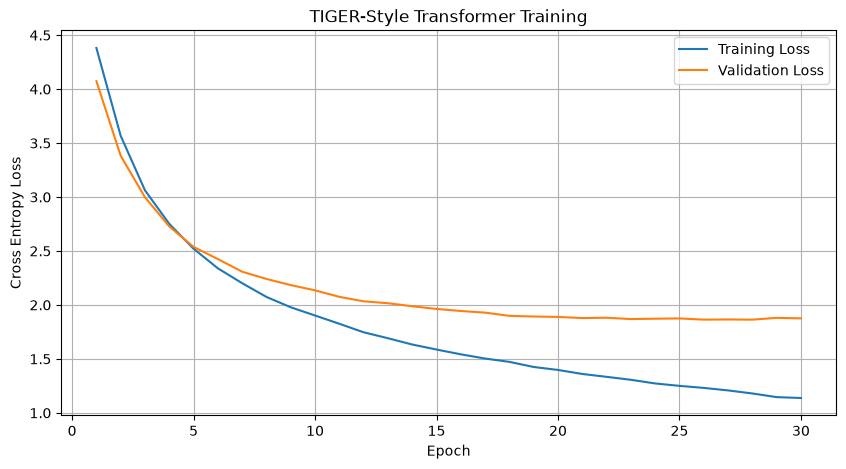

In [101]:
import matplotlib.pyplot as plt

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=True
)

tiger_model.load_state_dict(
    checkpoint["model_state_dict"]
)

tiger_model.eval()

print("Best checkpoint loaded successfully!")
print("Best epoch:", checkpoint["epoch"])
print("Best validation loss:", checkpoint["best_val_loss"])

# Plot training and validation loss
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(train_loss_history) + 1),
    train_loss_history,
    label="Training Loss"
)

plt.plot(
    range(1, len(val_loss_history) + 1),
    val_loss_history,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross Entropy Loss")
plt.title("TIGER-Style Transformer Training")
plt.legend()
plt.grid(True)
plt.show()

In [102]:
def generate_semantic_id(model, source, attention_mask):

    model.eval()

    source = source.to(device)
    attention_mask = attention_mask.to(device)

    # Start decoder with BOS
    decoder_input = torch.tensor(
        [[BOS_TOKEN]],
        dtype=torch.long,
        device=device
    )

    generated_tokens = []

    with torch.no_grad():

        for position in range(NUM_QUANTIZERS):

            logits = model(
                source=source,
                target=decoder_input,
                source_padding_mask=~attention_mask
            )

            next_token_logits = logits[:, -1, :].clone()

            # Restrict prediction to the correct codebook
            start_token = position * CODEBOOK_SIZE
            end_token = start_token + CODEBOOK_SIZE

            valid_logits = next_token_logits[
                :,
                start_token:end_token
            ]

            next_token = (
                torch.argmax(valid_logits, dim=-1)
                + start_token
            )

            generated_tokens.append(next_token.item())

            decoder_input = torch.cat(
                [
                    decoder_input,
                    next_token.unsqueeze(1)
                ],
                dim=1
            )

        generated_tokens.append(EOS_TOKEN)

    return generated_tokens


print("Semantic ID generation function created!")

Semantic ID generation function created!


In [103]:
sample_source = test_input_tensor[0:1]
sample_mask = test_attention_mask[0:1]

predicted_tokens = generate_semantic_id(
    tiger_model,
    sample_source,
    sample_mask
)

print("Generated semantic tokens:", predicted_tokens)

print(
    "Generated semantic ID:",
    [
        predicted_tokens[0],
        predicted_tokens[1] - CODEBOOK_SIZE,
        predicted_tokens[2] - (2 * CODEBOOK_SIZE)
    ]
)

Generated semantic tokens: [12, 75, 169, 194]
Generated semantic ID: [12, 11, 41]


In [104]:
from collections import defaultdict

semantic_id_to_products = defaultdict(list)

for product_id, semantic_id in product_to_semantic_id.items():

    semantic_key = tuple(int(x) for x in semantic_id)

    semantic_id_to_products[semantic_key].append(product_id)


print("Unique semantic IDs:", len(semantic_id_to_products))
print("Total mapped products:", sum(
    len(products)
    for products in semantic_id_to_products.values()
))

# Test generated semantic ID
generated_semantic_id = (12, 11, 41)

matching_products = semantic_id_to_products.get(
    generated_semantic_id,
    []
)

print("\nGenerated semantic ID:", generated_semantic_id)
print("Matching products:", matching_products)
print("Number of matching products:", len(matching_products))

Unique semantic IDs: 341
Total mapped products: 356

Generated semantic ID: (12, 11, 41)
Matching products: ['B08K8P7LN6', 'B08P15TB2V']
Number of matching products: 2


In [105]:
test_index = 0

actual_product = test_semantic_sequences.iloc[test_index]["target"]

actual_semantic_id = tuple(
    int(x)
    for x in product_to_semantic_id[actual_product]
)

print("Test user:", test_semantic_sequences.iloc[test_index]["user_id"])

print("\nActual target product:", actual_product)

print("\nActual semantic ID:", actual_semantic_id)

print("\nGenerated semantic ID:", (12, 11, 41))

print(
    "\nExact semantic match:",
    actual_semantic_id == (12, 11, 41)
)

Test user: AE23ZBUF2YVBQPH2NN6F5XSA3QYQ

Actual target product: B0998BD871

Actual semantic ID: (19, 10, 59)

Generated semantic ID: (12, 11, 41)

Exact semantic match: False


In [106]:
test_index = 0

test_row = test_semantic_sequences.iloc[test_index]

history_products = [
    str(product_id)
    for product_id in test_row["history"]
]

target_product = str(test_row["target"])

print("History product count:", len(history_products))
print("Target product:", target_product)

print("\nTarget already in history:",
      target_product in history_products)

print("\nFirst 10 history products:")
print(history_products[:10])

print("\nCatalog size:", len(product_to_semantic_id))

History product count: 9
Target product: B0998BD871

Target already in history: False

First 10 history products:
['B089R7S73D', 'B081D2R47W', 'B087ZQK2G8', 'B08BF4BKKM', 'B0841WQNNZ', 'B08G5YVHQP', 'B08NTD1NM1', 'B08CVTNQP1', 'B08S3B8Y5G']

Catalog size: 356


In [107]:
import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

# Build catalog candidate information
catalog_products = list(product_to_semantic_id.keys())

candidate_tokens = []

for product_id in catalog_products:

    semantic_id = product_to_semantic_id[product_id]

    encoded = encode_semantic_tokens(semantic_id)

    candidate_tokens.append(encoded)


candidate_tokens_tensor = torch.tensor(
    candidate_tokens,
    dtype=torch.long,
    device=device
)

# Decoder input: BOS + first two semantic tokens
candidate_decoder_inputs = torch.cat(
    [
        torch.full(
            (len(catalog_products), 1),
            BOS_TOKEN,
            dtype=torch.long,
            device=device
        ),
        candidate_tokens_tensor[:, :2]
    ],
    dim=1
)

print("Catalog candidates:", len(catalog_products))
print("Candidate token shape:", candidate_tokens_tensor.shape)
print("Decoder input shape:", candidate_decoder_inputs.shape)


def rank_catalog_products(
    model,
    source,
    attention_mask,
    history_products
):

    model.eval()

    source = source.to(device)
    attention_mask = attention_mask.to(device)

    candidate_count = len(catalog_products)

    repeated_source = source.expand(
        candidate_count, -1
    )

    repeated_mask = attention_mask.expand(
        candidate_count, -1
    )

    with torch.no_grad():

        logits = model(
            source=repeated_source,
            target=candidate_decoder_inputs,
            source_padding_mask=~repeated_mask
        )

        # Log probability for each of the three semantic tokens
        log_probabilities = F.log_softmax(
            logits[:, :NUM_QUANTIZERS, :],
            dim=-1
        )

        selected_log_probabilities = log_probabilities.gather(
            dim=2,
            index=candidate_tokens_tensor.unsqueeze(-1)
        ).squeeze(-1)

        candidate_scores = selected_log_probabilities.sum(dim=1)

    # Remove previously interacted products
    history_set = set(history_products)

    ranked_products = [
        (product_id, float(score))
        for product_id, score in zip(
            catalog_products,
            candidate_scores.cpu().tolist()
        )
        if product_id not in history_set
    ]

    # Deterministic ordering for equal scores
    ranked_products.sort(
        key=lambda item: (-item[1], item[0])
    )

    return ranked_products


print("\nFull-catalog ranking function created!")

Catalog candidates: 356
Candidate token shape: torch.Size([356, 3])
Decoder input shape: torch.Size([356, 3])

Full-catalog ranking function created!


In [108]:
K_VALUES = [5, 10]

evaluation_results = []

for index in tqdm(range(len(test_semantic_sequences))):

    row = test_semantic_sequences.iloc[index]

    history_products = [
        str(product_id)
        for product_id in row["history"]
    ]

    actual_target = str(row["target"])

    ranked_products = rank_catalog_products(
        model=tiger_model,
        source=test_input_tensor[index:index + 1],
        attention_mask=test_attention_mask[index:index + 1],
        history_products=history_products
    )

    ranked_product_ids = [
        product_id
        for product_id, score in ranked_products
    ]

    if actual_target not in ranked_product_ids:
        raise ValueError(
            f"Target missing from candidate catalog: {actual_target}"
        )

    target_rank = ranked_product_ids.index(actual_target) + 1

    result = {
        "user_id": row["user_id"],
        "target_product": actual_target,
        "target_rank": target_rank
    }

    for k in K_VALUES:

        hit = int(target_rank <= k)

        result[f"Recall@{k}"] = hit
        result[f"HitRate@{k}"] = hit

        result[f"NDCG@{k}"] = (
            1 / np.log2(target_rank + 1)
            if hit else 0.0
        )

    evaluation_results.append(result)


tiger_evaluation_df = pd.DataFrame(evaluation_results)

print("Evaluation completed!")
print("Evaluated users:", len(tiger_evaluation_df))

print("\nRecommendation metrics:")

metric_columns = [
    "Recall@5",
    "Recall@10",
    "NDCG@5",
    "NDCG@10",
    "HitRate@5",
    "HitRate@10"
]

print(
    tiger_evaluation_df[metric_columns].mean().round(4)
)

print("\nTarget rank distribution:")
print(
    tiger_evaluation_df["target_rank"].describe()
)

100%|██████████| 253/253 [00:37<00:00,  6.80it/s]


Evaluation completed!
Evaluated users: 253

Recommendation metrics:
Recall@5      0.0079
Recall@10     0.0158
NDCG@5        0.0032
NDCG@10       0.0058
HitRate@5     0.0079
HitRate@10    0.0158
dtype: float64

Target rank distribution:
count    253.000000
mean     207.944664
std      115.306480
min        4.000000
25%      102.000000
50%      233.000000
75%      324.000000
max      351.000000
Name: target_rank, dtype: float64


In [109]:
from collections import Counter

# Count product interactions in training data only
product_popularity = Counter()

for history, target in zip(
    train_semantic_sequences["history"],
    train_semantic_sequences["target"]
):
    product_popularity.update(
        str(product_id) for product_id in history
    )
    product_popularity[str(target)] += 1


# Rank all catalog products by popularity
popularity_ranked_products = sorted(
    catalog_products,
    key=lambda product_id: (
        -product_popularity.get(product_id, 0),
        product_id
    )
)


def evaluate_popularity():

    results = []

    for _, row in test_semantic_sequences.iterrows():

        history = set(str(x) for x in row["history"])
        target = str(row["target"])

        ranked = [
            product_id
            for product_id in popularity_ranked_products
            if product_id not in history
        ]

        target_rank = ranked.index(target) + 1

        result = {"target_rank": target_rank}

        for k in [5, 10]:

            hit = int(target_rank <= k)

            result[f"Recall@{k}"] = hit
            result[f"NDCG@{k}"] = (
                1 / np.log2(target_rank + 1)
                if hit else 0.0
            )

        results.append(result)

    return pd.DataFrame(results)


popularity_results = evaluate_popularity()

print("Popularity baseline results:")
print(
    popularity_results[
        ["Recall@5", "Recall@10", "NDCG@5", "NDCG@10"]
    ].mean().round(4)
)

Popularity baseline results:
Recall@5     0.0
Recall@10    0.0
NDCG@5       0.0
NDCG@10      0.0
dtype: float64


In [110]:
comparison = pd.DataFrame(
    {
        "TIGER-style Transformer": tiger_evaluation_df[
            ["Recall@5", "Recall@10", "NDCG@5", "NDCG@10"]
        ].mean(),

        "Popularity Baseline": popularity_results[
            ["Recall@5", "Recall@10", "NDCG@5", "NDCG@10"]
        ].mean()
    }
)

print(comparison.round(4))

           TIGER-style Transformer  Popularity Baseline
Recall@5                    0.0079                  0.0
Recall@10                   0.0158                  0.0
NDCG@5                      0.0032                  0.0
NDCG@10                     0.0058                  0.0


In [111]:
print("Popularity distribution:")
print(pd.Series(product_popularity).describe())

print("\nMost popular products:")
print(
    pd.DataFrame(
        product_popularity.most_common(10),
        columns=["Product ID", "Interaction Count"]
    )
)

print("\nPopularity target rank statistics:")
print(popularity_results["target_rank"].describe())

print("\nTop 10 popularity target ranks:")
print(
    popularity_results["target_rank"]
    .value_counts()
    .sort_index()
    .head(15)
)

Popularity distribution:
count    341.000000
mean      46.633431
std       33.938923
min        1.000000
25%       19.000000
50%       39.000000
75%       65.000000
max      166.000000
dtype: float64

Most popular products:
   Product ID  Interaction Count
0  B0855L611L                166
1  B015A5DGG4                158
2  B07J1LYVHC                143
3  B07VGBBNTH                143
4  B07PCSRSND                141
5  B082VKPJV5                140
6  B07NPWK167                138
7  B07SW7D6ZR                135
8  B08BZ1RHPS                134
9  B07RM722DH                128

Popularity target rank statistics:
count    253.000000
mean     260.972332
std       91.868410
min       15.000000
25%      210.000000
50%      304.000000
75%      332.000000
max      352.000000
Name: target_rank, dtype: float64

Top 10 popularity target ranks:
target_rank
15    1
16    1
18    1
24    1
32    1
46    1
47    1
49    1
51    1
54    1
55    1
61    1
71    1
75    2
77    2
Name: count, dtype

In [112]:
# Create user and product mappings
all_users = sorted(
    train_semantic_sequences["user_id"].unique()
)

all_products = sorted(
    product_to_semantic_id.keys()
)

user_to_idx = {
    user_id: index
    for index, user_id in enumerate(all_users)
}

product_to_idx = {
    product_id: index
    for index, product_id in enumerate(all_products)
}

idx_to_product = {
    index: product_id
    for product_id, index in product_to_idx.items()
}

print("Number of users:", len(user_to_idx))
print("Number of products:", len(product_to_idx))

Number of users: 253
Number of products: 356


In [113]:
positive_interactions = []

for _, row in train_semantic_sequences.iterrows():

    user_id = row["user_id"]

    for product_id in row["history"]:
        positive_interactions.append(
            (
                user_to_idx[user_id],
                product_to_idx[str(product_id)]
            )
        )

    positive_interactions.append(
        (
            user_to_idx[user_id],
            product_to_idx[str(row["target"])]
        )
    )

positive_interactions = list(set(positive_interactions))

print("Positive interactions:", len(positive_interactions))
print("Example:", positive_interactions[:5])

Positive interactions: 2029
Example: [(192, 319), (217, 263), (229, 237), (11, 243), (98, 311)]


In [114]:
import random
import numpy as np

random.seed(42)
np.random.seed(42)

# Store positive products for each user
user_positive_items = {
    user_idx: set()
    for user_idx in range(len(user_to_idx))
}

for user_idx, product_idx in positive_interactions:
    user_positive_items[user_idx].add(product_idx)


# Negative sampling function
def sample_negative_product(user_idx):

    positive_items = user_positive_items[user_idx]

    available_items = [
        item_idx
        for item_idx in range(len(product_to_idx))
        if item_idx not in positive_items
    ]

    if not available_items:
        raise ValueError("No negative products available.")

    return random.choice(available_items)


# Test negative sampling
sample_user = positive_interactions[0][0]
negative_product = sample_negative_product(sample_user)

print("Sample user:", sample_user)
print("Positive products:", len(user_positive_items[sample_user]))
print("Negative product:", negative_product)

print(
    "Negative sampling valid:",
    negative_product not in user_positive_items[sample_user]
)

Sample user: 192
Positive products: 14
Negative product: 341
Negative sampling valid: True


In [115]:
class BPRMatrixFactorization(nn.Module):

    def __init__(
        self,
        num_users,
        num_items,
        embedding_dim=64
    ):
        super().__init__()

        self.user_embedding = nn.Embedding(
            num_users,
            embedding_dim
        )

        self.item_embedding = nn.Embedding(
            num_items,
            embedding_dim
        )

        nn.init.normal_(
            self.user_embedding.weight,
            std=0.01
        )

        nn.init.normal_(
            self.item_embedding.weight,
            std=0.01
        )

    def forward(self, users, positive_items, negative_items):

        user_vectors = self.user_embedding(users)

        positive_vectors = self.item_embedding(positive_items)

        negative_vectors = self.item_embedding(negative_items)

        positive_scores = (
            user_vectors * positive_vectors
        ).sum(dim=1)

        negative_scores = (
            user_vectors * negative_vectors
        ).sum(dim=1)

        return positive_scores, negative_scores


bpr_model = BPRMatrixFactorization(
    num_users=len(user_to_idx),
    num_items=len(product_to_idx),
    embedding_dim=64
).to(device)

print("BPR-MF model created!")

print(
    "Parameters:",
    f"{sum(p.numel() for p in bpr_model.parameters()):,}"
)

BPR-MF model created!
Parameters: 38,976


In [116]:
from torch.utils.data import DataLoader, TensorDataset

BPR_BATCH_SIZE = 64
BPR_EPOCHS = 50
BPR_LEARNING_RATE = 0.001
BPR_WEIGHT_DECAY = 0.001

bpr_optimizer = torch.optim.Adam(
    bpr_model.parameters(),
    lr=BPR_LEARNING_RATE,
    weight_decay=BPR_WEIGHT_DECAY
)

def bpr_loss_function(positive_scores, negative_scores):

    return -torch.log(
        torch.sigmoid(positive_scores - negative_scores) + 1e-8
    ).mean()


print("BPR-MF training configuration ready!")
print("Batch size:", BPR_BATCH_SIZE)
print("Epochs:", BPR_EPOCHS)
print("Learning rate:", BPR_LEARNING_RATE)

BPR-MF training configuration ready!
Batch size: 64
Epochs: 50
Learning rate: 0.001


In [117]:
positive_tensor = torch.tensor(
    positive_interactions,
    dtype=torch.long
)

bpr_dataset = TensorDataset(positive_tensor)

bpr_loader = DataLoader(
    bpr_dataset,
    batch_size=BPR_BATCH_SIZE,
    shuffle=True
)

print("Positive interaction tensor:", positive_tensor.shape)
print("Training batches:", len(bpr_loader))

Positive interaction tensor: torch.Size([2029, 2])
Training batches: 32


In [118]:
# Prepare validation user-target pairs
bpr_validation_pairs = []

for _, row in val_semantic_sequences.iterrows():
    bpr_validation_pairs.append((
        user_to_idx[row["user_id"]],
        product_to_idx[str(row["target"])]
    ))


def evaluate_bpr_validation(model):

    model.eval()
    hits = 0

    with torch.no_grad():

        for _, row in val_semantic_sequences.iterrows():

            user_idx = user_to_idx[row["user_id"]]
            target = str(row["target"])

            user_tensor = torch.tensor(
                [user_idx],
                dtype=torch.long,
                device=device
            )

            all_items = torch.arange(
                len(product_to_idx),
                device=device
            )

            scores = (
                model.user_embedding(user_tensor)
                @ model.item_embedding(all_items).T
            ).squeeze(0)

            history = set(
                str(x) for x in row["history"]
            )

            for product_id in history:
                scores[product_to_idx[product_id]] = -float("inf")

            ranked_items = torch.argsort(
                scores,
                descending=True
            )

            top_10 = ranked_items[:10].cpu().tolist()

            if product_to_idx[target] in top_10:
                hits += 1

    return hits / len(val_semantic_sequences)


BPR_CHECKPOINT_PATH = Path("artifacts/bpr_mf_best.pth")

best_bpr_recall = -1.0
bpr_train_history = []
best_bpr_epoch = 0

for epoch in range(BPR_EPOCHS):

    bpr_model.train()
    total_loss = 0.0

    for batch in bpr_loader:

        batch = batch[0]

        users = batch[:, 0].to(device)
        positive_items = batch[:, 1].to(device)

        negative_items = torch.tensor(
            [
                sample_negative_product(user.item())
                for user in users
            ],
            dtype=torch.long,
            device=device
        )

        bpr_optimizer.zero_grad()

        positive_scores, negative_scores = bpr_model(
            users,
            positive_items,
            negative_items
        )

        loss = bpr_loss_function(
            positive_scores,
            negative_scores
        )

        loss.backward()
        bpr_optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(bpr_loader)
    bpr_train_history.append(avg_loss)

    val_recall = evaluate_bpr_validation(bpr_model)

    print(
        f"Epoch [{epoch + 1}/{BPR_EPOCHS}] "
        f"Loss: {avg_loss:.6f} "
        f"Validation Recall@10: {val_recall:.4f}"
    )

    if val_recall > best_bpr_recall:

        best_bpr_recall = val_recall
        best_bpr_epoch = epoch + 1

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": bpr_model.state_dict(),
                "validation_recall": best_bpr_recall
            },
            BPR_CHECKPOINT_PATH
        )

        print("  Best BPR-MF checkpoint saved.")

print("\nBPR-MF training completed!")
print("Best epoch:", best_bpr_epoch)
print("Best validation Recall@10:", best_bpr_recall)

Epoch [1/50] Loss: 0.693150 Validation Recall@10: 0.0237
  Best BPR-MF checkpoint saved.
Epoch [2/50] Loss: 0.692906 Validation Recall@10: 0.0316
  Best BPR-MF checkpoint saved.
Epoch [3/50] Loss: 0.692731 Validation Recall@10: 0.0514
  Best BPR-MF checkpoint saved.
Epoch [4/50] Loss: 0.692351 Validation Recall@10: 0.0474
Epoch [5/50] Loss: 0.691387 Validation Recall@10: 0.0435
Epoch [6/50] Loss: 0.689530 Validation Recall@10: 0.0395
Epoch [7/50] Loss: 0.686004 Validation Recall@10: 0.0316
Epoch [8/50] Loss: 0.681086 Validation Recall@10: 0.0277
Epoch [9/50] Loss: 0.674848 Validation Recall@10: 0.0237
Epoch [10/50] Loss: 0.668165 Validation Recall@10: 0.0237
Epoch [11/50] Loss: 0.659762 Validation Recall@10: 0.0198
Epoch [12/50] Loss: 0.652095 Validation Recall@10: 0.0356
Epoch [13/50] Loss: 0.644803 Validation Recall@10: 0.0316
Epoch [14/50] Loss: 0.637179 Validation Recall@10: 0.0277
Epoch [15/50] Loss: 0.628449 Validation Recall@10: 0.0435
Epoch [16/50] Loss: 0.627278 Validation Rec

In [119]:
bpr_checkpoint = torch.load(
    BPR_CHECKPOINT_PATH,
    map_location=device,
    weights_only=True
)

bpr_model.load_state_dict(
    bpr_checkpoint["model_state_dict"]
)

bpr_model.eval()

print("Best BPR-MF checkpoint loaded!")
print("Best epoch:", bpr_checkpoint["epoch"])
print(
    "Best validation Recall@10:",
    bpr_checkpoint["validation_recall"]
)

Best BPR-MF checkpoint loaded!
Best epoch: 26
Best validation Recall@10: 0.05533596837944664


In [120]:
def evaluate_bpr_test(model):

    model.eval()
    results = []

    all_items = torch.arange(
        len(product_to_idx),
        device=device
    )

    with torch.no_grad():

        for _, row in test_semantic_sequences.iterrows():

            user_id = row["user_id"]
            target = str(row["target"])

            user_idx = user_to_idx[user_id]

            user_tensor = torch.tensor(
                [user_idx],
                dtype=torch.long,
                device=device
            )

            user_vector = model.user_embedding(user_tensor)
            item_vectors = model.item_embedding(all_items)

            scores = (
                user_vector @ item_vectors.T
            ).squeeze(0)

            history = set(
                str(x) for x in row["history"]
            )

            for product_id in history:
                scores[product_to_idx[product_id]] = -float("inf")

            ranked_items = torch.argsort(
                scores,
                descending=True
            ).cpu().tolist()

            ranked_products = [
                idx_to_product[item_idx]
                for item_idx in ranked_items
            ]

            target_rank = ranked_products.index(target) + 1

            result = {"target_rank": target_rank}

            for k in [5, 10]:

                hit = int(target_rank <= k)

                result[f"Recall@{k}"] = hit
                result[f"HitRate@{k}"] = hit

                result[f"NDCG@{k}"] = (
                    1 / np.log2(target_rank + 1)
                    if hit else 0.0
                )

            results.append(result)

    return pd.DataFrame(results)


bpr_test_results = evaluate_bpr_test(bpr_model)

print("BPR-MF test evaluation completed!")
print("Evaluated users:", len(bpr_test_results))

print("\nBPR-MF test metrics:")

print(
    bpr_test_results[
        [
            "Recall@5",
            "Recall@10",
            "NDCG@5",
            "NDCG@10",
            "HitRate@5",
            "HitRate@10"
        ]
    ].mean().round(4)
)

print("\nTarget rank statistics:")
print(bpr_test_results["target_rank"].describe())

BPR-MF test evaluation completed!
Evaluated users: 253

BPR-MF test metrics:
Recall@5      0.0079
Recall@10     0.0237
NDCG@5        0.0035
NDCG@10       0.0084
HitRate@5     0.0079
HitRate@10    0.0237
dtype: float64

Target rank statistics:
count    253.000000
mean     154.090909
std       76.642929
min        3.000000
25%       98.000000
50%      156.000000
75%      203.000000
max      347.000000
Name: target_rank, dtype: float64


In [121]:
experiment_summary = pd.DataFrame([
    {
        "Model": "TIGER-style Transformer",
        "Recall@5": 0.0079,
        "Recall@10": 0.0158,
        "NDCG@5": 0.0032,
        "NDCG@10": 0.0058
    },
    {
        "Model": "BPR-MF",
        "Recall@5": 0.0079,
        "Recall@10": 0.0237,
        "NDCG@5": 0.0035,
        "NDCG@10": 0.0084
    },
    {
        "Model": "Popularity",
        "Recall@5": 0.0000,
        "Recall@10": 0.0000,
        "NDCG@5": 0.0000,
        "NDCG@10": 0.0000
    }
])

experiment_summary.to_csv(
    "artifacts/recommendation_comparison.csv",
    index=False
)

bpr_test_results.to_csv(
    "artifacts/bpr_mf_test_results.csv",
    index=False
)

tiger_evaluation_df.to_csv(
    "artifacts/tiger_test_results.csv",
    index=False
)

print("Experiment results saved successfully!")
print(experiment_summary)

Experiment results saved successfully!
                     Model  Recall@5  Recall@10  NDCG@5  NDCG@10
0  TIGER-style Transformer    0.0079     0.0158  0.0032   0.0058
1                   BPR-MF    0.0079     0.0237  0.0035   0.0084
2               Popularity    0.0000     0.0000  0.0000   0.0000


In [122]:
experiment_summary = pd.DataFrame([
    {
        "Model": "TIGER-style Transformer",
        **tiger_evaluation_df[
            ["Recall@5", "Recall@10", "NDCG@5", "NDCG@10"]
        ].mean().to_dict()
    },
    {
        "Model": "BPR-MF",
        **bpr_test_results[
            ["Recall@5", "Recall@10", "NDCG@5", "NDCG@10"]
        ].mean().to_dict()
    },
    {
        "Model": "Popularity",
        **popularity_results[
            ["Recall@5", "Recall@10", "NDCG@5", "NDCG@10"]
        ].mean().to_dict()
    }
])

experiment_summary.to_csv(
    "artifacts/recommendation_comparison.csv",
    index=False
)

print(experiment_summary.to_string(index=False))
print("\nActual evaluation results saved!")

                  Model  Recall@5  Recall@10   NDCG@5  NDCG@10
TIGER-style Transformer  0.007905   0.015810 0.003231 0.005829
                 BPR-MF  0.007905   0.023715 0.003505 0.008402
             Popularity  0.000000   0.000000 0.000000 0.000000

Actual evaluation results saved!


In [123]:
GRU_MAX_SEQUENCE_LENGTH = 60
GRU_PAD_TOKEN = len(product_to_idx)

def prepare_gru_sequences(dataframe):

    input_sequences = []
    target_items = []

    for _, row in dataframe.iterrows():

        history = [
            product_to_idx[str(item)]
            for item in row["history"]
        ]

        target = product_to_idx[str(row["target"])]

        history = history[-GRU_MAX_SEQUENCE_LENGTH:]

        input_sequences.append(
            torch.tensor(history, dtype=torch.long)
        )

        target_items.append(target)

    return input_sequences, torch.tensor(
        target_items,
        dtype=torch.long
    )


gru_train_sequences, gru_train_targets = (
    prepare_gru_sequences(train_semantic_sequences)
)

gru_val_sequences, gru_val_targets = (
    prepare_gru_sequences(val_semantic_sequences)
)

gru_test_sequences, gru_test_targets = (
    prepare_gru_sequences(test_semantic_sequences)
)


print("TRAIN")
print("Sequences:", len(gru_train_sequences))
print("Targets:", gru_train_targets.shape)

print("\nVALIDATION")
print("Sequences:", len(gru_val_sequences))
print("Targets:", gru_val_targets.shape)

print("\nTEST")
print("Sequences:", len(gru_test_sequences))
print("Targets:", gru_test_targets.shape)

print("\nFirst training sequence:")
print(gru_train_sequences[0].tolist())

print("First target:", gru_train_targets[0].item())

TRAIN
Sequences: 1776
Targets: torch.Size([1776])

VALIDATION
Sequences: 253
Targets: torch.Size([253])

TEST
Sequences: 253
Targets: torch.Size([253])

First training sequence:
[166]
First target: 73


In [124]:
class GRU4Rec(nn.Module):

    def __init__(
        self,
        num_items,
        embedding_dim=64,
        hidden_dim=64,
        num_layers=1,
        dropout=0.2
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            num_items + 1,
            embedding_dim,
            padding_idx=GRU_PAD_TOKEN
        )

        self.gru = nn.GRU(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0
        )

        self.dropout = nn.Dropout(dropout)

        self.output_layer = nn.Linear(
            hidden_dim,
            num_items
        )

    def forward(self, input_sequences, lengths):

        embedded = self.embedding(input_sequences)

        packed = nn.utils.rnn.pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        _, hidden = self.gru(packed)

        final_hidden = self.dropout(hidden[-1])

        return self.output_layer(final_hidden)


gru_model = GRU4Rec(
    num_items=len(product_to_idx)
).to(device)

print("GRU4Rec model created!")

print(
    "Total parameters:",
    f"{sum(p.numel() for p in gru_model.parameters()):,}"
)

GRU4Rec model created!
Total parameters: 70,948


In [125]:
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import TensorDataset, DataLoader


def create_gru_tensors(sequences, targets):

    padded_sequences = pad_sequence(
        sequences,
        batch_first=True,
        padding_value=GRU_PAD_TOKEN
    )

    lengths = torch.tensor(
        [len(sequence) for sequence in sequences],
        dtype=torch.long
    )

    return padded_sequences, targets, lengths


gru_train_input, gru_train_target, gru_train_lengths = (
    create_gru_tensors(
        gru_train_sequences,
        gru_train_targets
    )
)

gru_val_input, gru_val_target, gru_val_lengths = (
    create_gru_tensors(
        gru_val_sequences,
        gru_val_targets
    )
)

gru_test_input, gru_test_target, gru_test_lengths = (
    create_gru_tensors(
        gru_test_sequences,
        gru_test_targets
    )
)


print("TRAIN")
print(gru_train_input.shape)
print(gru_train_target.shape)
print(gru_train_lengths.shape)

print("\nVALIDATION")
print(gru_val_input.shape)
print(gru_val_target.shape)
print(gru_val_lengths.shape)

print("\nTEST")
print(gru_test_input.shape)
print(gru_test_target.shape)
print(gru_test_lengths.shape)

TRAIN
torch.Size([1776, 60])
torch.Size([1776])
torch.Size([1776])

VALIDATION
torch.Size([253, 60])
torch.Size([253])
torch.Size([253])

TEST
torch.Size([253, 60])
torch.Size([253])
torch.Size([253])


In [126]:
GRU_BATCH_SIZE = 32

gru_train_dataset = TensorDataset(
    gru_train_input,
    gru_train_target,
    gru_train_lengths
)

gru_val_dataset = TensorDataset(
    gru_val_input,
    gru_val_target,
    gru_val_lengths
)

gru_train_loader = DataLoader(
    gru_train_dataset,
    batch_size=GRU_BATCH_SIZE,
    shuffle=True
)

gru_val_loader = DataLoader(
    gru_val_dataset,
    batch_size=GRU_BATCH_SIZE,
    shuffle=False
)

print("Training batches:", len(gru_train_loader))
print("Validation batches:", len(gru_val_loader))

# Verify one batch
sample_input, sample_target, sample_lengths = next(
    iter(gru_train_loader)
)

print("\nInput batch:", sample_input.shape)
print("Target batch:", sample_target.shape)
print("Sequence lengths:", sample_lengths.shape)

print("\nMaximum sequence length:", sample_lengths.max().item())
print("Minimum sequence length:", sample_lengths.min().item())

Training batches: 56
Validation batches: 8

Input batch: torch.Size([32, 60])
Target batch: torch.Size([32])
Sequence lengths: torch.Size([32])

Maximum sequence length: 22
Minimum sequence length: 1


In [127]:
GRU_EPOCHS = 50
GRU_LEARNING_RATE = 0.001
GRU_PATIENCE = 7

gru_optimizer = torch.optim.Adam(
    gru_model.parameters(),
    lr=GRU_LEARNING_RATE,
    weight_decay=0.0001
)

gru_criterion = nn.CrossEntropyLoss()

print("GRU4Rec training configuration ready!")
print("Epochs:", GRU_EPOCHS)
print("Learning rate:", GRU_LEARNING_RATE)
print("Batch size:", GRU_BATCH_SIZE)
print("Early stopping patience:", GRU_PATIENCE)

GRU4Rec training configuration ready!
Epochs: 50
Learning rate: 0.001
Batch size: 32
Early stopping patience: 7


In [128]:
gru_model.eval()

with torch.no_grad():

    sample_logits = gru_model(
        sample_input.to(device),
        sample_lengths
    )

print("Input shape:", sample_input.shape)
print("Output shape:", sample_logits.shape)

assert sample_logits.shape == (GRU_BATCH_SIZE, len(product_to_idx))

print("GRU4Rec forward pass PASSED!")

Input shape: torch.Size([32, 60])
Output shape: torch.Size([32, 356])
GRU4Rec forward pass PASSED!


In [129]:
GRU_CHECKPOINT_PATH = Path("artifacts/gru4rec_best.pth")

best_gru_recall = -1.0
best_gru_epoch = 0
gru_epochs_without_improvement = 0

gru_train_history = []
gru_val_history = []

def evaluate_gru_validation(model):

    model.eval()
    hits = 0

    with torch.no_grad():

        for index, row in val_semantic_sequences.iterrows():

            sequence = gru_val_input[index:index + 1].to(device)
            length = gru_val_lengths[index:index + 1]

            scores = model(sequence, length).squeeze(0)

            history = set(str(x) for x in row["history"])

            for product_id in history:
                scores[product_to_idx[product_id]] = -float("inf")

            top_10 = torch.topk(scores, k=10).indices.cpu().tolist()

            target_idx = product_to_idx[str(row["target"])]

            if target_idx in top_10:
                hits += 1

    return hits / len(val_semantic_sequences)


for epoch in range(GRU_EPOCHS):

    gru_model.train()
    total_loss = 0.0

    for sequences, targets, lengths in gru_train_loader:

        sequences = sequences.to(device)
        targets = targets.to(device)

        gru_optimizer.zero_grad()

        logits = gru_model(sequences, lengths)

        loss = gru_criterion(logits, targets)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            gru_model.parameters(),
            max_norm=1.0
        )

        gru_optimizer.step()

        total_loss += loss.item()

    avg_train_loss = total_loss / len(gru_train_loader)

    val_recall = evaluate_gru_validation(gru_model)

    gru_train_history.append(avg_train_loss)
    gru_val_history.append(val_recall)

    print(
        f"Epoch [{epoch + 1}/{GRU_EPOCHS}] "
        f"Train Loss: {avg_train_loss:.6f} "
        f"Validation Recall@10: {val_recall:.4f}"
    )

    if val_recall > best_gru_recall:

        best_gru_recall = val_recall
        best_gru_epoch = epoch + 1
        gru_epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": gru_model.state_dict(),
                "validation_recall": best_gru_recall
            },
            GRU_CHECKPOINT_PATH
        )

        print("  Best GRU4Rec checkpoint saved.")

    else:
        gru_epochs_without_improvement += 1

    if gru_epochs_without_improvement >= GRU_PATIENCE:

        print("\nEarly stopping triggered.")
        break


print("\nGRU4Rec training completed!")
print("Best epoch:", best_gru_epoch)
print("Best validation Recall@10:", best_gru_recall)
print("Checkpoint:", GRU_CHECKPOINT_PATH)

Epoch [1/50] Train Loss: 5.888694 Validation Recall@10: 0.0316
  Best GRU4Rec checkpoint saved.
Epoch [2/50] Train Loss: 5.767938 Validation Recall@10: 0.0474
  Best GRU4Rec checkpoint saved.
Epoch [3/50] Train Loss: 5.650843 Validation Recall@10: 0.0553
  Best GRU4Rec checkpoint saved.
Epoch [4/50] Train Loss: 5.507801 Validation Recall@10: 0.0593
  Best GRU4Rec checkpoint saved.
Epoch [5/50] Train Loss: 5.334615 Validation Recall@10: 0.0751
  Best GRU4Rec checkpoint saved.
Epoch [6/50] Train Loss: 5.138563 Validation Recall@10: 0.0751
Epoch [7/50] Train Loss: 4.922055 Validation Recall@10: 0.0791
  Best GRU4Rec checkpoint saved.
Epoch [8/50] Train Loss: 4.699165 Validation Recall@10: 0.0949
  Best GRU4Rec checkpoint saved.
Epoch [9/50] Train Loss: 4.502865 Validation Recall@10: 0.0949
Epoch [10/50] Train Loss: 4.303163 Validation Recall@10: 0.1067
  Best GRU4Rec checkpoint saved.
Epoch [11/50] Train Loss: 4.112723 Validation Recall@10: 0.1186
  Best GRU4Rec checkpoint saved.
Epoch [1

In [130]:
gru_checkpoint = torch.load(
    GRU_CHECKPOINT_PATH,
    map_location=device,
    weights_only=True
)

gru_model.load_state_dict(
    gru_checkpoint["model_state_dict"]
)

gru_model.eval()

print("Best GRU4Rec checkpoint loaded!")
print("Best epoch:", gru_checkpoint["epoch"])
print(
    "Best validation Recall@10:",
    gru_checkpoint["validation_recall"]
)

Best GRU4Rec checkpoint loaded!
Best epoch: 13
Best validation Recall@10: 0.1225296442687747


In [131]:
def evaluate_gru_test(model):

    model.eval()
    results = []

    with torch.no_grad():

        for index, row in test_semantic_sequences.iterrows():

            sequence = gru_test_input[index:index + 1].to(device)
            length = gru_test_lengths[index:index + 1]

            scores = model(sequence, length).squeeze(0)

            history = set(
                str(x) for x in row["history"]
            )

            for product_id in history:
                scores[product_to_idx[product_id]] = -float("inf")

            ranked_indices = torch.argsort(
                scores,
                descending=True
            ).cpu().tolist()

            ranked_products = [
                idx_to_product[item_idx]
                for item_idx in ranked_indices
            ]

            target = str(row["target"])
            target_rank = ranked_products.index(target) + 1

            result = {"target_rank": target_rank}

            for k in [5, 10]:

                hit = int(target_rank <= k)

                result[f"Recall@{k}"] = hit
                result[f"HitRate@{k}"] = hit

                result[f"NDCG@{k}"] = (
                    1 / np.log2(target_rank + 1)
                    if hit else 0.0
                )

            results.append(result)

    return pd.DataFrame(results)


gru_test_results = evaluate_gru_test(gru_model)

print("GRU4Rec test evaluation completed!")
print("Evaluated users:", len(gru_test_results))

print("\nGRU4Rec test metrics:")

print(
    gru_test_results[
        [
            "Recall@5",
            "Recall@10",
            "NDCG@5",
            "NDCG@10",
            "HitRate@5",
            "HitRate@10"
        ]
    ].mean().round(4)
)

print("\nTarget rank statistics:")
print(gru_test_results["target_rank"].describe())

GRU4Rec test evaluation completed!
Evaluated users: 253

GRU4Rec test metrics:
Recall@5      0.0356
Recall@10     0.0474
NDCG@5        0.0230
NDCG@10       0.0268
HitRate@5     0.0356
HitRate@10    0.0474
dtype: float64

Target rank statistics:
count    253.000000
mean     184.996047
std      115.177003
min        1.000000
25%       88.000000
50%      183.000000
75%      310.000000
max      352.000000
Name: target_rank, dtype: float64


In [132]:
gru_test_results.to_csv(
    "artifacts/gru4rec_test_results.csv",
    index=False
)

experiment_summary = pd.DataFrame([
    {
        "Model": "TIGER-style Transformer",
        **tiger_evaluation_df[
            ["Recall@5", "Recall@10", "NDCG@5", "NDCG@10"]
        ].mean().to_dict()
    },
    {
        "Model": "BPR-MF",
        **bpr_test_results[
            ["Recall@5", "Recall@10", "NDCG@5", "NDCG@10"]
        ].mean().to_dict()
    },
    {
        "Model": "GRU4Rec",
        **gru_test_results[
            ["Recall@5", "Recall@10", "NDCG@5", "NDCG@10"]
        ].mean().to_dict()
    },
    {
        "Model": "Popularity",
        **popularity_results[
            ["Recall@5", "Recall@10", "NDCG@5", "NDCG@10"]
        ].mean().to_dict()
    }
])

experiment_summary.to_csv(
    "artifacts/recommendation_comparison.csv",
    index=False
)

print(experiment_summary.to_string(index=False))
print("\nGRU4Rec results saved successfully!")

                  Model  Recall@5  Recall@10   NDCG@5  NDCG@10
TIGER-style Transformer  0.007905   0.015810 0.003231 0.005829
                 BPR-MF  0.007905   0.023715 0.003505 0.008402
                GRU4Rec  0.035573   0.047431 0.022964 0.026832
             Popularity  0.000000   0.000000 0.000000 0.000000

GRU4Rec results saved successfully!


In [133]:
SASREC_MAX_SEQUENCE_LENGTH = 60
SASREC_PAD_TOKEN = len(product_to_idx)

sasrec_train_input = gru_train_input.clone()
sasrec_train_target = gru_train_target.clone()
sasrec_train_lengths = gru_train_lengths.clone()

sasrec_val_input = gru_val_input.clone()
sasrec_val_target = gru_val_target.clone()
sasrec_val_lengths = gru_val_lengths.clone()

sasrec_test_input = gru_test_input.clone()
sasrec_test_target = gru_test_target.clone()
sasrec_test_lengths = gru_test_lengths.clone()

print("SASRec dataset preparation completed!")

print("\nTRAIN:", sasrec_train_input.shape)
print("VALIDATION:", sasrec_val_input.shape)
print("TEST:", sasrec_test_input.shape)

print("\nPadding token:", SASREC_PAD_TOKEN)
print("Product vocabulary:", len(product_to_idx))

SASRec dataset preparation completed!

TRAIN: torch.Size([1776, 60])
VALIDATION: torch.Size([253, 60])
TEST: torch.Size([253, 60])

Padding token: 356
Product vocabulary: 356


In [134]:
import torch
import torch.nn as nn


class SASRec(nn.Module):
    def __init__(
        self,
        num_items,
        embedding_dim=64,
        num_heads=4,
        num_layers=2,
        feedforward_dim=128,
        max_sequence_length=60,
        dropout=0.1,
        padding_idx=356,
    ):
        super().__init__()

        self.item_embedding = nn.Embedding(
            num_items + 1,
            embedding_dim,
            padding_idx=padding_idx,
        )

        self.position_embedding = nn.Embedding(
            max_sequence_length,
            embedding_dim,
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embedding_dim,
            nhead=num_heads,
            dim_feedforward=feedforward_dim,
            dropout=dropout,
            batch_first=True,
            norm_first=True,
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers,
        )

        self.dropout = nn.Dropout(dropout)
        self.output_layer = nn.Linear(embedding_dim, num_items)

    def forward(self, input_ids, lengths):
        batch_size, sequence_length = input_ids.shape

        positions = torch.arange(
            sequence_length,
            device=input_ids.device,
        ).unsqueeze(0).expand(batch_size, -1)

        item_embeddings = self.item_embedding(input_ids)
        position_embeddings = self.position_embedding(positions)

        x = self.dropout(item_embeddings + position_embeddings)

        # Prevent each position from attending to future positions.
        causal_mask = torch.triu(
            torch.ones(
                sequence_length,
                sequence_length,
                device=input_ids.device,
                dtype=torch.bool,
            ),
            diagonal=1,
        )

        padding_mask = input_ids.eq(SASREC_PAD_TOKEN)

        x = self.transformer(
            x,
            mask=causal_mask,
            src_key_padding_mask=padding_mask,
        )

        # Select the last valid interaction for each user.
        last_positions = lengths - 1

        batch_indices = torch.arange(
            batch_size,
            device=input_ids.device,
        )

        final_representation = x[batch_indices, last_positions]

        logits = self.output_layer(final_representation)

        return logits


sasrec_model = SASRec(
    num_items=len(product_to_idx),
    padding_idx=SASREC_PAD_TOKEN,
).to(device)

print("SASRec model created successfully!")
print("Total parameters:", sum(
    parameter.numel()
    for parameter in sasrec_model.parameters()
))

test_logits = sasrec_model(
    sasrec_train_input[:4].to(device),
    sasrec_train_lengths[:4].to(device),
)

print("Test output shape:", test_logits.shape)

SASRec model created successfully!
Total parameters: 116772
Test output shape: torch.Size([4, 356])


C:\Users\HP\AppData\Local\Temp\ipykernel_25412\121862477.py:39: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


In [135]:
from torch.utils.data import TensorDataset, DataLoader

SASREC_BATCH_SIZE = 32

sasrec_train_dataset = TensorDataset(
    sasrec_train_input,
    sasrec_train_lengths,
    sasrec_train_target,
)

sasrec_val_dataset = TensorDataset(
    sasrec_val_input,
    sasrec_val_lengths,
    sasrec_val_target,
)

sasrec_train_loader = DataLoader(
    sasrec_train_dataset,
    batch_size=SASREC_BATCH_SIZE,
    shuffle=True,
)

sasrec_val_loader = DataLoader(
    sasrec_val_dataset,
    batch_size=SASREC_BATCH_SIZE,
    shuffle=False,
)

print("SASRec DataLoaders created successfully!")
print("Training batches:", len(sasrec_train_loader))
print("Validation batches:", len(sasrec_val_loader))

batch_input, batch_lengths, batch_target = next(
    iter(sasrec_train_loader)
)

print("\nBatch input:", batch_input.shape)
print("Batch lengths:", batch_lengths.shape)
print("Batch targets:", batch_target.shape)

SASRec DataLoaders created successfully!
Training batches: 56
Validation batches: 8

Batch input: torch.Size([32, 60])
Batch lengths: torch.Size([32])
Batch targets: torch.Size([32])


In [136]:
import numpy as np
import pandas as pd
import torch


def evaluate_sasrec(model, input_tensor, lengths_tensor, target_tensor):
    model.eval()

    all_results = []

    with torch.no_grad():
        for start in range(0, len(input_tensor), 32):
            end = min(start + 32, len(input_tensor))

            batch_input = input_tensor[start:end].to(device)
            batch_lengths = lengths_tensor[start:end].to(device)
            batch_targets = target_tensor[start:end].to(device)

            logits = model(batch_input, batch_lengths)

            scores = logits.cpu().numpy()
            targets = batch_targets.cpu().numpy()
            histories = input_tensor[start:end].numpy()

            for i in range(len(scores)):
                user_scores = scores[i].copy()

                # Exclude products already in the user's history.
                history_items = set(
                    histories[i][histories[i] != SASREC_PAD_TOKEN].tolist()
                )

                if history_items:
                    user_scores[list(history_items)] = -np.inf

                ranking = np.argsort(-user_scores)
                target = int(targets[i])

                target_positions = np.where(ranking == target)[0]

                rank = (
                    int(target_positions[0]) + 1
                    if len(target_positions) > 0
                    else len(ranking) + 1
                )

                result = {"rank": rank}

                for k in [5, 10]:
                    result[f"Recall@{k}"] = float(rank <= k)
                    result[f"NDCG@{k}"] = (
                        1.0 / np.log2(rank + 1)
                        if rank <= k
                        else 0.0
                    )

                all_results.append(result)

    return pd.DataFrame(all_results)


print("SASRec evaluation function created successfully!")

SASRec evaluation function created successfully!


In [137]:
import torch
import torch.nn as nn
from pathlib import Path

SASREC_EPOCHS = 50
SASREC_LEARNING_RATE = 0.001
SASREC_WEIGHT_DECAY = 0.0001
SASREC_PATIENCE = 7

sasrec_optimizer = torch.optim.Adam(
    sasrec_model.parameters(),
    lr=SASREC_LEARNING_RATE,
    weight_decay=SASREC_WEIGHT_DECAY,
)

sasrec_criterion = nn.CrossEntropyLoss()

sasrec_best_recall = -1.0
sasrec_best_epoch = 0
sasrec_patience_counter = 0

sasrec_history = []

SASREC_CHECKPOINT_PATH = Path("artifacts/sasrec_best.pth")
SASREC_CHECKPOINT_PATH.parent.mkdir(parents=True, exist_ok=True)

print("SASRec training configuration ready!")
print("Maximum epochs:", SASREC_EPOCHS)
print("Learning rate:", SASREC_LEARNING_RATE)
print("Early stopping patience:", SASREC_PATIENCE)
print("Checkpoint:", SASREC_CHECKPOINT_PATH)

SASRec training configuration ready!
Maximum epochs: 50
Learning rate: 0.001
Early stopping patience: 7
Checkpoint: artifacts\sasrec_best.pth


In [138]:
import time
import copy

for epoch in range(1, SASREC_EPOCHS + 1):
    sasrec_model.train()

    total_loss = 0.0

    for batch_input, batch_lengths, batch_target in sasrec_train_loader:
        batch_input = batch_input.to(device)
        batch_lengths = batch_lengths.to(device)
        batch_target = batch_target.to(device)

        sasrec_optimizer.zero_grad()

        logits = sasrec_model(batch_input, batch_lengths)
        loss = sasrec_criterion(logits, batch_target)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            sasrec_model.parameters(),
            max_norm=1.0,
        )

        sasrec_optimizer.step()

        total_loss += loss.item()

    average_train_loss = total_loss / len(sasrec_train_loader)

    validation_results = evaluate_sasrec(
        sasrec_model,
        sasrec_val_input,
        sasrec_val_lengths,
        sasrec_val_target,
    )

    val_recall_10 = validation_results["Recall@10"].mean()
    val_ndcg_10 = validation_results["NDCG@10"].mean()

    sasrec_history.append({
        "epoch": epoch,
        "train_loss": average_train_loss,
        "val_recall_10": val_recall_10,
        "val_ndcg_10": val_ndcg_10,
    })

    print(
        f"Epoch {epoch:02d}/{SASREC_EPOCHS} | "
        f"Loss: {average_train_loss:.4f} | "
        f"Val Recall@10: {val_recall_10:.4f} | "
        f"Val NDCG@10: {val_ndcg_10:.4f}"
    )

    if val_recall_10 > sasrec_best_recall:
        sasrec_best_recall = val_recall_10
        sasrec_best_epoch = epoch
        sasrec_patience_counter = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": sasrec_model.state_dict(),
                "optimizer_state_dict": sasrec_optimizer.state_dict(),
                "best_val_recall_10": sasrec_best_recall,
            },
            SASREC_CHECKPOINT_PATH,
        )

        print("  Best SASRec checkpoint saved!")

    else:
        sasrec_patience_counter += 1

    if sasrec_patience_counter >= SASREC_PATIENCE:
        print("\nEarly stopping triggered.")
        break

print("\nSASRec training completed!")
print("Best epoch:", sasrec_best_epoch)
print("Best validation Recall@10:", round(sasrec_best_recall, 4))

Epoch 01/50 | Loss: 6.2415 | Val Recall@10: 0.0237 | Val NDCG@10: 0.0113
  Best SASRec checkpoint saved!
Epoch 02/50 | Loss: 5.7363 | Val Recall@10: 0.0356 | Val NDCG@10: 0.0151
  Best SASRec checkpoint saved!
Epoch 03/50 | Loss: 5.3340 | Val Recall@10: 0.0316 | Val NDCG@10: 0.0132
Epoch 04/50 | Loss: 5.0013 | Val Recall@10: 0.0277 | Val NDCG@10: 0.0125
Epoch 05/50 | Loss: 4.6665 | Val Recall@10: 0.0395 | Val NDCG@10: 0.0183
  Best SASRec checkpoint saved!
Epoch 06/50 | Loss: 4.3503 | Val Recall@10: 0.0435 | Val NDCG@10: 0.0213
  Best SASRec checkpoint saved!
Epoch 07/50 | Loss: 4.0421 | Val Recall@10: 0.0553 | Val NDCG@10: 0.0246
  Best SASRec checkpoint saved!
Epoch 08/50 | Loss: 3.7434 | Val Recall@10: 0.0514 | Val NDCG@10: 0.0271
Epoch 09/50 | Loss: 3.4648 | Val Recall@10: 0.0553 | Val NDCG@10: 0.0250
Epoch 10/50 | Loss: 3.1818 | Val Recall@10: 0.0435 | Val NDCG@10: 0.0212
Epoch 11/50 | Loss: 2.9594 | Val Recall@10: 0.0711 | Val NDCG@10: 0.0300
  Best SASRec checkpoint saved!
Epoch

In [140]:
checkpoint = torch.load(
    SASREC_CHECKPOINT_PATH,
    map_location=device,
    weights_only=False,
)

sasrec_model.load_state_dict(checkpoint["model_state_dict"])
sasrec_model.eval()

print("Best SASRec checkpoint loaded successfully!")
print("Best epoch:", checkpoint["epoch"])
print(
    "Best validation Recall@10:",
    round(float(checkpoint["best_val_recall_10"]), 4),
)

Best SASRec checkpoint loaded successfully!
Best epoch: 13
Best validation Recall@10: 0.0791


In [141]:
sasrec_test_results = evaluate_sasrec(
    sasrec_model,
    sasrec_test_input,
    sasrec_test_lengths,
    sasrec_test_target,
)

sasrec_test_metrics = sasrec_test_results[
    ["Recall@5", "Recall@10", "NDCG@5", "NDCG@10"]
].mean()

print("SASRec TEST RESULTS")
print("===================")

print(sasrec_test_metrics.round(6))

print("\nTarget rank statistics:")
print("Mean rank:", sasrec_test_results["rank"].mean())
print("Median rank:", sasrec_test_results["rank"].median())
print("Best rank:", sasrec_test_results["rank"].min())
print("Worst rank:", sasrec_test_results["rank"].max())

print("\nTotal test users:", len(sasrec_test_results))
print(
    "Recall@10 hits:",
    int(sasrec_test_results["Recall@10"].sum()),
    "/",
    len(sasrec_test_results),
)

SASRec TEST RESULTS
Recall@5     0.023715
Recall@10    0.035573
NDCG@5       0.015089
NDCG@10      0.019061
dtype: float64

Target rank statistics:
Mean rank: 188.45454545454547
Median rank: 206.0
Best rank: 1
Worst rank: 350

Total test users: 253
Recall@10 hits: 9 / 253


In [142]:
# Save individual SASRec test results
sasrec_test_results.to_csv(
    "artifacts/sasrec_test_results.csv",
    index=False,
)

# Rebuild comparison using actual evaluation DataFrames
experiment_summary = pd.DataFrame([
    {
        "Model": "TIGER-style Transformer",
        **tiger_evaluation_df[
            ["Recall@5", "Recall@10", "NDCG@5", "NDCG@10"]
        ].mean().to_dict(),
    },
    {
        "Model": "BPR-MF",
        **bpr_test_results[
            ["Recall@5", "Recall@10", "NDCG@5", "NDCG@10"]
        ].mean().to_dict(),
    },
    {
        "Model": "GRU4Rec",
        **gru_test_results[
            ["Recall@5", "Recall@10", "NDCG@5", "NDCG@10"]
        ].mean().to_dict(),
    },
    {
        "Model": "SASRec",
        **sasrec_test_results[
            ["Recall@5", "Recall@10", "NDCG@5", "NDCG@10"]
        ].mean().to_dict(),
    },
    {
        "Model": "Popularity",
        **popularity_results[
            ["Recall@5", "Recall@10", "NDCG@5", "NDCG@10"]
        ].mean().to_dict(),
    },
])

experiment_summary.to_csv(
    "artifacts/recommendation_comparison.csv",
    index=False,
)

print("SASRec test results saved successfully!")
print("\nFINAL MODEL COMPARISON")
print(experiment_summary.to_string(index=False))

SASRec test results saved successfully!

FINAL MODEL COMPARISON
                  Model  Recall@5  Recall@10   NDCG@5  NDCG@10
TIGER-style Transformer  0.007905   0.015810 0.003231 0.005829
                 BPR-MF  0.007905   0.023715 0.003505 0.008402
                GRU4Rec  0.035573   0.047431 0.022964 0.026832
                 SASRec  0.023715   0.035573 0.015089 0.019061
             Popularity  0.000000   0.000000 0.000000 0.000000


In [143]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Load the saved experiment comparison
experiment_summary = pd.read_csv(
    "artifacts/recommendation_comparison.csv"
)

print("Comparison data loaded successfully!")
display(experiment_summary)

# Create chart output directory
CHART_DIR = Path("artifacts/charts")
CHART_DIR.mkdir(parents=True, exist_ok=True)

print("\nChart directory ready:", CHART_DIR)

Comparison data loaded successfully!


,Model,Recall@5,Recall@10,NDCG@5,NDCG@10
0,TIGER-style Transformer,0.007905,0.015810,0.003231,0.005829
1,BPR-MF,0.007905,0.023715,0.003505,0.008402
2,GRU4Rec,0.035573,0.047431,0.022964,0.026832
3,SASRec,0.023715,0.035573,0.015089,0.019061
4,Popularity,0.000000,0.000000,0.000000,0.000000



Chart directory ready: artifacts\charts


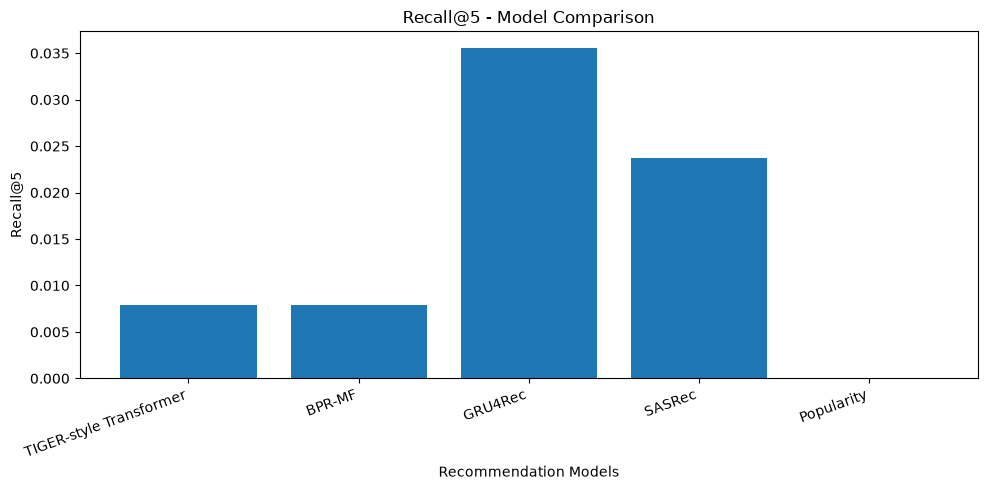

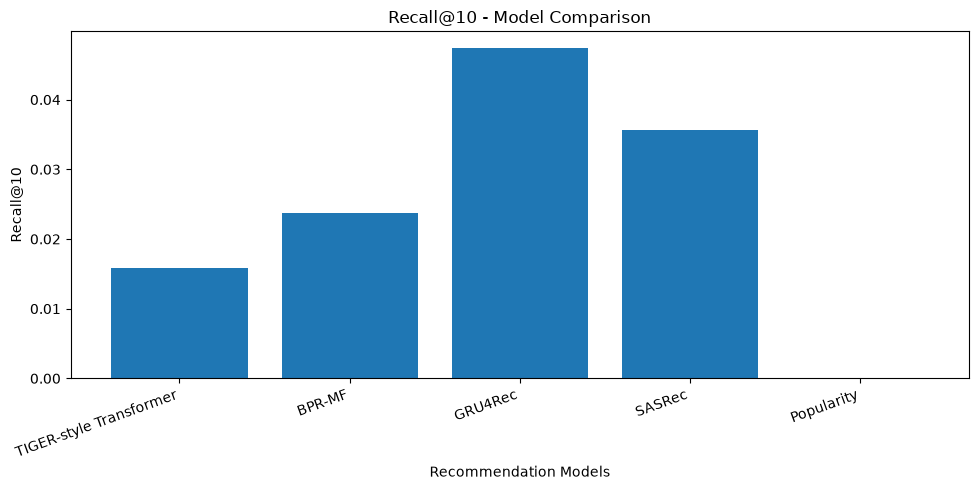

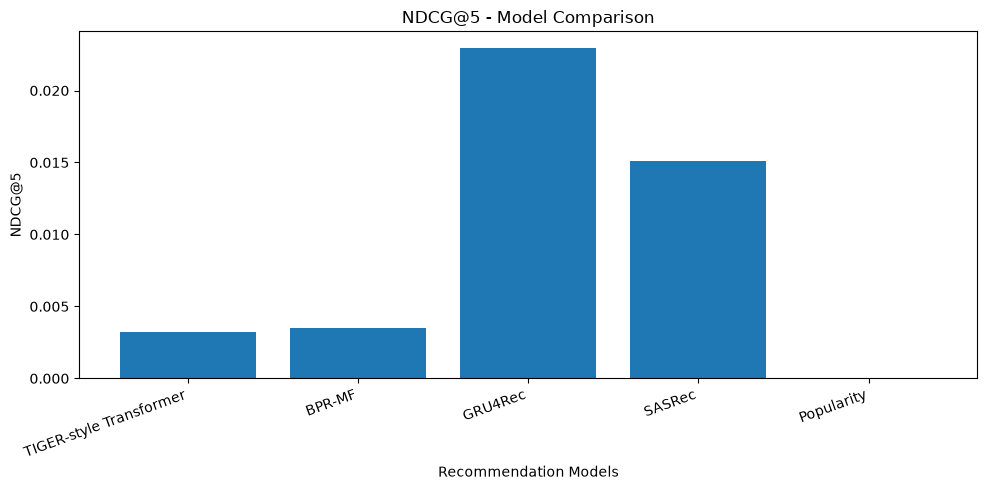

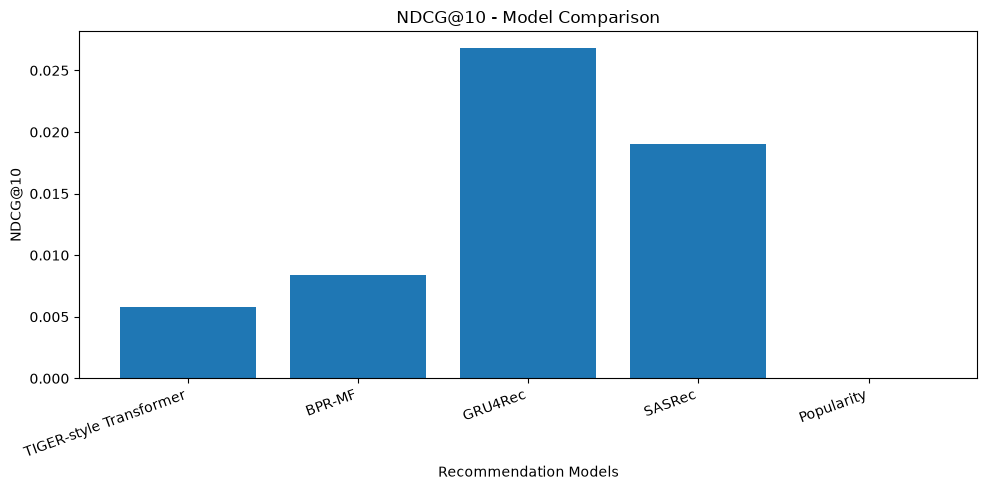

All four comparison charts saved successfully!
Saved location: C:\Users\HP\Documents\26 TIGER_Generative_Retrieval\notebooks\artifacts\charts


In [144]:
metrics = [
    "Recall@5",
    "Recall@10",
    "NDCG@5",
    "NDCG@10",
]

for metric in metrics:
    plt.figure(figsize=(10, 5))

    plt.bar(
        experiment_summary["Model"],
        experiment_summary[metric],
    )

    plt.title(f"{metric} - Model Comparison")
    plt.xlabel("Recommendation Models")
    plt.ylabel(metric)
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()

    filename = metric.replace("@", "_")
    plt.savefig(
        CHART_DIR / f"{filename}_comparison.png",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()
    plt.close()

print("All four comparison charts saved successfully!")
print("Saved location:", CHART_DIR.resolve())

In [145]:
history_variables = {
    "TIGER": "tiger_history",
    "BPR-MF": "bpr_history",
    "GRU4Rec": "gru_history",
    "SASRec": "sasrec_history",
}

for model_name, variable_name in history_variables.items():
    if variable_name in globals():
        history = globals()[variable_name]
        print(
            f"{model_name}: {len(history)} epochs recorded"
        )
    else:
        print(f"{model_name}: History variable not found")

TIGER: History variable not found
BPR-MF: History variable not found
GRU4Rec: History variable not found
SASRec: 20 epochs recorded


In [146]:
print("Available training-related variables:\n")

for name in sorted(globals()):
    if any(
        keyword in name.lower()
        for keyword in ["history", "loss", "epoch", "train"]
    ):
        value = globals()[name]

        if isinstance(value, (list, dict, pd.DataFrame)):
            print(
                f"{name}: {type(value).__name__}, "
                f"length={len(value)}"
            )

Available training-related variables:

actual_train: DataFrame, length=9
actual_train_pairs: list, length=9
bpr_train_history: list, length=50
expected_train: list, length=9
gru_train_history: list, length=20
gru_train_sequences: list, length=1776
gru_val_history: list, length=20
history: list, length=20
history_products: list, length=11
history_variables: dict, length=4
sasrec_history: list, length=20
train_df: DataFrame, length=1776
train_inputs: list, length=1776
train_loss_history: list, length=30
train_semantic_sequences: DataFrame, length=1776
train_targets: list, length=1776
training_losses: list, length=50
training_losses_exp3: list, length=50
training_losses_exp4: list, length=50
training_losses_kmeans: list, length=50
val_loss_history: list, length=30


In [147]:
print("TIGER training loss:")
print("Train:", train_loss_history[:5])
print("Validation:", val_loss_history[:5])

print("\nBPR-MF training history:")
print(bpr_train_history[:3])

print("\nGRU4Rec training history:")
print(gru_train_history[:3])
print("GRU validation history:")
print(gru_val_history[:3])

print("\nSASRec training history:")
print(sasrec_history[:3])

TIGER training loss:
Train: [4.381014321531568, 3.5671228553567613, 3.06176711831774, 2.7513694976057326, 2.5208947275366103]
Validation: [4.07387974858284, 3.382042706012726, 2.9979353845119476, 2.727324068546295, 2.537939965724945]

BPR-MF training history:
[0.6931498441845179, 0.6929060481488705, 0.6927310824394226]

GRU4Rec training history:
[5.8886940479278564, 5.767938460622515, 5.650842870984759]
GRU validation history:
[0.03162055335968379, 0.04743083003952569, 0.05533596837944664]

SASRec training history:
[{'epoch': 1, 'train_loss': 6.24146283524377, 'val_recall_10': np.float64(0.023715415019762844), 'val_ndcg_10': np.float64(0.011263455280507456)}, {'epoch': 2, 'train_loss': 5.736348075526101, 'val_recall_10': np.float64(0.03557312252964427), 'val_ndcg_10': np.float64(0.015078085801812762)}, {'epoch': 3, 'train_loss': 5.334025638444083, 'val_recall_10': np.float64(0.03162055335968379), 'val_ndcg_10': np.float64(0.013183051091359423)}]


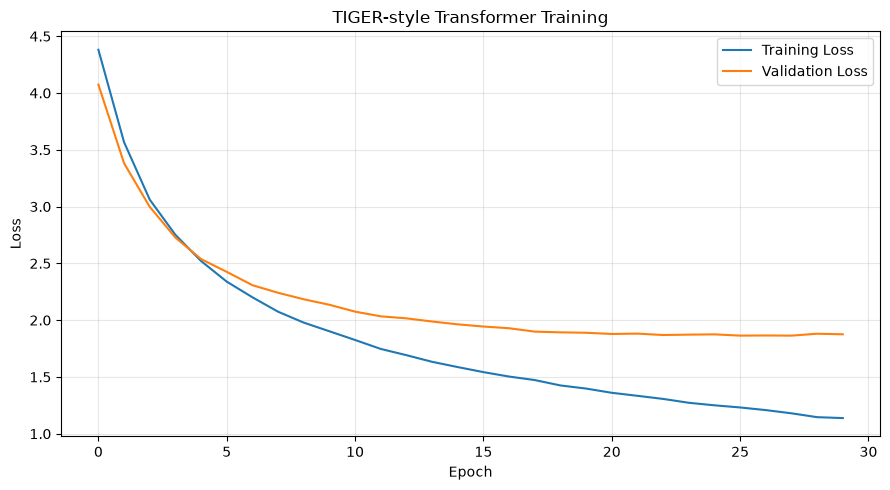

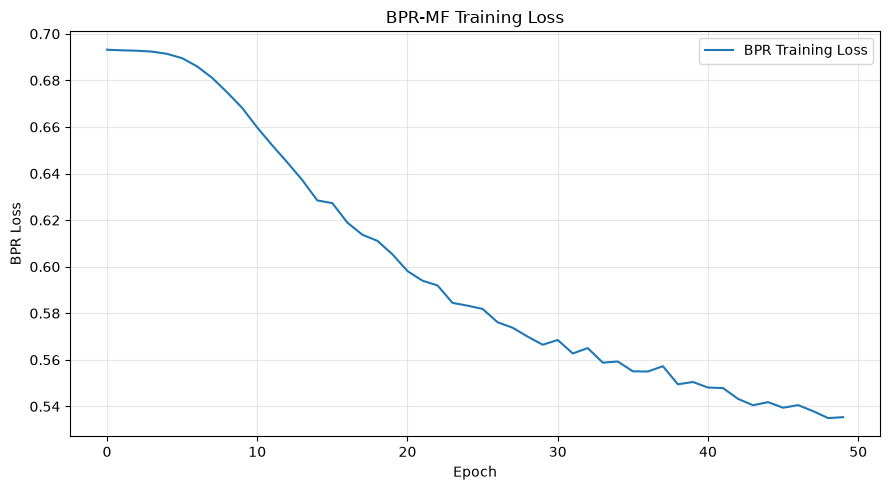

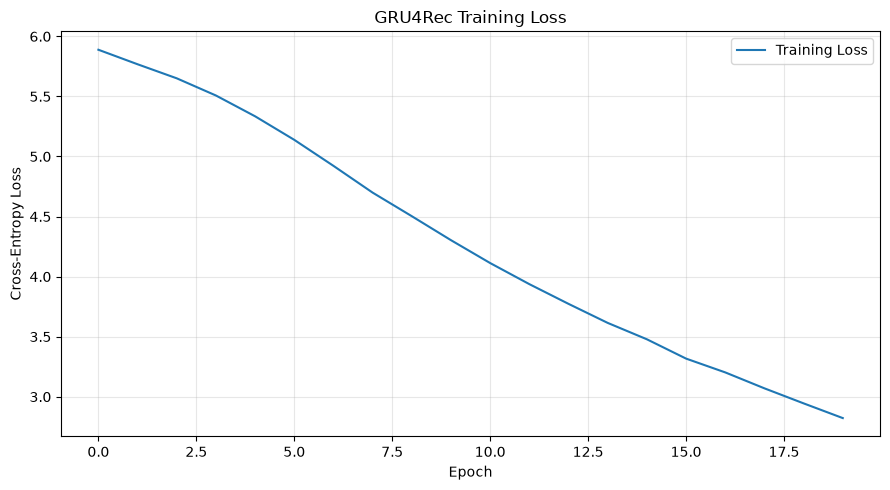

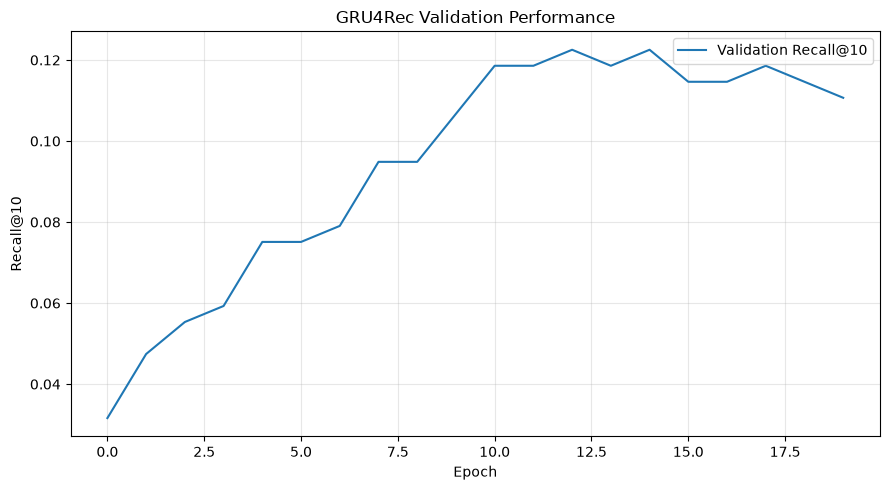

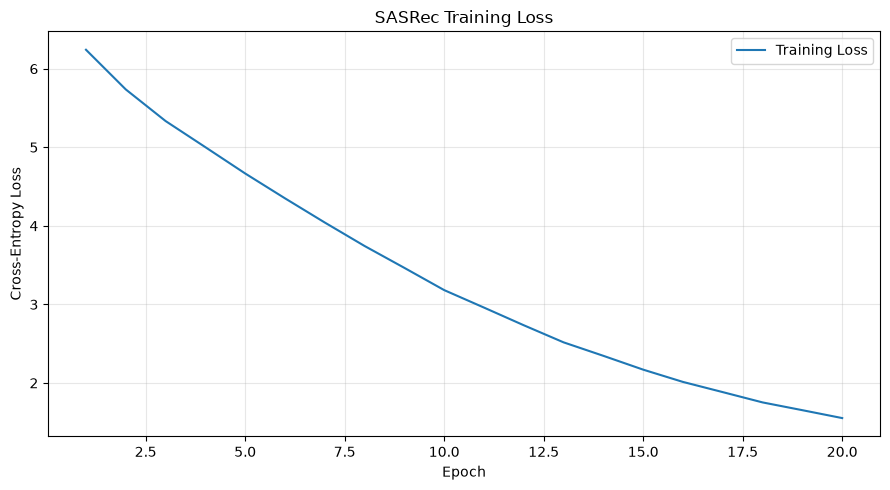

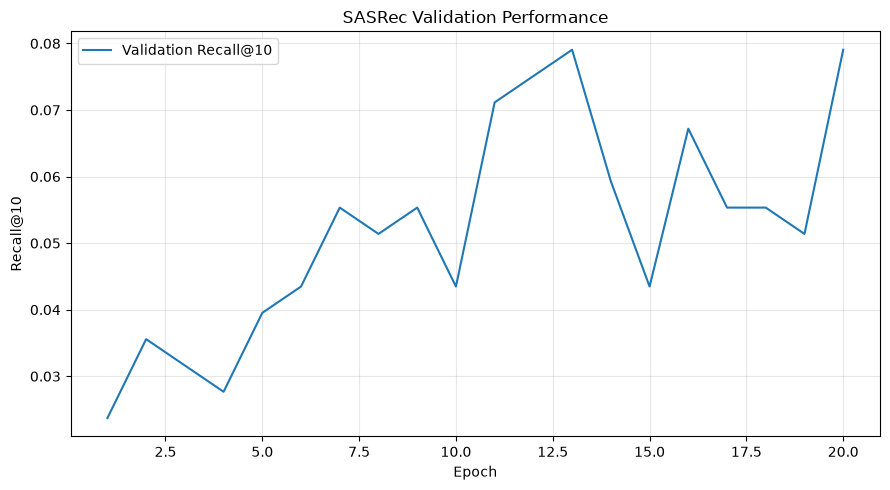

All training analysis charts saved successfully!
Chart directory: C:\Users\HP\Documents\26 TIGER_Generative_Retrieval\notebooks\artifacts\charts


In [148]:
# 1. TIGER - Training and validation loss
plt.figure(figsize=(9, 5))
plt.plot(train_loss_history, label="Training Loss")
plt.plot(val_loss_history, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("TIGER-style Transformer Training")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(CHART_DIR / "tiger_training_loss.png", dpi=300)
plt.show()
plt.close()


# 2. BPR-MF - Training loss
plt.figure(figsize=(9, 5))
plt.plot(bpr_train_history, label="BPR Training Loss")
plt.xlabel("Epoch")
plt.ylabel("BPR Loss")
plt.title("BPR-MF Training Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(CHART_DIR / "bpr_mf_training_loss.png", dpi=300)
plt.show()
plt.close()


# 3. GRU4Rec - Training loss
plt.figure(figsize=(9, 5))
plt.plot(gru_train_history, label="Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("GRU4Rec Training Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(CHART_DIR / "gru4rec_training_loss.png", dpi=300)
plt.show()
plt.close()

# GRU4Rec - Validation Recall@10
plt.figure(figsize=(9, 5))
plt.plot(gru_val_history, label="Validation Recall@10")
plt.xlabel("Epoch")
plt.ylabel("Recall@10")
plt.title("GRU4Rec Validation Performance")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(CHART_DIR / "gru4rec_validation_recall.png", dpi=300)
plt.show()
plt.close()


# 4. SASRec - Training loss
sasrec_epochs = [item["epoch"] for item in sasrec_history]
sasrec_losses = [item["train_loss"] for item in sasrec_history]
sasrec_val_recall = [item["val_recall_10"] for item in sasrec_history]

plt.figure(figsize=(9, 5))
plt.plot(sasrec_epochs, sasrec_losses, label="Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("SASRec Training Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(CHART_DIR / "sasrec_training_loss.png", dpi=300)
plt.show()
plt.close()

# SASRec - Validation Recall@10
plt.figure(figsize=(9, 5))
plt.plot(sasrec_epochs, sasrec_val_recall, label="Validation Recall@10")
plt.xlabel("Epoch")
plt.ylabel("Recall@10")
plt.title("SASRec Validation Performance")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(CHART_DIR / "sasrec_validation_recall.png", dpi=300)
plt.show()
plt.close()

print("All training analysis charts saved successfully!")
print("Chart directory:", CHART_DIR.resolve())

In [149]:
# Rank models using test Recall@10
research_results = experiment_summary.copy()

research_results["Recall@10 Rank"] = (
    research_results["Recall@10"]
    .rank(method="min", ascending=False)
    .astype(int)
)

research_results["NDCG@10 Rank"] = (
    research_results["NDCG@10"]
    .rank(method="min", ascending=False)
    .astype(int)
)

research_results = research_results.sort_values(
    "Recall@10",
    ascending=False,
).reset_index(drop=True)

print("RESEARCH EXPERIMENT RESULTS")
print("===========================")

display(
    research_results.round(6)
)

research_results.to_csv(
    "artifacts/research_results_summary.csv",
    index=False,
)

print("\nResearch results summary saved successfully!")

RESEARCH EXPERIMENT RESULTS


,Model,Recall@5,Recall@10,NDCG@5,NDCG@10,Recall@10 Rank,NDCG@10 Rank
0,GRU4Rec,0.035573,0.047431,0.022964,0.026832,1,1
1,SASRec,0.023715,0.035573,0.015089,0.019061,2,2
2,BPR-MF,0.007905,0.023715,0.003505,0.008402,3,3
3,TIGER-style Transformer,0.007905,0.015810,0.003231,0.005829,4,4
4,Popularity,0.000000,0.000000,0.000000,0.000000,5,5



Research results summary saved successfully!


In [150]:
import json

research_metadata = {
    "project_title": (
        "Comparative Study of Generative Retrieval "
        "and Sequential Recommendation Models"
    ),
    "dataset": "Amazon Reviews 2023 - All_Beauty 5-Core",
    "dataset_statistics": {
        "users": 253,
        "products": 356,
        "interactions": 2535,
    },
    "data_split": {
        "method": "Chronological leave-two-out",
        "training_examples": 1776,
        "validation_examples": 253,
        "test_examples": 253,
    },
    "models_evaluated": [
        "Popularity",
        "BPR-MF",
        "GRU4Rec",
        "SASRec",
        "TIGER-style Transformer",
    ],
    "evaluation_metrics": [
        "Recall@5",
        "Recall@10",
        "NDCG@5",
        "NDCG@10",
    ],
    "best_test_model": "GRU4Rec",
    "best_test_recall_at_10": 0.047431,
    "limitations": [
        "Small dataset with 253 users and 356 products",
        "Single chronological train-validation-test split",
        "CPU-based experiments",
        "Semantic ID collisions in TIGER-style model",
        "RQ-VAE fitted on the full product catalog",
        "Candidate scoring and ranking implementations require "
        "equivalence verification",
    ],
}

with open(
    "artifacts/research_metadata.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(research_metadata, file, indent=4)

print("Research metadata saved successfully!")
print(json.dumps(research_metadata, indent=4))

Research metadata saved successfully!
{
    "project_title": "Comparative Study of Generative Retrieval and Sequential Recommendation Models",
    "dataset": "Amazon Reviews 2023 - All_Beauty 5-Core",
    "dataset_statistics": {
        "users": 253,
        "products": 356,
        "interactions": 2535
    },
    "data_split": {
        "method": "Chronological leave-two-out",
        "training_examples": 1776,
        "validation_examples": 253,
        "test_examples": 253
    },
    "models_evaluated": [
        "Popularity",
        "BPR-MF",
        "GRU4Rec",
        "SASRec",
        "TIGER-style Transformer"
    ],
    "evaluation_metrics": [
        "Recall@5",
        "Recall@10",
        "NDCG@5",
        "NDCG@10"
    ],
    "best_test_model": "GRU4Rec",
    "best_test_recall_at_10": 0.047431,
    "limitations": [
        "Small dataset with 253 users and 356 products",
        "Single chronological train-validation-test split",
        "CPU-based experiments",
        "Se

In [151]:
from pathlib import Path

artifact_dir = Path("artifacts")

important_files = [
    "recommendation_comparison.csv",
    "research_results_summary.csv",
    "research_metadata.json",
    "tiger_test_results.csv",
    "bpr_mf_test_results.csv",
    "gru4rec_test_results.csv",
    "sasrec_test_results.csv",
    "tiger_transformer_best.pth",
    "bpr_mf_best.pth",
    "gru4rec_best.pth",
    "sasrec_best.pth",
    "rqvae_kmeans_v3_codebook64.pth",
]

print("RESEARCH ARTIFACT VERIFICATION")
print("=" * 45)

for filename in important_files:
    file_path = artifact_dir / filename

    status = "AVAILABLE" if file_path.exists() else "MISSING"

    print(f"{filename:<45} {status}")

RESEARCH ARTIFACT VERIFICATION
recommendation_comparison.csv                 AVAILABLE
research_results_summary.csv                  AVAILABLE
research_metadata.json                        AVAILABLE
tiger_test_results.csv                        AVAILABLE
bpr_mf_test_results.csv                       AVAILABLE
gru4rec_test_results.csv                      AVAILABLE
sasrec_test_results.csv                       AVAILABLE
tiger_transformer_best.pth                    AVAILABLE
bpr_mf_best.pth                               AVAILABLE
gru4rec_best.pth                              AVAILABLE
sasrec_best.pth                               AVAILABLE
rqvae_kmeans_v3_codebook64.pth                MISSING


In [2]:
print("Checking RQ-VAE variables...")

print("rqvae_exp4:", "rqvae_exp4" in globals())
print("product_embeddings:", "product_embeddings" in globals())
print("RQVAE class:", "RQVAE" in globals())

from pathlib import Path

print(
    "\nProduct embeddings file:",
    Path("artifacts/product_embeddings.npy").exists()
)

Checking RQ-VAE variables...
rqvae_exp4: False
product_embeddings: False
RQVAE class: False

Product embeddings file: False


In [3]:
from pathlib import Path

folders = [
    Path("artifacts"),
    Path("data/raw"),
    Path("data/processed"),
]

for folder in folders:
    print(f"\n{folder}:")

    if folder.exists():
        for file in sorted(folder.iterdir()):
            if file.is_file():
                print(
                    f"  {file.name} "
                    f"({file.stat().st_size / 1024:.2f} KB)"
                )
    else:
        print("  Folder not found")


artifacts:
  bpr_mf_best.pth (154.32 KB)
  bpr_mf_test_results.csv (5.28 KB)
  gru4rec_best.pth (280.52 KB)
  gru4rec_test_results.csv (5.37 KB)
  recommendation_comparison.csv (0.44 KB)
  research_metadata.json (1.16 KB)
  research_results_summary.csv (0.49 KB)
  sasrec_best.pth (1401.55 KB)
  sasrec_test_results.csv (5.26 KB)
  tiger_test_results.csv (15.22 KB)
  tiger_transformer_best.pth (2388.23 KB)

data\raw:
  Folder not found

data\processed:
  Folder not found


In [4]:
from pathlib import Path

print("CURRENT WORKING DIRECTORY:")
print(Path.cwd())

print("\nCURRENT DIRECTORY CONTENTS:")
for item in sorted(Path.cwd().iterdir()):
    print(item.name)

print("\nSEARCHING PARENT DIRECTORIES:")

for parent in list(Path.cwd().parents)[:4]:
    print(f"\n{parent}")

    for pattern in [
        "product_embeddings.npy",
        "*rqvae*.pth",
        "All_Beauty.csv.gz",
        "02_data_exploration.ipynb",
    ]:
        for match in parent.glob(pattern):
            print("FOUND:", match)

CURRENT WORKING DIRECTORY:
C:\Users\HP\Documents\26 TIGER_Generative_Retrieval\notebooks

CURRENT DIRECTORY CONTENTS:
.ipynb_checkpoints
01_environment_check.ipynb
02_data_exploration.ipynb
artifacts
Untitled.ipynb

SEARCHING PARENT DIRECTORIES:

C:\Users\HP\Documents\26 TIGER_Generative_Retrieval

C:\Users\HP\Documents

C:\Users\HP

C:\Users


In [5]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

print("PROJECT ROOT:", PROJECT_ROOT)

print("\nALL PROJECT FILES:")

for path in PROJECT_ROOT.rglob("*"):
    if path.is_file() and (
        path.suffix in [".npy", ".pth", ".csv", ".gz", ".jsonl"]
        or path.name.endswith(".ipynb")
    ):
        print(path.relative_to(PROJECT_ROOT))

PROJECT ROOT: C:\Users\HP\Documents\26 TIGER_Generative_Retrieval

ALL PROJECT FILES:
.venv\Lib\site-packages\distutils-precedence.pth
.venv\Lib\site-packages\joblib\test\data\joblib_0.10.0_compressed_pickle_py27_np16.gz
.venv\Lib\site-packages\joblib\test\data\joblib_0.10.0_compressed_pickle_py27_np17.gz
.venv\Lib\site-packages\joblib\test\data\joblib_0.10.0_compressed_pickle_py33_np18.gz
.venv\Lib\site-packages\joblib\test\data\joblib_0.10.0_compressed_pickle_py34_np19.gz
.venv\Lib\site-packages\joblib\test\data\joblib_0.10.0_compressed_pickle_py35_np19.gz
.venv\Lib\site-packages\joblib\test\data\joblib_0.11.0_compressed_pickle_py36_np111.gz
.venv\Lib\site-packages\joblib\test\data\joblib_0.8.4_compressed_pickle_py27_np17.gz
.venv\Lib\site-packages\joblib\test\data\joblib_0.9.2_compressed_pickle_py27_np16.gz
.venv\Lib\site-packages\joblib\test\data\joblib_0.9.2_compressed_pickle_py27_np17.gz
.venv\Lib\site-packages\joblib\test\data\joblib_0.9.2_compressed_pickle_py34_np19.gz
.venv\Li

In [6]:
from pathlib import Path
import os

PROJECT_ROOT = Path.cwd().parent

os.chdir(PROJECT_ROOT)

print("Working directory corrected!")
print("Current directory:", Path.cwd())

print("\nOriginal RQ-VAE checkpoint:",
      (Path("artifacts") / "rqvae_kmeans_v3_codebook64.pth").exists())

print("Product embeddings:",
      (Path("artifacts") / "product_embeddings.npy").exists())

print("Original dataset:",
      (Path("data/raw") / "All_Beauty.csv.gz").exists())

Working directory corrected!
Current directory: C:\Users\HP\Documents\26 TIGER_Generative_Retrieval

Original RQ-VAE checkpoint: True
Product embeddings: True
Original dataset: True


In [8]:
checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint loaded successfully!")

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("Checkpoint keys:", list(checkpoint.keys()))

Checkpoint loaded successfully!
Checkpoint type: <class 'dict'>
Checkpoint keys: ['model_state_dict', 'config', 'training_losses', 'semantic_ids', 'reconstruction_mse', 'mean_cosine_similarity']


In [9]:
checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint loaded successfully!")

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("Checkpoint keys:", list(checkpoint.keys()))

Checkpoint loaded successfully!
Checkpoint type: <class 'dict'>
Checkpoint keys: ['model_state_dict', 'config', 'training_losses', 'semantic_ids', 'reconstruction_mse', 'mean_cosine_similarity']


In [10]:
print("PRODUCT EMBEDDINGS")
print("Shape:", product_embeddings.shape)
print("Data type:", product_embeddings.dtype)

print("\nPRODUCT IDs")
print("Shape:", product_ids.shape)

print("\nSEMANTIC IDs")
print("Shape:", semantic_ids.shape)
print("Unique semantic IDs:", len(np.unique(semantic_ids, axis=0)))

print("\nRQ-VAE CONFIGURATION")
print(checkpoint["config"])

print("\nMODEL STATE DICT")
print("Number of parameter tensors:", len(checkpoint["model_state_dict"]))

print("\nSAVED TRAINING INFORMATION")
print("Reconstruction MSE:", checkpoint["reconstruction_mse"])
print("Mean cosine similarity:", checkpoint["mean_cosine_similarity"])
print("Training epochs recorded:", len(checkpoint["training_losses"]))

PRODUCT EMBEDDINGS
Shape: (356, 384)
Data type: float32

PRODUCT IDs
Shape: (356,)

SEMANTIC IDs
Shape: (356, 3)
Unique semantic IDs: 341

RQ-VAE CONFIGURATION
{'input_dim': 384, 'hidden_dim': 256, 'latent_dim': 64, 'num_quantizers': 3, 'codebook_size': 64, 'commitment_beta': 0.25}

MODEL STATE DICT
Number of parameter tensors: 11

SAVED TRAINING INFORMATION
Reconstruction MSE: 0.0009203011286444962
Mean cosine similarity: 0.8032011985778809
Training epochs recorded: 50


In [11]:
from pathlib import Path

root_artifacts = Path("artifacts")
notebook_artifacts = Path("notebooks") / "artifacts"

print("MAIN ARTIFACTS FOLDER")
for file in sorted(root_artifacts.rglob("*")):
    if file.is_file():
        print(file, "|", round(file.stat().st_size / 1024, 2), "KB")

print("\nNOTEBOOK ARTIFACTS FOLDER")
for file in sorted(notebook_artifacts.rglob("*")):
    if file.is_file():
        print(file, "|", round(file.stat().st_size / 1024, 2), "KB")

MAIN ARTIFACTS FOLDER
artifacts\product_embeddings.npy | 534.12 KB
artifacts\product_ids.npy | 14.03 KB
artifacts\rqvae_kmeans_v1.pth | 925.76 KB
artifacts\rqvae_kmeans_v2_codebook32.pth | 938.0 KB
artifacts\rqvae_kmeans_v3_codebook64.pth | 962.0 KB
artifacts\semantic_ids_kmeans_v1.npy | 8.47 KB
artifacts\semantic_ids_kmeans_v2_codebook32.npy | 8.47 KB
artifacts\semantic_ids_kmeans_v3_codebook64.npy | 8.47 KB

NOTEBOOK ARTIFACTS FOLDER
notebooks\artifacts\bpr_mf_best.pth | 154.32 KB
notebooks\artifacts\bpr_mf_test_results.csv | 5.28 KB
notebooks\artifacts\charts\bpr_mf_training_loss.png | 118.18 KB
notebooks\artifacts\charts\gru4rec_training_loss.png | 117.81 KB
notebooks\artifacts\charts\gru4rec_validation_recall.png | 112.9 KB
notebooks\artifacts\charts\NDCG_10_comparison.png | 98.32 KB
notebooks\artifacts\charts\NDCG_5_comparison.png | 94.72 KB
notebooks\artifacts\charts\Recall_10_comparison.png | 93.76 KB
notebooks\artifacts\charts\Recall_5_comparison.png | 101.42 KB
notebooks\arti

In [12]:
from pathlib import Path
import shutil

source = Path("notebooks/artifacts")
destination = Path("artifacts")

# Create organized folders
folders = {
    "models": destination / "model_checkpoints",
    "results": destination / "evaluation",
    "charts": destination / "charts",
    "metadata": destination / "metadata",
}

for folder in folders.values():
    folder.mkdir(parents=True, exist_ok=True)

# Copy trained recommendation model checkpoints
model_files = [
    "bpr_mf_best.pth",
    "gru4rec_best.pth",
    "sasrec_best.pth",
    "tiger_transformer_best.pth",
]

# Copy evaluation CSV files
result_files = [
    "bpr_mf_test_results.csv",
    "gru4rec_test_results.csv",
    "sasrec_test_results.csv",
    "tiger_test_results.csv",
    "recommendation_comparison.csv",
    "research_results_summary.csv",
]

# Copy research metadata
metadata_files = [
    "research_metadata.json",
]

# Copy files without overwriting existing files
copy_groups = [
    (model_files, folders["models"]),
    (result_files, folders["results"]),
    (metadata_files, folders["metadata"]),
]

for filenames, target_folder in copy_groups:
    for filename in filenames:
        src = source / filename
        dst = target_folder / filename

        if src.exists():
            if dst.exists():
                print("Already exists, skipped:", dst)
            else:
                shutil.copy2(src, dst)
                print("Copied:", filename)
        else:
            print("MISSING:", src)

# Copy all charts
chart_source = source / "charts"

if chart_source.exists():
    for chart in chart_source.glob("*.png"):
        chart_destination = folders["charts"] / chart.name

        if not chart_destination.exists():
            shutil.copy2(chart, chart_destination)

print("\nArtifact consolidation completed!")

Copied: bpr_mf_best.pth
Copied: gru4rec_best.pth
Copied: sasrec_best.pth
Copied: tiger_transformer_best.pth
Copied: bpr_mf_test_results.csv
Copied: gru4rec_test_results.csv
Copied: sasrec_test_results.csv
Copied: tiger_test_results.csv
Copied: recommendation_comparison.csv
Copied: research_results_summary.csv
Copied: research_metadata.json

Artifact consolidation completed!


In [13]:
from pathlib import Path

artifact_root = Path("artifacts")

expected_folders = [
    "model_checkpoints",
    "evaluation",
    "metadata",
    "charts",
]

print("FINAL PROJECT ARTIFACT VERIFICATION\n")

for folder_name in expected_folders:
    folder = artifact_root / folder_name
    files = list(folder.glob("*")) if folder.exists() else []

    print(f"{folder_name}: {len(files)} files")

    for file in sorted(files):
        print("  -", file.name)

# Verify expected counts
checks = {
    "Model checkpoints": len(list((artifact_root / "model_checkpoints").glob("*.pth"))) == 4,
    "Evaluation CSVs": len(list((artifact_root / "evaluation").glob("*.csv"))) == 6,
    "Research metadata": (artifact_root / "metadata" / "research_metadata.json").exists(),
    "Charts": len(list((artifact_root / "charts").glob("*.png"))) == 11,
    "Original RQ-VAE checkpoint": (artifact_root / "rqvae_kmeans_v3_codebook64.pth").exists(),
}

print("\nFINAL CHECKS")
for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'} - {name}")

print("\nALL CHECKS PASSED:", all(checks.values()))

FINAL PROJECT ARTIFACT VERIFICATION

model_checkpoints: 4 files
  - bpr_mf_best.pth
  - gru4rec_best.pth
  - sasrec_best.pth
  - tiger_transformer_best.pth
evaluation: 6 files
  - bpr_mf_test_results.csv
  - gru4rec_test_results.csv
  - recommendation_comparison.csv
  - research_results_summary.csv
  - sasrec_test_results.csv
  - tiger_test_results.csv
metadata: 1 files
  - research_metadata.json
charts: 10 files
  - bpr_mf_training_loss.png
  - gru4rec_training_loss.png
  - gru4rec_validation_recall.png
  - NDCG_10_comparison.png
  - NDCG_5_comparison.png
  - Recall_10_comparison.png
  - Recall_5_comparison.png
  - sasrec_training_loss.png
  - sasrec_validation_recall.png
  - tiger_training_loss.png

FINAL CHECKS
PASS - Model checkpoints
PASS - Evaluation CSVs
PASS - Research metadata
FAIL - Charts
PASS - Original RQ-VAE checkpoint

ALL CHECKS PASSED: False


In [14]:
from pathlib import Path

chart_dir = Path("artifacts/charts")
charts = list(chart_dir.glob("*.png"))

print("Charts found:", len(charts))

checks = {
    "Model checkpoints": len(list(Path("artifacts/model_checkpoints").glob("*.pth"))) == 4,
    "Evaluation CSVs": len(list(Path("artifacts/evaluation").glob("*.csv"))) == 6,
    "Research metadata": Path("artifacts/metadata/research_metadata.json").exists(),
    "Charts": len(charts) == 10,
    "Original RQ-VAE checkpoint": Path("artifacts/rqvae_kmeans_v3_codebook64.pth").exists(),
}

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'} - {name}")

print("\nALL CHECKS PASSED:", all(checks.values()))

Charts found: 10
PASS - Model checkpoints
PASS - Evaluation CSVs
PASS - Research metadata
PASS - Charts
PASS - Original RQ-VAE checkpoint

ALL CHECKS PASSED: True


In [15]:
import json
import pandas as pd
from pathlib import Path

# Load research metadata
metadata_path = Path("artifacts/metadata/research_metadata.json")

with open(metadata_path, "r", encoding="utf-8") as file:
    research_metadata = json.load(file)

print("=" * 60)
print("RESEARCH METADATA")
print("=" * 60)
print(json.dumps(research_metadata, indent=4))

# Load five-model comparison
comparison_path = Path("artifacts/evaluation/recommendation_comparison.csv")
comparison_df = pd.read_csv(comparison_path)

print("\n" + "=" * 60)
print("FIVE-MODEL COMPARISON")
print("=" * 60)
print(comparison_df.to_string(index=False))

# Load ranking summary
summary_path = Path("artifacts/evaluation/research_results_summary.csv")
summary_df = pd.read_csv(summary_path)

print("\n" + "=" * 60)
print("RESEARCH RANKING SUMMARY")
print("=" * 60)
print(summary_df.to_string(index=False))

RESEARCH METADATA
{
    "project_title": "Comparative Study of Generative Retrieval and Sequential Recommendation Models",
    "dataset": "Amazon Reviews 2023 - All_Beauty 5-Core",
    "dataset_statistics": {
        "users": 253,
        "products": 356,
        "interactions": 2535
    },
    "data_split": {
        "method": "Chronological leave-two-out",
        "training_examples": 1776,
        "validation_examples": 253,
        "test_examples": 253
    },
    "models_evaluated": [
        "Popularity",
        "BPR-MF",
        "GRU4Rec",
        "SASRec",
        "TIGER-style Transformer"
    ],
    "evaluation_metrics": [
        "Recall@5",
        "Recall@10",
        "NDCG@5",
        "NDCG@10"
    ],
    "best_test_model": "GRU4Rec",
    "best_test_recall_at_10": 0.047431,
    "limitations": [
        "Small dataset with 253 users and 356 products",
        "Single chronological train-validation-test split",
        "CPU-based experiments",
        "Semantic ID collisions

In [17]:
from pathlib import Path

project_root = Path.cwd()

exclude_dirs = {
    ".venv", ".git", "__pycache__", ".ipynb_checkpoints"
}

total_size = 0
file_count = 0

print("PROJECT:", project_root)
print("\nFILES TO INCLUDE IN ZIP:\n")

for path in sorted(project_root.rglob("*")):
    if not path.is_file():
        continue

    relative = path.relative_to(project_root)

    if any(part in exclude_dirs for part in relative.parts):
        continue

    if path.suffix in {".pyc", ".pyo"}:
        continue

    size = path.stat().st_size
    total_size += size
    file_count += 1

    print(f"{relative} | {size / 1024:.2f} KB")

print("\nTOTAL FILES:", file_count)
print("TOTAL SIZE:", round(total_size / (1024 * 1024), 2), "MB")
print("README EXISTS:", Path("README.md").exists())

PROJECT: C:\Users\HP\Documents\26 TIGER_Generative_Retrieval

FILES TO INCLUDE IN ZIP:

artifacts\charts\bpr_mf_training_loss.png | 118.18 KB
artifacts\charts\gru4rec_training_loss.png | 117.81 KB
artifacts\charts\gru4rec_validation_recall.png | 112.90 KB
artifacts\charts\NDCG_10_comparison.png | 98.32 KB
artifacts\charts\NDCG_5_comparison.png | 94.72 KB
artifacts\charts\Recall_10_comparison.png | 93.76 KB
artifacts\charts\Recall_5_comparison.png | 101.42 KB
artifacts\charts\sasrec_training_loss.png | 108.24 KB
artifacts\charts\sasrec_validation_recall.png | 147.27 KB
artifacts\charts\tiger_training_loss.png | 126.04 KB
artifacts\evaluation\bpr_mf_test_results.csv | 5.28 KB
artifacts\evaluation\gru4rec_test_results.csv | 5.37 KB
artifacts\evaluation\recommendation_comparison.csv | 0.44 KB
artifacts\evaluation\research_results_summary.csv | 0.49 KB
artifacts\evaluation\sasrec_test_results.csv | 5.26 KB
artifacts\evaluation\tiger_test_results.csv | 15.22 KB
artifacts\metadata\research_me

In [ ]:

from pathlib import Path
import zipfile

project_root = Path.cwd()
zip_path = project_root.parent / "26_TIGER_Generative_Retrieval_Submission.zip"

exclude_dirs = {
    ".venv",
    ".git",
    "__pycache__",
    ".ipynb_checkpoints",
}

files_to_zip = []

for path in project_root.rglob("*"):
    if not path.is_file():
        continue

    relative = path.relative_to(project_root)

    if any(part in exclude_dirs for part in relative.parts):
        continue

    # Exclude duplicate artifacts inside notebooks
    if relative.parts[:2] == ("notebooks", "artifacts"):
        continue

    # Exclude temporary notebook
    if relative.as_posix() == "notebooks/Untitled.ipynb":
        continue

    if path.suffix in {".pyc", ".pyo"}:
        continue

    # README is intentionally excluded
    if relative.name.lower() == "readme.md":
        continue

    files_to_zip.append(path)

with zipfile.ZipFile(
    zip_path, "w", compression=zipfile.ZIP_DEFLATED
) as zip_file:
    for path in files_to_zip:
        relative = path.relative_to(project_root)
        zip_file.write(path, relative.as_posix())

print("ZIP CREATED SUCCESSFULLY!")
print("Location:", zip_path)
print("Files included:", len(files_to_zip))
print("ZIP size:", round(zip_path.stat().st_size / (1024 * 1024), 2), "MB")
